# Clasificación de objetos astronómicos: galaxia, estrella o quásar


---

## Fuente de los datos

Los datos provienen del **Sloan Digital Sky Survey, Data Release 17 (SDSS DR17)**, obtenidos del
[SkyServer](https://skyserver.sdss.org/dr17/SearchTools/sql) mediante la siguiente consulta SQL,
ejecutada el 3 de septiembre de 2026:

```sql
SELECT TOP 100000
  p.objid, p.ra, p.dec, p.u, p.g, p.r, p.i, p.z,
  s.class, s.z AS redshift
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE s.scienceprimary = 1
ORDER BY p.objid
```

Se tomaron los datos del relevamiento original y no de una copia intermedia, de modo que la fuente sea
verificable: cualquier lector puede ejecutar la misma consulta y obtener la misma tabla. El
`ORDER BY p.objid` es necesario para eso: sin él, `SELECT TOP` devuelve una muestra distinta en cada
ejecución. Con él, dos descargas independientes producen un archivo idéntico
(MD5 `767f1802fbe4fa9d961372c54ca0cf7c`).

PhotoObj = Informacion fotometrica
SpecObj = Informacion espectroscópica
scienceprimary = 1 Selecciona el espectro considerado primario para análisis científico, ayudando a evitar observaciones espectroscópicas repetidas del mismo objeto

El motivo habitual para hacer esto es la calidad de la fotometría. Al acercarte al límite de detección del survey, aumenta la incertidumbre de las magnitudes. Eso afecta especialmente a u, que suele ser una banda más ruidosa; de ahí que pueda usarse un corte más restrictivo como u < 19.6.

El archivo resultante, `data/Skyserver_nofilter.csv`, acompaña a esta notebook.
El archivo `sdss17_skyserver.csv` se puede usar tambien y contiene informacion filtrando por rango de u BETWEEN 0 AND 19.6
  y g BETWEEN 0 AND 20

## Propuesta de investigación

Cada fila del conjunto de datos es un objeto celeste observado, y la tarea consiste en clasificarlo en
**galaxia**, **estrella** o **quásar**. Las variables disponibles son de dos naturalezas distintas: la
**fotometría** en cinco filtros (`u`, `g`, `r`, `i`, `z`), que mide el brillo del objeto en distintas bandas
del espectro, y el **corrimiento al rojo** (`redshift`), que mide cuánto se estiró la longitud de onda de su
luz por la expansión del universo y funciona, por lo tanto, como un indicador de distancia.

Esa diferencia de naturaleza es el punto de partida del trabajo. Una estrella pertenece a nuestra propia
galaxia y no se aleja, de modo que su corrimiento al rojo es prácticamente nulo; una galaxia está lejos y
presenta un corrimiento moderado; un quásar es el núcleo activo de una galaxia muy distante y presenta un
corrimiento alto. En consecuencia, cabe esperar que el `redshift` por sí solo permita separar las tres
clases casi por completo, lo que volvería trivial cualquier modelo que lo utilice.

**La pregunta que guía este trabajo es cuánto de la clasificación se explica únicamente con el
`redshift`, y qué ocurre cuando esa variable no está disponible.** La segunda situación no es hipotética:
obtener el corrimiento al rojo requiere un espectro, que es una observación costosa, mientras que la
fotometría se obtiene de la imagen. Clasificar objetos a partir de la fotometría sola es, por lo tanto, el
problema de interés práctico.

El trabajo se organiza en consecuencia sobre tres ejes:

1. **Comparación de algoritmos** sobre el problema multiclase, con y sin el `redshift`.
2. **Calibración** de las probabilidades sobre un corte binario, quásar contra el resto, que resulta
   desbalanceado y es el caso donde la calibración tiene consecuencias prácticas.
3. **Agrupamiento** no supervisado, para determinar si la estructura de los datos recupera por sí sola las
   tres clases.
      

## Entorno y reproducibilidad

Todas las particiones y los modelos usan una semilla fija. Las versiones de las bibliotecas se imprimen al
final de esta celda para que el resultado sea reproducible.

In [ ]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)

python       3.13.15
numpy        2.1.3
pandas       2.3.3
scikit-learn 1.6.1
matplotlib   3.10.0
seaborn      0.13.2


## Carga del conjunto de datos

El archivo se busca de forma relativa a la notebook, para que funcione en cualquier máquina donde se
clone el repositorio.

In [ ]:
# El CSV vive junto a esta notebook, en data/
RUTA_DATOS = Path("data") / "Skyserver_nofilter.csv"

df = pd.read_csv(RUTA_DATOS)

print("filas y columnas:", df.shape)
print ("Descripcion :",df.describe())


filas y columnas: (100000, 10)
Descripcion :               objid             ra            dec              u              g              r              i  \
count  1.000000e+05  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000   
mean   1.237649e+18     151.364097       1.343564      12.735256      11.248698      12.566782      11.641176   
std    8.469459e+11      68.355914       5.604272     297.137352     295.397211     253.363856     261.141373   
min    1.237646e+18       5.602667      -8.746316   -9999.000000   -9999.000000   -9999.000000   -9999.000000   
25%    1.237649e+18     121.938623      -0.836652      19.705848      18.256517      17.468238      17.068325   
50%    1.237649e+18     172.174141      -0.024628      21.491730      20.177180      19.192445      18.690850   
75%    1.237650e+18     199.028159       0.794345      23.331275      21.751348      20.550990      19.729045   
max    1.237650e+18     359.064559      57.902512  

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   objid     100000 non-null  int64  
 1   ra        100000 non-null  float64
 2   dec       100000 non-null  float64
 3   u         100000 non-null  float64
 4   g         100000 non-null  float64
 5   r         100000 non-null  float64
 6   i         100000 non-null  float64
 7   z         100000 non-null  float64
 8   class     100000 non-null  object 
 9   redshift  100000 non-null  float64
dtypes: float64(8), int64(1), object(1)
memory usage: 7.6+ MB


### Qué es cada columna

| Columna | Qué mide |
|---|---|
| `objid` | Identificador del objeto en el relevamiento. **No es una variable predictora**: se descarta al modelar |
| `ra`, `dec` | Posición en el cielo: ascensión recta y declinación |
| `u`, `g`, `r`, `i`, `z` | **Fotometría**: magnitud del objeto en cinco filtros, del ultravioleta al infrarrojo |
| `class` | **Variable objetivo**: `GALAXY`, `STAR` o `QSO` |
| `redshift` | **Corrimiento al rojo**, medido a partir del espectro. Indicador de distancia |

La consulta SQL deja deliberadamente afuera las columnas de identificación del relevamiento
(`spec_obj_ID`, `plate`, `MJD`, `fiber_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`), presentes en otras
versiones de este conjunto de datos. Esas columnas están correlacionadas con la clase, porque el SDSS
selecciona los objetos a observar por programas de observación y cada programa apunta a un tipo de objeto.
Un modelo que las utilice mejora sus métricas sin aprender nada físico. Excluirlas en el origen evita el
problema de raíz.

## Estado del conjunto de datos

Antes de modelar se verifican tres cosas: el balance de clases, la presencia de valores especificos para "sin medicion" y la
existencia de registros duplicados.

In [ ]:
conteo = df["class"].value_counts()
proporcion = df["class"].value_counts(normalize=True).mul(100).round(2)

resumen = pd.DataFrame({"cantidad": conteo, "porcentaje": proporcion})
print(resumen.to_string())
print()
print("Corte binario quasar contra el resto: %.2f %% de positivos"
      % proporcion.get("QSO", 0))

        cantidad  porcentaje
class                       
GALAXY     57583       57.58
STAR       30490       30.49
QSO        11927       11.93

Corte binario quasar contra el resto: 11.93 % de positivos


Existe un desbalance entre las clases. Esto se tendrá en cuenta al evaluar los modelos: se conservará la proporción de clases mediante una partición estratificada y se utilizarán métricas que permitan observar el desempeño por clase.lo

### Limpieza de valores ausentes y registros duplicados

El relevamiento utiliza el valor `-9999` como código para indicar ausencia de medición en las magnitudes fotométricas. Este valor no es una magnitud astronómica real, por lo que no debe ser tratado como un dato numérico. Mantenerlo podría distorsionar las distribuciones de las variables y, posteriormente, cualquier transformación basada en sus valores, como el escalado.

Por este motivo, se eliminan las observaciones que presentan valores `-9999` en alguna de las bandas fotométricas (`u`, `g`, `r`, `i`, `z`).

También se eliminan registros con `objid` duplicado, ya que `objid` funciona como identificador de la observación y, por lo tanto, cada objeto debe aparecer una única vez.


In [ ]:
bands = ["u", "g", "r", "i", "z"]
# El relevamiento usa -9999 como valor de "sin medicion" en las magnitudes lo que equivale a un nulo.
# Un -9999 no es un numero pequeno: es un dato ausente, y arruina cualquier escalado.
def_val = (df[bands] <= -9000).any(axis=1)

print("filas con algua columna sin medicion -9999:", int(def_val.sum()))
print("valores nulos por columna:", df.isna().sum().sum())
print("objid duplicados:", int(df["objid"].duplicated().sum()))
print()
df.loc[def_val, ["objid"] + bands + ["class"]]

filas con algua columna sin medicion -9999: 90
valores nulos por columna: 0
objid duplicados: 1



,objid,u,g,r,i,z,class
892,1237646379377885363,19.99464,20.5739,18.36237,-9999.00000,-9999.00000,STAR
7522,1237648702973149350,-9999.00000,-9999.0000,18.37762,18.13383,17.78497,GALAXY
7525,1237648702973149409,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,STAR
7642,1237648702973673741,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,GALAXY
7702,1237648702973935753,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,STAR
...,...,...,...,...,...,...,...
27688,1237648705657307253,-9999.00000,-9999.0000,17.57951,17.05570,-9999.00000,GALAXY
28463,1237648705663860866,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,GALAXY
28486,1237648705664057412,-9999.00000,-9999.0000,17.19528,-9999.00000,-9999.00000,STAR
28936,1237648705667465300,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,STAR


In [ ]:
# Eliminamos los registros con valores sin medicion ya que son menos del 0.09% del total de mediciones
df_nodup = df.drop_duplicates(
    subset=["objid"],
    keep="first"
).copy()
df_clean = df_nodup[
    ~(df_nodup[bands] <= -9000).any(axis=1)
].copy()
print("Original:", len(df))
print("Sin duplicados:", len(df_nodup))
print("Limpio:", len(df_clean))
print("Eliminados:", len(df) - len(df_clean))

Original: 100000
Sin duplicados: 99999
Limpio: 99909
Eliminados: 91


Se tratan los valores sin medicion antes de comenzar el analisis de los datos ya que estos valores distorcionarian cualquier analisis que se realize.

Se eliminan los duplicados ya que son una cantidad despreciable.

Esta limpieza se realiza antes del `train_test_split` porque se trata de una decisión de calidad y validez de los datos, y no de una transformación cuyos parámetros deban ser aprendidos a partir del conjunto de entrenamiento.

A partir de `df_clean` se realizará el análisis exploratorio de los datos válidos y, posteriormente, la partición en conjuntos de entrenamiento y prueba.

## Analisis de los datos

In [ ]:
#correlacion
corr_bands = df_clean[bands].corr(method="pearson")

print(corr_bands.round(3))

       u      g      r      i      z
u  1.000  0.906  0.807  0.711  0.649
g  0.906  1.000  0.949  0.872  0.815
r  0.807  0.949  1.000  0.970  0.936
i  0.711  0.872  0.970  1.000  0.982
z  0.649  0.815  0.936  0.982  1.000


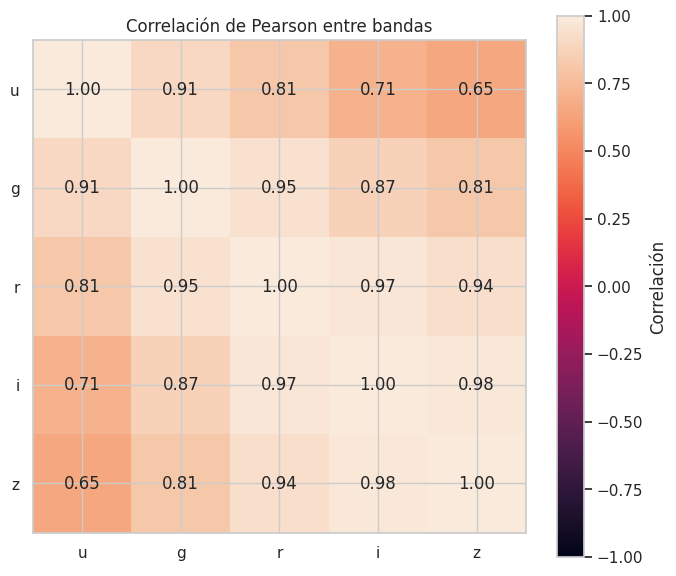

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    corr_bands,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(bands)))
ax.set_yticks(range(len(bands)))

ax.set_xticklabels(bands)
ax.set_yticklabels(bands)

for i in range(len(bands)):
    for j in range(len(bands)):
        ax.text(
            j,
            i,
            f"{corr_bands.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlación de Pearson entre bandas")

plt.colorbar(
    im,
    ax=ax,
    label="Correlación"
)

plt.tight_layout()
plt.show()

Se detectan correlaciones altas al comparar los brillos en las distintas bandas ya que un objeto que tiene alto brillo en una probablemente tambien lo tenga en las demas.

Los colores fotometricos eliminan parte de ese componente de brillo general y captura cómo cambia el brillo entre bandas, es decir, el color.
, esto resulta mas util para entrenar el modelo

## Colores Fotométricos
Los colores fotométricos son simplemente la diferencia entre las magnitudes medidas en dos filtros distintos.
Esto es util porque dos objetos pueden tener brillos absolutos muy diferentes, pero presentar patrones de color similares.
Los colores son, por lo tanto, features derivadas mediante feature engineering a partir de las magnitudes originales, y tienen una interpretación física muy clara.

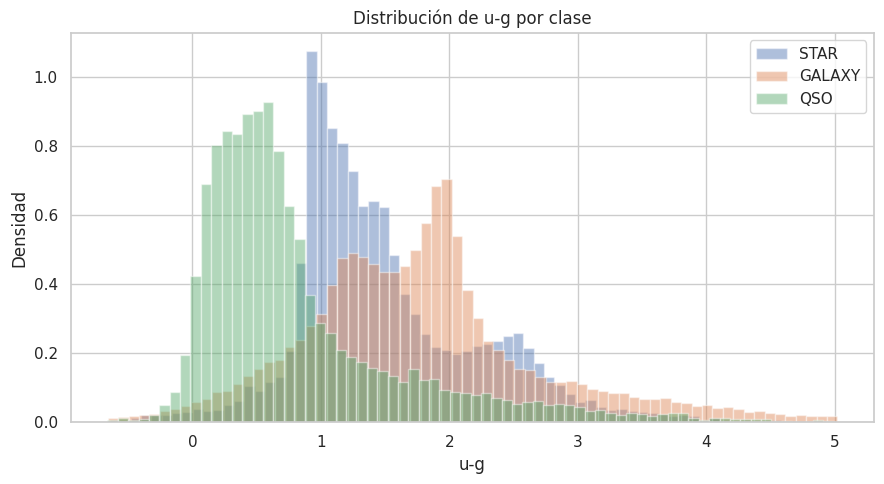

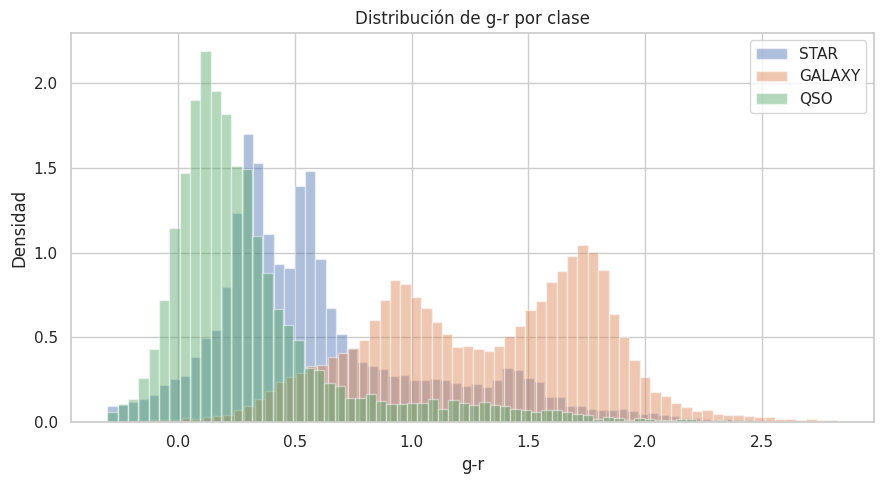

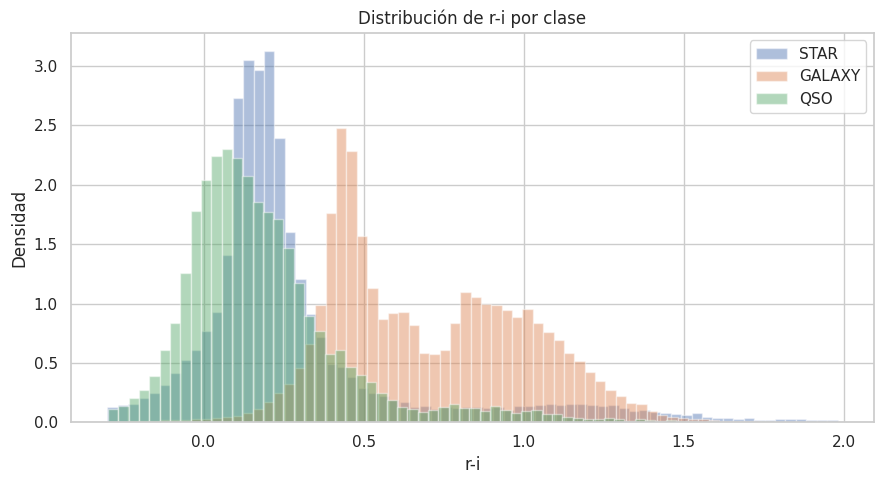

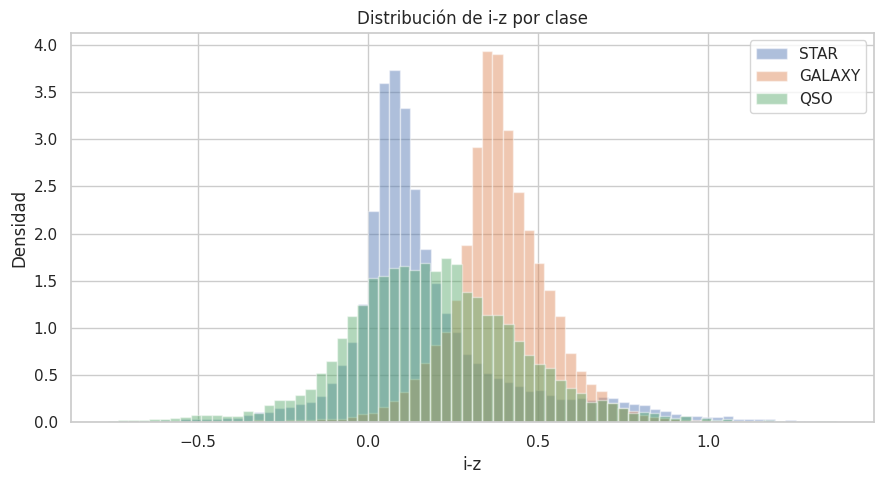

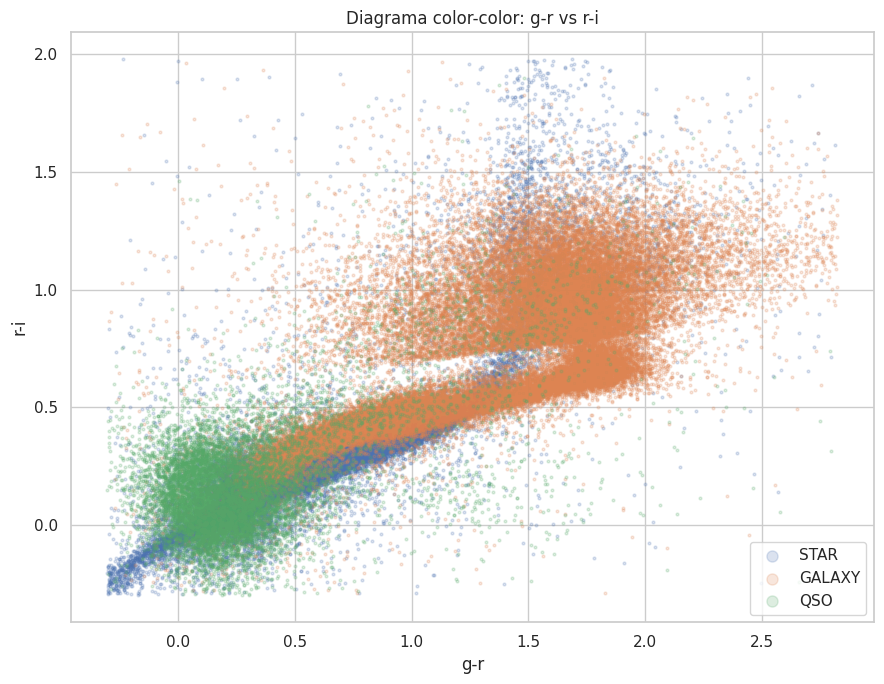

In [ ]:
# Crear colores fotométricos
df_clean["u-g"] = df_clean["u"] - df_clean["g"]
df_clean["g-r"] = df_clean["g"] - df_clean["r"]
df_clean["r-i"] = df_clean["r"] - df_clean["i"]
df_clean["i-z"] = df_clean["i"] - df_clean["z"]

colors = ["u-g", "g-r", "r-i", "i-z"]
classes = ["STAR", "GALAXY", "QSO"]

for color in colors:

    # Evitamos que valores extremos deformen el gráfico.
    # Solo se usa para visualizar, no se eliminan del dataset.
    lo, hi = df_clean[color].quantile([0.005, 0.995])

    fig, ax = plt.subplots(figsize=(9, 5))

    for cls in classes:

        values = df_clean.loc[
            df_clean["class"] == cls,
            color
        ]

        values = values[
            (values >= lo) &
            (values <= hi)
        ]

        ax.hist(
            values,
            bins=70,
            density=True,
            alpha=0.45,
            label=cls
        )

    ax.set_title(f"Distribución de {color} por clase")
    ax.set_xlabel(color)
    ax.set_ylabel("Densidad")
    ax.legend()

    plt.tight_layout()
    plt.show()
    plot_df = df_clean[
    df_clean["g-r"].between(
        *df_clean["g-r"].quantile([0.005, 0.995])
    )
    &
    df_clean["r-i"].between(
        *df_clean["r-i"].quantile([0.005, 0.995])
    )
]

fig, ax = plt.subplots(figsize=(9, 7))

for cls in classes:

    subset = plot_df[
        plot_df["class"] == cls
    ]

    ax.scatter(
        subset["g-r"],
        subset["r-i"],
        s=4,
        alpha=0.20,
        label=cls
    )

ax.set_title("Diagrama color-color: g-r vs r-i")
ax.set_xlabel("g-r")
ax.set_ylabel("r-i")

ax.legend(markerscale=4)

plt.tight_layout()
plt.show()

Las distribuciones de los índices de color muestran diferencias entre STAR, GALAXY y QSO. En particular, u-g permite observar una diferenciación importante de los QSO, mientras que g-r y r-i presentan una separación marcada de las galaxias respecto de las otras clases. Sin embargo, existe superposición entre las distribuciones, especialmente entre STAR y QSO, por lo que ningún índice de color individual parece suficiente para realizar una clasificación completa. Esto motiva utilizar conjuntamente los diferentes colores fotométricos como variables predictoras del modelo.
Los gráficos muestran que los colores fotométricos tienen capacidad para diferenciar STAR, GALAXY y QSO, aunque con distinto poder de separación según el color.Como consecuencia podemos entrenar dos modelos iguales, uno con u,g,r,i,z y otro con u-g,g-r,r-i,i-z, y comparar objetivamente cuál representación clasifica mejor.

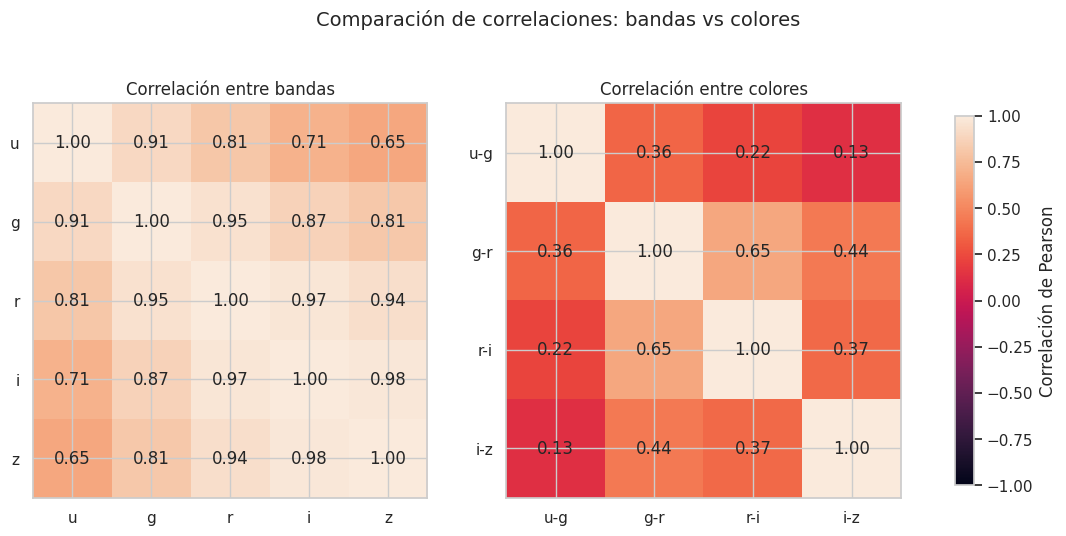

In [ ]:
# Comparacion de correlacion entre bandas y colores

corr_colors = df_clean[colors].corr(method="pearson")


# Crear gráficos lado a lado
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

# -------------------------
# Magnitudes u, g, r, i, z
# -------------------------

im1 = axes[0].imshow(
    corr_bands,
    vmin=-1,
    vmax=1
)

axes[0].set_xticks(range(len(bands)))
axes[0].set_yticks(range(len(bands)))

axes[0].set_xticklabels(bands)
axes[0].set_yticklabels(bands)

axes[0].set_title(
    "Correlación entre bandas"
)

# Valores dentro de las celdas
for i in range(len(bands)):
    for j in range(len(bands)):
        axes[0].text(
            j,
            i,
            f"{corr_bands.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )


# ---------------------------------
# Colores u-g, g-r, r-i, i-z
# ---------------------------------

im2 = axes[1].imshow(
    corr_colors,
    vmin=-1,
    vmax=1
)

axes[1].set_xticks(range(len(colors)))
axes[1].set_yticks(range(len(colors)))

axes[1].set_xticklabels(colors)
axes[1].set_yticklabels(colors)

axes[1].set_title(
    "Correlación entre colores"
)

# Valores dentro de las celdas
for i in range(len(colors)):
    for j in range(len(colors)):
        axes[1].text(
            j,
            i,
            f"{corr_colors.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )


# Una única escala para ambos gráficos
fig.colorbar(
    im2,
    ax=axes,
    label="Correlación de Pearson",
    shrink=0.8
)

plt.suptitle(
    "Comparación de correlaciones: bandas vs colores",
    fontsize=14
)

plt.show()

Los colores fotométricos presentan menor correlación entre sí, eso indica que aportan información menos redundante que las magnitudes originales.

In [ ]:
resultados = []

for clase in classes:

    datos_clase = df_clean[
        df_clean["class"] == clase
    ]

    for color in colors:

        # Cuartiles
        Q1 = datos_clase[color].quantile(0.25)
        Q3 = datos_clase[color].quantile(0.75)

        # Rango intercuartílico
        IQR = Q3 - Q1

        # Límites
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        # Detectar outliers
        outliers = datos_clase[
            (datos_clase[color] < limite_inferior) |
            (datos_clase[color] > limite_superior)
        ]

        # Guardar resultados
        resultados.append({
            "Clase": clase,
            "Color": color,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Limite inferior": limite_inferior,
            "Limite superior": limite_superior,
            "Registros": len(datos_clase),
            "Outliers": len(outliers),
            "% Outliers": 100 * len(outliers) / len(datos_clase)
        })


# ============================================================
# 5. Crear tabla de resultados
# ============================================================

tabla_outliers = pd.DataFrame(resultados)

print(
    tabla_outliers.round(3).to_string(index=False)
)

 Clase Color    Q1    Q3   IQR  Limite inferior  Limite superior  Registros  Outliers  % Outliers
  STAR   u-g 1.009 1.889 0.880           -0.310            3.209      30454      1014       3.330
  STAR   g-r 0.293 0.812 0.519           -0.486            1.591      30454      1663       5.461
  STAR   r-i 0.113 0.331 0.218           -0.214            0.658      30454      4642      15.243
  STAR   i-z 0.041 0.250 0.209           -0.272            0.564      30454      3772      12.386
GALAXY   u-g 1.185 2.176 0.991           -0.301            3.663      57537      3891       6.763
GALAXY   g-r 0.930 1.719 0.789           -0.253            2.902      57537       433       0.753
GALAXY   r-i 0.448 0.945 0.497           -0.297            1.691      57537       177       0.308
GALAXY   i-z 0.315 0.471 0.156            0.080            0.706      57537      3194       5.551
   QSO   u-g 0.301 1.032 0.731           -0.796            2.129      11918      1085       9.104
   QSO   g-r 0.082 0

Los límites IQR obtenidos también son interesantes. Por ejemplo, para STAR r-i, el rango considerado no-outlier es aproximadamente:

$$ -0.214 \le r-i \le 0.658 $$

y aun así 15,24% queda fuera. Esto es una señal fuerte de que no conviene eliminar automáticamente los outliers mediante IQR: la distribución real de esa clase puede tener colas o estructuras que IQR interpreta como extremas.

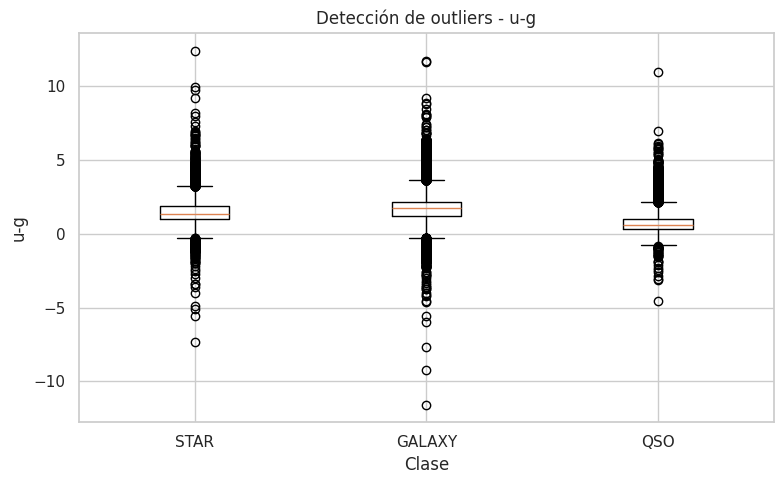

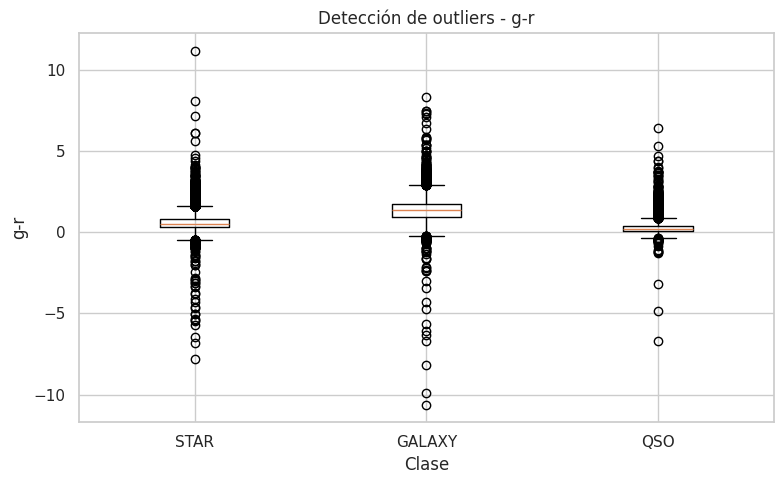

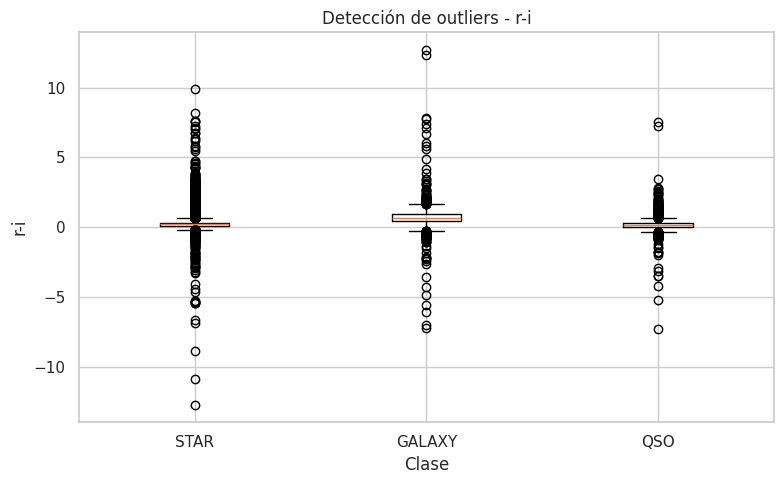

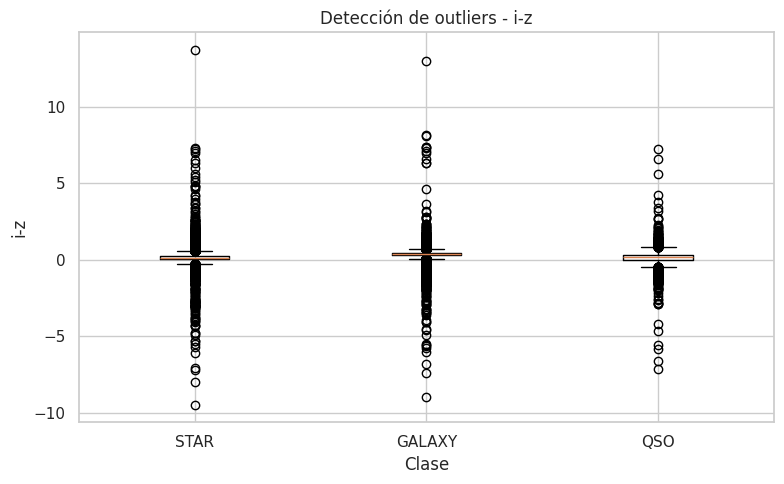

In [ ]:
for color in colors:

    datos = [
        df_clean.loc[
            df_clean["class"] == clase,
            color
        ]
        for clase in classes
    ]

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.boxplot(
        datos,
        tick_labels=classes,
        showfliers=True
    )

    ax.set_title(
        f"Detección de outliers - {color}"
    )

    ax.set_xlabel("Clase")
    ax.set_ylabel(color)

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# MARCAR OUTLIERS EN CADA OBSERVACIÓN
# ============================================================

# Creamos una columna booleana para cada color.
# La detección se realiza dentro de cada clase, utilizando
# el mismo criterio IQR aplicado en el análisis anterior.

for color in colors:

    columna_outlier = f"outlier_{color}"

    # Inicialmente ninguna observación está marcada como outlier
    df_clean[columna_outlier] = False

    for clase in classes:

        # Observaciones pertenecientes a la clase actual
        mask_clase = df_clean["class"] == clase

        datos_clase = df_clean.loc[mask_clase, color]

        # Cuartiles
        Q1 = datos_clase.quantile(0.25)
        Q3 = datos_clase.quantile(0.75)

        # Rango intercuartílico
        IQR = Q3 - Q1

        # Límites para identificar potenciales outliers
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        # Marcamos las observaciones que quedan fuera
        # de los límites correspondientes a su clase
        df_clean.loc[mask_clase, columna_outlier] = (
            (datos_clase < limite_inferior) |
            (datos_clase > limite_superior)
        )

# Verificamos que las columnas hayan sido creadas
print("Columnas de outliers creadas:")
print([
    f"outlier_{color}"
    for color in colors
])

Columnas de outliers creadas:
['outlier_u-g', 'outlier_g-r', 'outlier_r-i', 'outlier_i-z']


In [ ]:
columnas_outliers = [
    "outlier_u-g",
    "outlier_g-r",
    "outlier_r-i",
    "outlier_i-z"
]

df_clean["outlier_any"] = (
    df_clean[columnas_outliers].any(axis=1)
)

print(
    pd.crosstab(
        df_clean["class"],
        df_clean["outlier_any"]
    )
)

outlier_any  False  True 
class                    
GALAXY       50668   6869
QSO           9579   2339
STAR         24778   5676


Se identifican gran cantidad de outliers lo que indica que la categorizacion mediante IQR puede estar considerando como outlier valores validos para este dataset por ende no se eliminaran ningun registro de este tipo

### La física del problema, en tres números

El corrimiento al rojo medio de cada clase muestra por qué esta variable es tan informativa.

In [ ]:
df.groupby("class")["redshift"].describe()[["count", "mean", "min", "50%", "max"]]

,count,mean,min,50%,max
class,,,,,
GALAXY,57583.0,0.342837,-0.010932,0.353977,2.002617
QSO,11927.0,1.864913,0.000461,1.789044,7.021413
STAR,30490.0,0.000118,-0.004136,0.000085,0.004563


## Lo que sigue

Esta notebook se construye por partes, a medida que avanza la cursada. El estado de cada bloque:

| Bloque | Depende de | Estado |
|---|---|:--:|
| Fuente de los datos y propuesta de investigación | — | ✅ |
| Carga y estado del conjunto de datos | — | ✅ |
| Análisis exploratorio: distribuciones, colores fotométricos, correlaciones | clase 1 | ✅ |
| Preprocesamiento: valores nulos, duplicados | clase 1 | ✅ |
| Preprocesamiento: partición estratificada y dataset común de modelado | clase 1 | ⬜ |
| **KNN** como primera línea de base | clase 2 | ⬜ |
| **SVM** | clase 3 | ⬜ |
| **Árboles de decisión** | clase 4 | ⬜ |
| **Ensambles** e importancia de atributos | clase 5 | ⬜ |
| **Agrupamiento**: ¿recupera las tres clases? | clase 6 | ⬜ |
| **Calibración** sobre el corte binario quásar contra el resto | clase 7 | ⬜ |
| Requisito 4: comparación y justificación del algoritmo elegido | clases 2 a 5 | ⬜ |
| Requisito 7: reflexión y propuestas de mejora | todas | ⬜ |

## 1. Del EDA al problema de Machine Learning

El conjunto de datos tiene tres clases: `GALAXY`, `STAR` y `QSO`. Por lo tanto, estamos frente a un problema de **clasificación supervisada multiclase**.

La variable que queremos predecir es `class`. A partir del análisis exploratorio se identificaron diferentes representaciones de la información fotométrica y espectroscópica que pueden utilizarse como variables predictoras.

La pregunta central del trabajo es determinar cuánto de la clasificación puede explicarse a partir de la información fotométrica y cuánto aporta el `redshift`, que proviene de información espectroscópica.

Para estudiar esto de forma controlada, se definirán cuatro conjuntos de variables:

1. **Bandas:** `u`, `g`, `r`, `i`, `z`.

2. **Bandas + colores:** se agregan los colores fotométricos `u-g`, `g-r`, `r-i` e `i-z`, calculados durante el EDA.

3. **Bandas + redshift:** se agregan las bandas con el `redshift`.

4. **Bandas + colores + redshift:** se utiliza la combinación de todas las variables seleccionadas.

Esta estructura permite separar dos preguntas:

- **¿Los colores fotométricos mejoran la clasificación respecto de utilizar solamente las bandas originales?**
- **¿Cuánto aporta el `redshift` a la clasificación cuando se dispone de información fotométrica?**

El escenario sin `redshift` es especialmente relevante desde el punto de vista práctico, ya que la fotometría se obtiene a partir de imágenes, mientras que el `redshift` requiere información espectroscópica.

Los cuatro conjuntos de variables serán evaluados utilizando los mismos conjuntos de entrenamiento y prueba y las mismas métricas, de manera que las diferencias observadas puedan atribuirse a la información utilizada y no a cambios en la partición de los datos.


## 2. Variables y preparación

`objid` no se utiliza porque es un identificador. Tampoco utilizaremos `ra` y `dec`: describen la posición del objeto en el cielo y no son necesarias para estudiar la clasificación a partir de las características fotométricas.

Las variables predictoras se organizarán en cuatro conjuntos para poder comparar diferentes representaciones de la información disponible:

| Dataset | Bandas | Colores | Redshift |
|---|:---:|:---:|:---:|
| **D1 - Bandas** | ✓ | — | — |
| **D2 - Bandas + colores** | ✓ | ✓ | — |
| **D3 - Bandas + redshift** | ✓ | — | ✓ |
| **D4 - Bandas + colores + redshift** | ✓ | ✓ | ✓ |

Las bandas `u`, `g`, `r`, `i` y `z` corresponden a las magnitudes fotométricas originales.

Los colores `u-g`, `g-r`, `r-i` e `i-z` son variables derivadas mediante *feature engineering* a partir de las bandas originales. Durante el EDA se observó que presentan diferencias entre las clases, por lo que se incorporan como una segunda representación de la información fotométrica.

El `redshift` corresponde al corrimiento al rojo obtenido a partir de información espectroscópica. Se incorpora como una variable adicional para evaluar cuánto aporta respecto de las variables fotométricas. A simple vista, parecería ser una variable predictora por sí sola.

Los registros con `-9999` y los duplicados ya fueron tratados en la etapa de limpieza del EDA. Esta decisión no implica estimar ningún parámetro a partir de los datos de test: simplemente se eliminaron registros que no contienen una medición válida o que están repetidos.

A partir de este punto empieza el **preprocesamiento para Machine Learning**. Cualquier transformación que necesite aprender parámetros de los datos (por ejemplo, escalado o imputación) deberá ajustarse solamente sobre `train` y aplicarse después a `test`.

El escalado no se realizará en esta etapa. Se incorporará dentro del `Pipeline` de cada algoritmo cuando sea necesario, de manera que también quede incluido correctamente dentro de la validación cruzada.


In [ ]:
# ============================================================
# DEFINICIÓN DE LOS DATASETS PARA EL MODELADO
# ============================================================

# Variable objetivo
target = "class"

# ------------------------------------------------------------
# Variables fotométricas originales
# ------------------------------------------------------------

features_bands = [
    "u", "g", "r", "i", "z"
]

# ------------------------------------------------------------
# Variables derivadas: colores fotométricos
# ------------------------------------------------------------

features_colors = [
    "u-g", "g-r", "r-i", "i-z"
]

# ------------------------------------------------------------
# Variable espectroscópica
# ------------------------------------------------------------

features_redshift = [
    "redshift"
]

# ============================================================
# CUATRO CONJUNTOS DE VARIABLES QUE VAMOS A COMPARAR
# ============================================================

# D1 - Solo bandas
features_bands_only = features_bands

# D2 - Bandas + colores
features_bands_colors = features_bands + features_colors

# D3 - Bandas + redshift
features_bands_redshift = features_bands + features_redshift

# D4 - Bandas + colores + redshift
features_all = features_bands + features_colors + features_redshift


# ============================================================
# CREACIÓN DE LOS CUATRO DATASETS
# ============================================================

X_bands = df_clean[features_bands_only].copy()

X_bands_colors = df_clean[features_bands_colors].copy()

X_bands_redshift = df_clean[features_bands_redshift].copy()

X_all = df_clean[features_all].copy()

# Variable objetivo común a los cuatro experimentos
y_model = df_clean[target].copy()


# ============================================================
# RESUMEN
# ============================================================

print("D1 - Solo bandas")
print(features_bands_only)
print("Cantidad de variables:", len(features_bands_only))

print("\nD2 - Bandas + colores")
print(features_bands_colors)
print("Cantidad de variables:", len(features_bands_colors))

print("\nD3 - Bandas + redshift")
print(features_bands_redshift)
print("Cantidad de variables:", len(features_bands_redshift))

print("\nD4 - Bandas + colores + redshift")
print(features_all)
print("Cantidad de variables:", len(features_all))

print("\nCantidad de observaciones:", len(y_model))

print("\nDistribución de clases:")
print(y_model.value_counts())

D1 - Solo bandas
['u', 'g', 'r', 'i', 'z']
Cantidad de variables: 5

D2 - Bandas + colores
['u', 'g', 'r', 'i', 'z', 'u-g', 'g-r', 'r-i', 'i-z']
Cantidad de variables: 9

D3 - Bandas + redshift
['u', 'g', 'r', 'i', 'z', 'redshift']
Cantidad de variables: 6

D4 - Bandas + colores + redshift
['u', 'g', 'r', 'i', 'z', 'u-g', 'g-r', 'r-i', 'i-z', 'redshift']
Cantidad de variables: 10

Cantidad de observaciones: 99909

Distribución de clases:
class
GALAXY    57537
STAR      30454
QSO       11918
Name: count, dtype: int64


## 3. Separación entre entrenamiento y prueba

Antes de realizar transformaciones que aprendan información de los datos, separamos las observaciones en un conjunto de entrenamiento y un conjunto de prueba.

- **train**: se utiliza para ajustar los modelos y seleccionar hiperparámetros mediante validación cruzada.

- **test**: queda reservado para la evaluación final y no participa en la selección de hiperparámetros.

Utilizamos `stratify=y` para conservar aproximadamente la misma proporción de las tres clases en los conjuntos de entrenamiento y prueba.

Para que la comparación entre las diferentes representaciones de las variables sea consistente, realizamos **una única partición de las observaciones** y utilizamos los mismos índices de `train` y `test` para los cuatro datasets definidos anteriormente.

**Importante:** durante el EDA se detectaron valores faltantes, duplicados y posibles outliers. Los valores sin medición y los duplicados fueron eliminados durante la etapa de limpieza, antes de realizar la partición. Esto corresponde a una decisión de calidad de los datos y no implica aprender parámetros a partir del conjunto de prueba.

En cambio, cualquier transformación que necesite aprender parámetros de los datos —por ejemplo, calcular medias, desvíos, percentiles, umbrales o parámetros de escalado— debe realizarse exclusivamente utilizando `train`. Estas transformaciones se incorporarán posteriormente dentro de los `Pipeline` de cada modelo para evitar data leakage.


In [ ]:
# ============================================================
# PARTICIÓN TRAIN / TEST COMÚN A TODOS LOS DATASETS
# ============================================================

from sklearn.model_selection import train_test_split

# Se genera una única partición de índices.
# Todos los datasets utilizarán exactamente las mismas
# observaciones en train y test.

idx_train, idx_test = train_test_split(
    df_clean.index,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)


# ============================================================
# DATASET 1 - SOLO BANDAS
# ============================================================

X_bands_train = X_bands.loc[idx_train]
X_bands_test = X_bands.loc[idx_test]


# ============================================================
# DATASET 2 - BANDAS + COLORES
# ============================================================

X_bands_colors_train = X_bands_colors.loc[idx_train]
X_bands_colors_test = X_bands_colors.loc[idx_test]


# ============================================================
# DATASET 3 - BANDAS + REDSHIFT
# ============================================================

X_bands_redshift_train = X_bands_redshift.loc[idx_train]
X_bands_redshift_test = X_bands_redshift.loc[idx_test]


# ============================================================
# DATASET 4 - BANDAS + COLORES + REDSHIFT
# ============================================================

X_all_train = X_all.loc[idx_train]
X_all_test = X_all.loc[idx_test]


# ============================================================
# VARIABLE OBJETIVO
# ============================================================

y_train_model = y_model.loc[idx_train]
y_test_model = y_model.loc[idx_test]


# ============================================================
# VERIFICACIÓN
# ============================================================

print("Cantidad de observaciones:")
print("Train:", len(idx_train))
print("Test :", len(idx_test))

print("\nDimensiones de cada dataset:")

print("\nD1 - Solo bandas:")
print("Train:", X_bands_train.shape)
print("Test :", X_bands_test.shape)

print("\nD2 - Bandas + colores:")
print("Train:", X_bands_colors_train.shape)
print("Test :", X_bands_colors_test.shape)

print("\nD3 - Bandas + redshift:")
print("Train:", X_bands_redshift_train.shape)
print("Test :", X_bands_redshift_test.shape)

print("\nD4 - Bandas + colores + redshift:")
print("Train:", X_all_train.shape)
print("Test :", X_all_test.shape)

print("\nProporción de clases en train:")
print(y_train_model.value_counts(normalize=True).round(3))

print("\nProporción de clases en test:")
print(y_test_model.value_counts(normalize=True).round(3))


Cantidad de observaciones:
Train: 79927
Test : 19982

Dimensiones de cada dataset:

D1 - Solo bandas:
Train: (79927, 5)
Test : (19982, 5)

D2 - Bandas + colores:
Train: (79927, 9)
Test : (19982, 9)

D3 - Bandas + redshift:
Train: (79927, 6)
Test : (19982, 6)

D4 - Bandas + colores + redshift:
Train: (79927, 10)
Test : (19982, 10)

Proporción de clases en train:
class
GALAXY    0.576
STAR      0.305
QSO       0.119
Name: proportion, dtype: float64

Proporción de clases en test:
class
GALAXY    0.576
STAR      0.305
QSO       0.119
Name: proportion, dtype: float64


# Dataset final preparado para comenzar el modelado

En este punto dejamos preparados los datos que se utilizarán en los modelos de clasificación.

Para analizar de forma controlada qué información aporta cada tipo de variable, decidimos trabajar con **cuatro conjuntos de variables predictoras**:

1. **D1 - Bandas:** `u`, `g`, `r`, `i`, `z`
2. **D2 - Bandas + colores:** bandas + `u-g`, `g-r`, `r-i`, `i-z`
3. **D3 - Bandas + redshift:** bandas + `redshift`
4. **D4 - Bandas + colores + redshift:** bandas + colores + `redshift`

### ¿Por qué separar el problema en cuatro datasets?

Los cuatro datasets representan **el mismo problema de clasificación**, utilizando exactamente las mismas observaciones y la misma variable objetivo (`class`). La diferencia entre ellos está únicamente en la información utilizada como variables predictoras.

Esta separación nos permite responder de manera más clara las preguntas planteadas en el trabajo:

- comparar **D1 vs. D2** permite evaluar si incorporar los colores fotométricos aporta información adicional respecto de utilizar solamente las bandas originales;
- comparar **D1 vs. D3** permite analizar cuánto aporta el `redshift` a partir de la información fotométrica;
- comparar **D2 vs. D4** permite evaluar si el `redshift` aporta información adicional cuando ya contamos con bandas y colores;
- comparar **D1 vs. D4** permite observar el efecto de incorporar conjuntamente todas las variables consideradas.

De esta manera, no buscamos construir cuatro modelos diferentes para problemas diferentes, sino **evaluar distintas representaciones del mismo problema de clasificación**.

### Una única partición para los cuatro datasets

Para que la comparación sea reproducible y consistente, los cuatro datasets utilizan **exactamente las mismas observaciones para `train` y `test`**.

En lugar de realizar cuatro particiones independientes, primero se genera una única partición estratificada de los índices y luego esos mismos índices se aplican a cada dataset.

Por lo tanto:

- las observaciones de `train` son las mismas en D1, D2, D3 y D4;
- las observaciones de `test` son las mismas en D1, D2, D3 y D4;
- la variable objetivo es la misma en todos los casos;
- la semilla aleatoria utilizada para generar la partición es fija.

Esto permite que las diferencias observadas entre los experimentos se relacionen con las **variables utilizadas como entrada** y no con que cada modelo haya recibido una partición diferente de los datos.

Además, al mantener una única partición y una estructura de experimentación común, el procedimiento resulta **reproducible**: cualquier ejecución posterior del notebook, utilizando los mismos datos y parámetros, puede reconstruir los mismos conjuntos de entrenamiento y prueba.

### Preparación para el modelado

A partir de este punto, cada algoritmo será evaluado sobre los cuatro datasets utilizando el mismo esquema general de entrenamiento, validación y evaluación.

Los datasets preparados son:

- **D1:** `X_bands_train` / `X_bands_test`
- **D2:** `X_bands_colors_train` / `X_bands_colors_test`
- **D3:** `X_bands_redshift_train` / `X_bands_redshift_test`
- **D4:** `X_all_train` / `X_all_test`

La variable objetivo es común a todos:

- `y_train_model`
- `y_test_model`

El conjunto `test` queda reservado para la evaluación final y no se utilizará para seleccionar hiperparámetros.

El escalado de variables se incorporará dentro del `Pipeline` de cada algoritmo cuando corresponda. De esta manera, también durante la validación cruzada se evita utilizar información del conjunto de validación para ajustar las transformaciones.


## Criterio que utilizaremos para decidir el escalado

La decisión no se toma porque "es una buena práctica escalar siempre", sino por las características matemáticas del algoritmo.

- **Modelos basados en distancias:** el escalado es importante porque una variable con mayor magnitud puede dominar la distancia.
- **Modelos cuyo funcionamiento depende de productos internos, márgenes o magnitudes de las variables:** el escalado suele ser importante.
- **Modelos basados en reglas de partición por umbrales:** el escalado generalmente no modifica la información disponible para encontrar las particiones y, por lo tanto, no es necesario.

La decisión concreta queda documentada antes de cada modelo.


# Baseline: clasificación utilizando únicamente `redshift`

Antes de aplicar algoritmos de Machine Learning, definimos un **baseline** que nos permita establecer una referencia sencilla y reproducible para el problema de clasificación.

La idea es evaluar cuánto puede lograrse utilizando únicamente el `redshift`, sin utilizar las bandas fotométricas, los colores ni un algoritmo de aprendizaje como KNN o SVM.

Como tenemos tres clases, utilizaremos dos umbrales para dividir el rango de `redshift` en tres regiones:

$$
redshift < T_1 \quad \rightarrow \quad STAR
$$

$$
T_1 \leq redshift < T_2 \quad \rightarrow \quad GALAXY
$$

$$
redshift \geq T_2 \quad \rightarrow \quad QSO
$$

Los umbrales no se definirán utilizando el conjunto de test. Para evitar utilizar información del conjunto reservado, se calcularán exclusivamente a partir de las observaciones de `train`.

Como regla sencilla e interpretable, calcularemos primero la mediana del `redshift` para cada clase en el conjunto de entrenamiento.

Luego definiremos cada umbral como el punto medio entre las medianas de las clases consecutivas:

$$
T_1 =
\frac{\text{mediana(STAR)}+\text{mediana(GALAXY)}}{2}
$$

$$
T_2 =
\frac{\text{mediana(GALAXY)}+\text{mediana(QSO)}}{2}
$$

De esta manera, el baseline utiliza únicamente una regla basada en `redshift`, sin optimizar los umbrales utilizando el conjunto de test.

Posteriormente aplicaremos esta regla al conjunto de test y evaluaremos su desempeño utilizando las mismas métricas que utilizaremos para los modelos de Machine Learning.

Este baseline nos permitirá establecer una referencia simple para analizar cuánto aporta posteriormente el uso de algoritmos de Machine Learning y de diferentes conjuntos de variables.

Es importante aclarar que, aunque el baseline utiliza únicamente `redshift` como variable predictora, los umbrales se construyen utilizando las clases conocidas del conjunto de entrenamiento. Por lo tanto, se trata de una regla supervisada simple.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
# ============================================================
# BASELINE - MEDIANAS DE REDSHIFT EN TRAIN
# ============================================================

medianas_redshift = (
    pd.DataFrame({
        "redshift": X_bands_redshift_train["redshift"],
        "class": y_train_model
    })
    .groupby("class")["redshift"]
    .median()
)

print("Mediana de redshift por clase - TRAIN:")
print(medianas_redshift)

Mediana de redshift por clase - TRAIN:
class
GALAXY    0.354970
QSO       1.784589
STAR      0.000085
Name: redshift, dtype: float64


In [ ]:
# ============================================================
# BASELINE - CÁLCULO DE LOS UMBRALES
# ============================================================

T1 = (
    medianas_redshift["STAR"] +
    medianas_redshift["GALAXY"]
) / 2

T2 = (
    medianas_redshift["GALAXY"] +
    medianas_redshift["QSO"]
) / 2

print(f"Umbral T1 (STAR / GALAXY): {T1:.6f}")
print(f"Umbral T2 (GALAXY / QSO): {T2:.6f}")

Umbral T1 (STAR / GALAXY): 0.177527
Umbral T2 (GALAXY / QSO): 1.069779


In [ ]:
# ============================================================
# BASELINE - PREDICCIONES SOBRE TEST
# ============================================================

redshift_test = X_bands_redshift_test["redshift"]

y_pred_baseline = np.select(
    [
        redshift_test < T1,
        redshift_test < T2
    ],
    [
        "STAR",
        "GALAXY"
    ],
    default="QSO"
)

print("Primeras predicciones del baseline:")
print(y_pred_baseline[:10])

Primeras predicciones del baseline:
['STAR' 'STAR' 'GALAXY' 'STAR' 'STAR' 'STAR' 'GALAXY' 'GALAXY' 'GALAXY'
 'STAR']


In [ ]:
# ============================================================
# BASELINE - DISTRIBUCIÓN DE PREDICCIONES
# ============================================================

print("Distribución de las predicciones del baseline:")
print(
    pd.Series(y_pred_baseline)
    .value_counts()
)

Distribución de las predicciones del baseline:
STAR      10297
GALAXY     7869
QSO        1816
Name: count, dtype: int64


In [ ]:
# ============================================================
# BASELINE - MÉTRICAS SOBRE TEST
# ============================================================

accuracy_baseline = accuracy_score(
    y_test_model,
    y_pred_baseline
)

precision_baseline = precision_score(
    y_test_model,
    y_pred_baseline,
    average="weighted",
    zero_division=0
)

recall_baseline = recall_score(
    y_test_model,
    y_pred_baseline,
    average="weighted",
    zero_division=0
)

f1_weighted_baseline = f1_score(
    y_test_model,
    y_pred_baseline,
    average="weighted",
    zero_division=0
)

f1_macro_baseline = f1_score(
    y_test_model,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

print("Baseline - Solo redshift")
print("-" * 40)
print(f"Accuracy:          {accuracy_baseline:.4f}")
print(f"Precision weighted: {precision_baseline:.4f}")
print(f"Recall weighted:    {recall_baseline:.4f}")
print(f"F1 weighted:        {f1_weighted_baseline:.4f}")
print(f"F1 macro:           {f1_macro_baseline:.4f}")

Baseline - Solo redshift
----------------------------------------
Accuracy:          0.7608
Precision weighted: 0.8336
Recall weighted:    0.7608
F1 weighted:        0.7634
F1 macro:           0.7843


In [ ]:
# ============================================================
# BASELINE - CLASSIFICATION REPORT
# ============================================================

print("Baseline - Solo redshift")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_baseline,
        digits=4,
        zero_division=0
    )
)

Baseline - Solo redshift
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9299    0.6359    0.7553     11507
         QSO     0.9879    0.7525    0.8543      2384
        STAR     0.5915    1.0000    0.7433      6091

    accuracy                         0.7608     19982
   macro avg     0.8364    0.7961    0.7843     19982
weighted avg     0.8336    0.7608    0.7634     19982



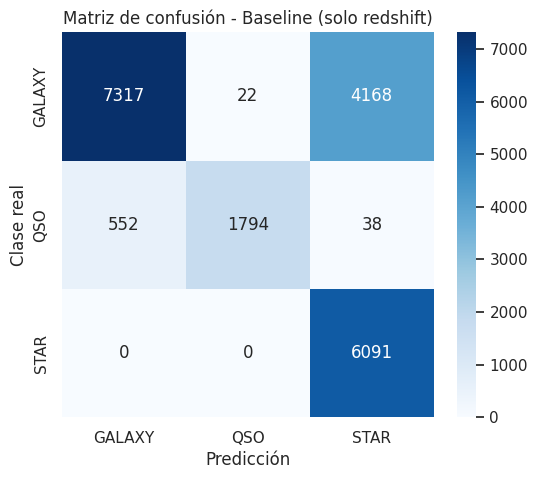

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_baseline = confusion_matrix(
    y_test_model,
    y_pred_baseline,
    labels=["GALAXY", "QSO", "STAR"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["GALAXY", "QSO", "STAR"],
    yticklabels=["GALAXY", "QSO", "STAR"]
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title("Matriz de confusión - Baseline (solo redshift)")
plt.show()

### Matriz de confusión del baseline

La matriz de confusión permite observar con mayor detalle cómo se distribuyen los aciertos y errores entre las tres clases.

Las filas representan la **clase real** y las columnas la **clase predicha**. Por lo tanto, los valores de la diagonal corresponden a las observaciones clasificadas correctamente.

Esta matriz permite complementar las métricas obtenidas anteriormente y analizar qué clases tienden a confundirse entre sí.

En particular, el baseline identifica correctamente todas las observaciones de `STAR`, consistente con su recall de **1.0000**. Sin embargo, esto no significa que todas las observaciones clasificadas como `STAR` sean realmente estrellas, lo que se refleja en su precision de **0.5915**.

### Interpretación del baseline

El baseline basado exclusivamente en `redshift` alcanza una accuracy de **0.7608** y un F1 weighted de **0.7634**.

Estos resultados muestran que el `redshift` contiene información relevante para distinguir las tres clases incluso sin utilizar las bandas fotométricas ni los colores.

Sin embargo, el desempeño no es uniforme entre las clases. El recall de `STAR` alcanza **1.0000**, lo que significa que todas las estrellas del conjunto de test fueron identificadas por la regla. En cambio, su precision es **0.5915**, indicando que una proporción importante de los objetos clasificados como STAR pertenecen en realidad a otras clases.

Para `QSO`, la precision es muy alta (**0.9879**), mientras que el recall es **0.7525**. Esto indica que, cuando la regla predice QSO, la predicción suele ser correcta, aunque no identifica todos los QSO.

En `GALAXY`, el recall es **0.6359**, mostrando que una parte importante de las galaxias no es identificada correctamente por esta regla basada únicamente en dos umbrales de `redshift`.

Este baseline constituye una referencia sencilla frente a la cual podremos evaluar los modelos de Machine Learning. En particular, nos permitirá analizar posteriormente cuánto mejora la clasificación cuando, además de `redshift`, se incorporan las bandas fotométricas y los colores, y cuando se utiliza un algoritmo que aprende la relación entre las variables y la clase.

Es importante señalar que este baseline utiliza una regla heurística definida a partir de las medianas de `redshift` del conjunto de entrenamiento. Los umbrales no fueron optimizados utilizando el conjunto de test.

# 4. Modelado: K-Nearest Neighbors (KNN)



## 4.1. ¿Cómo funciona KNN?

**K-Nearest Neighbors (KNN)** es un algoritmo de aprendizaje supervisado basado en ejemplos.

Para clasificar una nueva observación, KNN:

1. calcula la distancia entre la nueva observación y las observaciones del conjunto de entrenamiento;
2. identifica las `K` observaciones más cercanas;
3. utiliza las clases de esos vecinos para determinar la clase predicha.

En clasificación, la predicción se obtiene mediante el voto de los vecinos. El voto puede ser:

- **uniforme:** todos los vecinos tienen el mismo peso;
- **ponderado por distancia:** los vecinos más cercanos tienen mayor influencia.

Una característica importante de KNN es que no supone una forma determinada para la frontera de decisión. La clasificación se construye a partir de la distribución de las observaciones en el espacio de variables.

En nuestro problema, cada objeto astronómico puede representarse como un punto en un espacio cuyas dimensiones corresponden a las variables utilizadas. KNN buscará objetos similares en ese espacio y utilizará sus clases conocidas para clasificar nuevos objetos.

## 4.2. ¿Por qué debemos escalar las variables?

KNN está basado en distancias. Por lo tanto, la escala de las variables puede modificar directamente qué observaciones se consideran cercanas.

Si una variable tiene valores numéricamente mucho mayores que otra, puede tener una influencia desproporcionada sobre la distancia, aunque eso no implique que sea más importante para la clasificación.

Por este motivo, utilizaremos `StandardScaler` antes de aplicar KNN.

La estandarización transforma cada variable según:

$$
z = \frac{x-\mu}{\sigma}
$$

donde:

- $x$ es el valor original de la variable;
- $\mu$ es la media de la variable calculada sobre el conjunto de entrenamiento;
- $\sigma$ es el desvío estándar calculado sobre el conjunto de entrenamiento;
- $z$ es el valor estandarizado.

El escalado se incorporará dentro de un `Pipeline` junto con KNN. Esto es importante porque, durante la validación cruzada, el `StandardScaler` debe ajustarse utilizando únicamente los datos de entrenamiento de cada fold.

De esta manera evitamos que la información de los datos utilizados para validar influya en el cálculo del escalado.

## 4.3. Hiperparámetros de KNN

Los principales hiperparámetros que evaluaremos son:

- `n_neighbors`: cantidad de vecinos utilizados para realizar la predicción.
- `weights`: forma en que cada vecino contribuye al voto.
- `p`: parámetro de la distancia de Minkowski.

Para la distancia de Minkowski:

- `p = 1` corresponde a la distancia Manhattan;
- `p = 2` corresponde a la distancia Euclídea.

Evaluaremos diferentes combinaciones mediante `GridSearchCV`.

La selección de hiperparámetros se realizará utilizando únicamente el conjunto de entrenamiento mediante validación cruzada. El conjunto de test permanecerá reservado para la evaluación final.

## 4.4. Estrategia de evaluación de KNN

KNN se evaluará sobre los cuatro datasets definidos anteriormente:

- **D1:** bandas
- **D2:** bandas + colores
- **D3:** bandas + redshift
- **D4:** bandas + colores + redshift

Para los cuatro experimentos utilizaremos:

- la misma partición `train/test`;
- la misma variable objetivo;
- la misma cantidad de folds en la validación cruzada;
- la misma métrica para seleccionar hiperparámetros;
- el mismo esquema de búsqueda de hiperparámetros.

De esta manera, el único elemento que cambia entre los experimentos es el conjunto de variables utilizado como entrada.

La métrica utilizada para seleccionar los hiperparámetros será **F1-score ponderado (`f1_weighted`)**, teniendo en cuenta que las clases no están perfectamente balanceadas.

Una vez seleccionado el mejor conjunto de hiperparámetros utilizando exclusivamente `train`, el modelo correspondiente a cada dataset será evaluado sobre `test`.

Además de F1 ponderado, calcularemos:

- accuracy;
- precision ponderada;
- recall ponderado;
- F1 ponderado;
- F1 macro;
- matriz de confusión;
- classification report.

Esto permitirá analizar no solamente el rendimiento global, sino también cómo se comporta el modelo frente a cada una de las tres clases.

In [ ]:
# ============================================================
# KNN - IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
# ============================================================
# KNN - PIPELINE
# ============================================================

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_pipeline

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

In [ ]:
# ============================================================
# KNN - GRILLA DE HIPERPARÁMETROS
# ============================================================

knn_param_grid = {
    "model__n_neighbors": np.arange(3, 22, 2),
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

knn_param_grid

{'model__n_neighbors': array([ 3,  5,  7,  9, 11, 13, 15, 17, 19, 21]),
 'model__weights': ['uniform', 'distance'],
 'model__p': [1, 2]}

## 4.6. Selección de hiperparámetros mediante validación cruzada

Para seleccionar los hiperparámetros de KNN utilizaremos `GridSearchCV`.

La búsqueda se realizará únicamente sobre el conjunto de entrenamiento y mediante **validación cruzada de 5 folds**.

En cada combinación de hiperparámetros:

1. el conjunto de entrenamiento se divide en 5 partes;
2. se entrenan los modelos utilizando 4 partes;
3. se evalúa el modelo sobre la parte restante;
4. el proceso se repite hasta utilizar cada parte como validación;
5. se calcula el promedio del `F1-score ponderado` obtenido en los 5 folds.

El `StandardScaler` forma parte del `Pipeline`, por lo que se ajusta nuevamente dentro de cada fold utilizando solamente los datos correspondientes al entrenamiento de ese fold.

Finalmente, se selecciona la combinación de hiperparámetros que obtiene el mayor `F1-score ponderado` promedio.

### D1

In [ ]:
# ============================================================
# KNN - ENTRENAMIENTO D1: SOLO BANDAS
# ============================================================

knn_grid_d1 = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

knn_grid_d1.fit(
    X_bands_train,
    y_train_model
)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'model__n_neighbors': array([ 3,  5,  7,  9, 11, 13, 15, 17, 19, 21]),
                         'model__p': [1, 2],
                         'model__weights': ['uniform', 'distance']},
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D1
# ============================================================

print("Mejores hiperparámetros para D1 - Solo bandas:")
print(knn_grid_d1.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(knn_grid_d1.best_score_, 4))

Mejores hiperparámetros para D1 - Solo bandas:
{'model__n_neighbors': np.int64(9), 'model__p': 2, 'model__weights': 'distance'}

Mejor F1 ponderado promedio en validación cruzada:
0.8919


In [ ]:
# ============================================================
# KNN - EVALUACIÓN D1 SOBRE TEST
# ============================================================

y_pred_knn_d1 = knn_grid_d1.best_estimator_.predict(
    X_bands_test
)

In [ ]:
# ============================================================
# KNN - MÉTRICAS D1 SOBRE TEST
# ============================================================

accuracy_d1 = accuracy_score(
    y_test_model,
    y_pred_knn_d1
)

precision_d1 = precision_score(
    y_test_model,
    y_pred_knn_d1,
    average="weighted",
    zero_division=0
)

recall_d1 = recall_score(
    y_test_model,
    y_pred_knn_d1,
    average="weighted",
    zero_division=0
)

f1_weighted_d1 = f1_score(
    y_test_model,
    y_pred_knn_d1,
    average="weighted",
    zero_division=0
)

f1_macro_d1 = f1_score(
    y_test_model,
    y_pred_knn_d1,
    average="macro",
    zero_division=0
)

print("KNN - D1: Solo bandas")
print("-" * 35)
print(f"Accuracy:          {accuracy_d1:.4f}")
print(f"Precision weighted: {precision_d1:.4f}")
print(f"Recall weighted:    {recall_d1:.4f}")
print(f"F1 weighted:        {f1_weighted_d1:.4f}")
print(f"F1 macro:           {f1_macro_d1:.4f}")

KNN - D1: Solo bandas
-----------------------------------
Accuracy:          0.8985
Precision weighted: 0.8970
Recall weighted:    0.8985
F1 weighted:        0.8972
F1 macro:           0.8502


In [ ]:
# ============================================================
# KNN - CLASSIFICATION REPORT D1
# ============================================================

print("KNN - D1: Solo bandas")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_knn_d1,
        digits=4,
        zero_division=0
    )
)

KNN - D1: Solo bandas
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9423    0.9523    0.9473     11507
         QSO     0.7974    0.6883    0.7389      2384
        STAR     0.8505    0.8790    0.8645      6091

    accuracy                         0.8985     19982
   macro avg     0.8634    0.8399    0.8502     19982
weighted avg     0.8970    0.8985    0.8972     19982



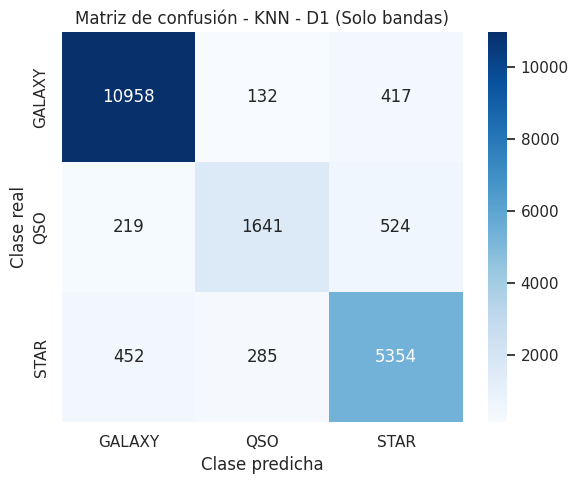

In [ ]:
# ============================================================
# KNN - MATRIZ DE CONFUSIÓN D1
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

labels = ["GALAXY", "QSO", "STAR"]

cm_d1 = confusion_matrix(
    y_test_model,
    y_pred_knn_d1,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_d1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - KNN - D1 (Solo bandas)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

#### Interpretación de la matriz de confusión

La matriz de confusión muestra que el modelo presenta un desempeño diferente según la clase.

La clase `GALAXY` es la que presenta mayor cantidad de clasificaciones correctas en términos relativos, mientras que `QSO` presenta la mayor dificultad de clasificación.

En particular, se observa que una parte importante de los objetos `QSO` son clasificados como `STAR`, lo que es consistente con el menor recall obtenido para esta clase.

Estas confusiones serán especialmente relevantes al comparar posteriormente qué ocurre al incorporar los colores fotométricos y el `redshift`.

### D2


In [ ]:
# ============================================================
# KNN - ENTRENAMIENTO D2: Bandas y colores
# ============================================================

knn_grid_d2 = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

knn_grid_d2.fit(
    X_bands_colors_train,
    y_train_model
)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'model__n_neighbors': array([ 3,  5,  7,  9, 11, 13, 15, 17, 19, 21]),
                         'model__p': [1, 2],
                         'model__weights': ['uniform', 'distance']},
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D2
# ============================================================

print("Mejores hiperparámetros para D2 - Solo bandas:")
print(knn_grid_d2.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(knn_grid_d2.best_score_, 4))

Mejores hiperparámetros para D2 - Solo bandas:
{'model__n_neighbors': np.int64(9), 'model__p': 2, 'model__weights': 'distance'}

Mejor F1 ponderado promedio en validación cruzada:
0.9058


In [ ]:
# ============================================================
# KNN - EVALUACIÓN D2 SOBRE TEST
# ============================================================

y_pred_knn_d2 = knn_grid_d2.best_estimator_.predict(
    X_bands_colors_test
)

In [ ]:
# ============================================================
# KNN - MÉTRICAS D2 SOBRE TEST
# ============================================================

accuracy_d2 = accuracy_score(
    y_test_model,
    y_pred_knn_d2
)

precision_d2 = precision_score(
    y_test_model,
    y_pred_knn_d2,
    average="weighted",
    zero_division=0
)

recall_d2 = recall_score(
    y_test_model,
    y_pred_knn_d2,
    average="weighted",
    zero_division=0
)

f1_weighted_d2 = f1_score(
    y_test_model,
    y_pred_knn_d2,
    average="weighted",
    zero_division=0
)

f1_macro_d2 = f1_score(
    y_test_model,
    y_pred_knn_d2,
    average="macro",
    zero_division=0
)

print("KNN - D2: Bandas y colores")
print("-" * 35)
print(f"Accuracy:          {accuracy_d2:.4f}")
print(f"Precision weighted: {precision_d2:.4f}")
print(f"Recall weighted:    {recall_d2:.4f}")
print(f"F1 weighted:        {f1_weighted_d2:.4f}")
print(f"F1 macro:           {f1_macro_d2:.4f}")

KNN - D2: Bandas y colores
-----------------------------------
Accuracy:          0.9091
Precision weighted: 0.9075
Recall weighted:    0.9091
F1 weighted:        0.9079
F1 macro:           0.8629


In [ ]:
# ============================================================
# KNN - CLASSIFICATION REPORT D2
# ============================================================

print("KNN - D2: Bandas y colores")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_knn_d2,
        digits=4,
        zero_division=0
    )
)

KNN - D2: Bandas y colores
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9483    0.9609    0.9545     11507
         QSO     0.8020    0.7118    0.7542      2384
        STAR     0.8719    0.8884    0.8801      6091

    accuracy                         0.9091     19982
   macro avg     0.8741    0.8537    0.8629     19982
weighted avg     0.9075    0.9091    0.9079     19982



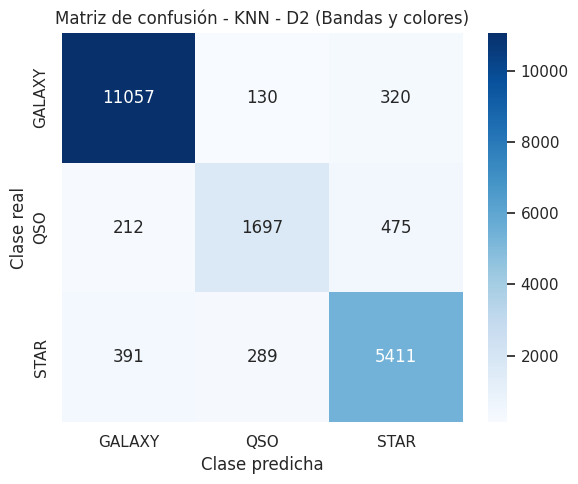

In [ ]:
# ============================================================
# KNN - MATRIZ DE CONFUSIÓN D2
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

labels = ["GALAXY", "QSO", "STAR"]

cm_d2 = confusion_matrix(
    y_test_model,
    y_pred_knn_d2,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_d2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - KNN - D2 (Bandas y colores)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

#### Comparación D1 vs. D2: incorporación de colores fotométricos

Al comparar D1 (bandas) con D2 (bandas + colores), se observa una mejora en todas las métricas evaluadas sobre el conjunto de test.

El F1 ponderado pasó de 0.8972 en D1 a 0.9079 en D2, mientras que el F1 macro pasó de 0.8502 a 0.8629.

La mejora también se observa al analizar las clases individualmente. El F1 de `GALAXY` pasó de 0.9473 a 0.9545, el de `STAR` de 0.8645 a 0.8801 y el de `QSO` de 0.7389 a 0.7542.

En particular, `QSO` continúa siendo la clase con menor desempeño, pero su recall aumenta de 0.6883 a 0.7118. La matriz de confusión muestra además una reducción de las confusiones entre `QSO` y `STAR`.

Los hiperparámetros seleccionados fueron los mismos para D1 y D2 (`K = 9`, distancia Euclídea y ponderación por distancia). Por lo tanto, en este experimento la diferencia observada en el desempeño está asociada a la incorporación de los colores fotométricos como variables predictoras.

Este resultado indica que los colores aportan información útil para la clasificación respecto de utilizar únicamente las bandas originales. Sin embargo, los colores son variables derivadas de las propias bandas, por lo que no representan una nueva fuente de información observacional independiente, sino una transformación de la información fotométrica disponible.

### D3

In [ ]:
# ============================================================
# KNN - ENTRENAMIENTO D3: Bandas y colores
# ============================================================

knn_grid_d3 = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

knn_grid_d3.fit(
    X_bands_redshift_train,
    y_train_model
)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'model__n_neighbors': array([ 3,  5,  7,  9, 11, 13, 15, 17, 19, 21]),
                         'model__p': [1, 2],
                         'model__weights': ['uniform', 'distance']},
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D3
# ============================================================

print("Mejores hiperparámetros para D3 - Bandas y redshift:")
print(knn_grid_d3.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(knn_grid_d3.best_score_, 4))

Mejores hiperparámetros para D3 - Bandas y redshift:
{'model__n_neighbors': np.int64(5), 'model__p': 1, 'model__weights': 'distance'}

Mejor F1 ponderado promedio en validación cruzada:
0.9725


In [ ]:
# ============================================================
# KNN - EVALUACIÓN D3 SOBRE TEST
# ============================================================

y_pred_knn_d3 = knn_grid_d3.best_estimator_.predict(
    X_bands_redshift_test
)

In [ ]:
# ============================================================
# KNN - MÉTRICAS D3 SOBRE TEST
# ============================================================

accuracy_d3 = accuracy_score(
    y_test_model,
    y_pred_knn_d3
)

precision_d3 = precision_score(
    y_test_model,
    y_pred_knn_d3,
    average="weighted",
    zero_division=0
)

recall_d3 = recall_score(
    y_test_model,
    y_pred_knn_d3,
    average="weighted",
    zero_division=0
)

f1_weighted_d3 = f1_score(
    y_test_model,
    y_pred_knn_d3,
    average="weighted",
    zero_division=0
)

f1_macro_d3 = f1_score(
    y_test_model,
    y_pred_knn_d3,
    average="macro",
    zero_division=0
)

print("KNN - D3: Bandas y redshift")
print("-" * 35)
print(f"Accuracy:          {accuracy_d3:.4f}")
print(f"Precision weighted: {precision_d3:.4f}")
print(f"Recall weighted:    {recall_d3:.4f}")
print(f"F1 weighted:        {f1_weighted_d3:.4f}")
print(f"F1 macro:           {f1_macro_d3:.4f}")

KNN - D3: Bandas y redshift
-----------------------------------
Accuracy:          0.9754
Precision weighted: 0.9755
Recall weighted:    0.9754
F1 weighted:        0.9753
F1 macro:           0.9683


In [ ]:
# ============================================================
# KNN - CLASSIFICATION REPORT D3
# ============================================================

print("KNN - D3: Bandas y redshift")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_knn_d3,
        digits=4,
        zero_division=0
    )
)

KNN - D3: Bandas y redshift
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9830    0.9751    0.9791     11507
         QSO     0.9676    0.9258    0.9462      2384
        STAR     0.9644    0.9952    0.9796      6091

    accuracy                         0.9754     19982
   macro avg     0.9716    0.9654    0.9683     19982
weighted avg     0.9755    0.9754    0.9753     19982



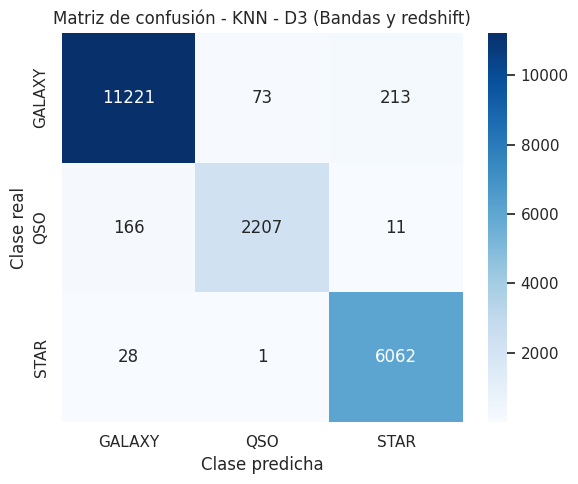

In [ ]:
# ============================================================
# KNN - MATRIZ DE CONFUSIÓN D3
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

labels = ["GALAXY", "QSO", "STAR"]

cm_d3 = confusion_matrix(
    y_test_model,
    y_pred_knn_d3,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_d3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - KNN - D3 (Bandas y redshift)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

#### Comparación D1/D2 vs. D3: incorporación del `redshift`

La incorporación del `redshift` produce una mejora muy marcada en el desempeño de KNN.

El F1 ponderado pasa de 0.8972 en D1 y 0.9079 en D2 a 0.9753 en D3. La mejora también se observa en el F1 macro, que pasa de 0.8502 en D1 y 0.8629 en D2 a 0.9683 en D3.

El efecto es especialmente notable para la clase `QSO`. Su F1-score pasa de 0.7389 en D1 y 0.7542 en D2 a 0.9462 en D3. El recall de `QSO` aumenta de 0.6883 a 0.9258.

La matriz de confusión muestra este cambio con claridad: en D3 se clasifican correctamente 2207 de los 2384 QSO del conjunto de test, mientras que solamente 11 QSO son confundidos con `STAR`.

También se observa un cambio en los hiperparámetros seleccionados por la búsqueda. Mientras que en D1 y D2 se seleccionó `K = 9`, distancia Euclídea (`p = 2`) y ponderación por distancia, en D3 la combinación seleccionada fue `K = 5`, distancia Manhattan (`p = 1`) y ponderación por distancia.

El F1 ponderado promedio obtenido durante la validación cruzada para esta configuración fue 0.9725, mientras que el F1 ponderado obtenido posteriormente sobre el conjunto de test fue 0.9753.

Este cambio muestra que la incorporación del `redshift` no solamente modifica el desempeño obtenido, sino también la configuración de KNN que resulta más adecuada para esta representación de los datos.

Estos resultados muestran que, para KNN y sobre este conjunto de datos, el `redshift` aporta una cantidad importante de información discriminante entre las tres clases.

La comparación D1 vs. D3 permite estudiar el efecto del `redshift` sobre las bandas originales. La comparación D2 vs. D4 permitirá analizar si los colores aportan información adicional cuando ya se dispone del `redshift`.

### D4

In [ ]:
# ============================================================
# KNN - ENTRENAMIENTO D4: Bandas, colores y redshift
# ============================================================

knn_grid_d4 = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

knn_grid_d4.fit(
    X_all_train,
    y_train_model
)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'model__n_neighbors': array([ 3,  5,  7,  9, 11, 13, 15, 17, 19, 21]),
                         'model__p': [1, 2],
                         'model__weights': ['uniform', 'distance']},
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D4
# ============================================================

print("Mejores hiperparámetros para D4 - Bandas, colores y redshift:")
print(knn_grid_d4.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(knn_grid_d4.best_score_, 4))

Mejores hiperparámetros para D4 - Bandas, colores y redshift:
{'model__n_neighbors': np.int64(3), 'model__p': 2, 'model__weights': 'uniform'}

Mejor F1 ponderado promedio en validación cruzada:
0.9659


In [ ]:
# ============================================================
# KNN - EVALUACIÓN D4 SOBRE TEST
# ============================================================

y_pred_knn_d4 = knn_grid_d4.best_estimator_.predict(
    X_all_test
)

In [ ]:
# ============================================================
# KNN - MÉTRICAS D4 SOBRE TEST
# ============================================================

accuracy_d4 = accuracy_score(
    y_test_model,
    y_pred_knn_d4
)

precision_d4 = precision_score(
    y_test_model,
    y_pred_knn_d4,
    average="weighted",
    zero_division=0
)

recall_d4 = recall_score(
    y_test_model,
    y_pred_knn_d4,
    average="weighted",
    zero_division=0
)

f1_weighted_d4 = f1_score(
    y_test_model,
    y_pred_knn_d4,
    average="weighted",
    zero_division=0
)

f1_macro_d4 = f1_score(
    y_test_model,
    y_pred_knn_d4,
    average="macro",
    zero_division=0
)

print("KNN - D4: Bandas, colores y redshift")
print("-" * 35)
print(f"Accuracy:          {accuracy_d4:.4f}")
print(f"Precision weighted: {precision_d4:.4f}")
print(f"Recall weighted:    {recall_d4:.4f}")
print(f"F1 weighted:        {f1_weighted_d4:.4f}")
print(f"F1 macro:           {f1_macro_d4:.4f}")

KNN - D4: Bandas, colores y redshift
-----------------------------------
Accuracy:          0.9685
Precision weighted: 0.9685
Recall weighted:    0.9685
F1 weighted:        0.9684
F1 macro:           0.9621


In [ ]:
# ============================================================
# KNN - CLASSIFICATION REPORT D4
# ============================================================

print("KNN - D4: Bandas, colores y redshift")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_knn_d4,
        digits=4,
        zero_division=0
    )
)

KNN - D4: Bandas, colores y redshift
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9742    0.9726    0.9734     11507
         QSO     0.9638    0.9266    0.9448      2384
        STAR     0.9595    0.9770    0.9682      6091

    accuracy                         0.9685     19982
   macro avg     0.9659    0.9587    0.9621     19982
weighted avg     0.9685    0.9685    0.9684     19982



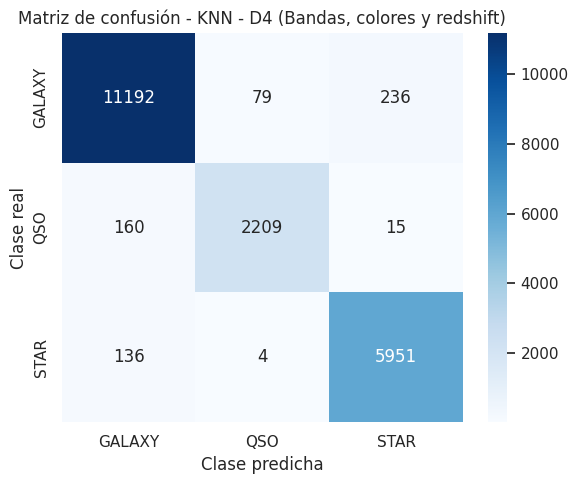

In [ ]:
# ============================================================
# KNN - MATRIZ DE CONFUSIÓN D4
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

labels = ["GALAXY", "QSO", "STAR"]

cm_d4 = confusion_matrix(
    y_test_model,
    y_pred_knn_d4,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_d4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - KNN - D4 (Bandas, colores y redshift)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

#### Comparación D3 vs. D4: incorporación de colores junto con `redshift`

Al comparar D3 (bandas + `redshift`) con D4 (bandas + colores + `redshift`), se observa que la incorporación de los colores no produce una mejora adicional en el desempeño de KNN.

El F1 ponderado pasa de **0.9753** en D3 a **0.9684** en D4. El mismo comportamiento se observa en el F1 macro, que pasa de **0.9683** a **0.9621**, y en la accuracy, que pasa de **0.9754** a **0.9685**.

El comportamiento por clase es el siguiente:

| Clase | F1 D3 | F1 D4 |
|---|---:|---:|
| GALAXY | 0.9791 | 0.9734 |
| QSO | 0.9462 | 0.9448 |
| STAR | 0.9796 | 0.9682 |

La clase `QSO` presenta un desempeño muy similar en ambos casos, mientras que la disminución es más marcada para `GALAXY` y `STAR`.

También cambia la configuración de KNN seleccionada mediante validación cruzada. Para D3 se seleccionó `K = 5`, distancia Manhattan (`p = 1`) y ponderación por distancia, mientras que para D4 se seleccionó `K = 3`, distancia Euclídea (`p = 2`) y ponderación uniforme.

El F1 ponderado promedio durante la validación cruzada fue **0.9725** para D3 y **0.9659** para D4, consistente con la diferencia observada posteriormente sobre el conjunto de test.

Este resultado muestra que incorporar más variables no necesariamente mejora el desempeño de KNN. En este caso, los colores son variables derivadas de las mismas bandas fotométricas, por lo que agregarlos al conjunto que ya contiene las bandas y el `redshift` no aporta una mejora adicional para este algoritmo y esta configuración experimental.

Por lo tanto, para KNN, la comparación D3 vs. D4 indica que el `redshift` aporta información discriminante importante, mientras que la incorporación adicional de los colores no mejora el desempeño obtenido utilizando bandas + `redshift`.

### Comparación de KNN para D1 a D4 y conclusiones

Una vez ajustado KNN para los cuatro conjuntos de variables, comparamos su desempeño para analizar cómo influye la representación de los datos en la clasificación.

En todos los casos se utilizó el mismo conjunto de entrenamiento y prueba, y los hiperparámetros fueron seleccionados mediante `GridSearchCV` utilizando validación cruzada de 5 particiones.

Para esta comparación utilizaremos como métrica principal el **F1 weighted**, ya que combina precision y recall y tiene en cuenta la distribución desigual de las tres clases.

La comparación busca responder las siguientes preguntas:

- ¿Qué ocurre al utilizar únicamente las bandas fotométricas?
- ¿La incorporación de colores mejora el desempeño respecto de las bandas?
- ¿Cuánto aporta `redshift` cuando se agrega a las bandas?
- ¿Los colores aportan información adicional cuando ya disponemos de `redshift`?

In [ ]:
# ============================================================
# KNN - COMPARACIÓN FINAL DE LOS CUATRO DATASETS
# ============================================================

resultados_knn = pd.DataFrame({
    "D1 - Bandas": {
        "F1 CV": knn_grid_d1.best_score_,
        "Accuracy": accuracy_d1,
        "Precision weighted": precision_d1,
        "Recall weighted": recall_d1,
        "F1 weighted": f1_weighted_d1,
        "F1 macro": f1_macro_d1
    },

    "D2 - Bandas + colores": {
        "F1 CV": knn_grid_d2.best_score_,
        "Accuracy": accuracy_d2,
        "Precision weighted": precision_d2,
        "Recall weighted": recall_d2,
        "F1 weighted": f1_weighted_d2,
        "F1 macro": f1_macro_d2
    },

    "D3 - Bandas + redshift": {
        "F1 CV": knn_grid_d3.best_score_,
        "Accuracy": accuracy_d3,
        "Precision weighted": precision_d3,
        "Recall weighted": recall_d3,
        "F1 weighted": f1_weighted_d3,
        "F1 macro": f1_macro_d3
    },

    "D4 - Bandas + colores + redshift": {
        "F1 CV": knn_grid_d4.best_score_,
        "Accuracy": accuracy_d4,
        "Precision weighted": precision_d4,
        "Recall weighted": recall_d4,
        "F1 weighted": f1_weighted_d4,
        "F1 macro": f1_macro_d4
    }
}).T

resultados_knn.round(4)

,F1 CV,Accuracy,Precision weighted,Recall weighted,F1 weighted,F1 macro
D1 - Bandas,0.8919,0.8985,0.8970,0.8985,0.8972,0.8502
D2 - Bandas + colores,0.9058,0.9091,0.9075,0.9091,0.9079,0.8629
D3 - Bandas + redshift,0.9725,0.9754,0.9755,0.9754,0.9753,0.9683
D4 - Bandas + colores + redshift,0.9659,0.9685,0.9685,0.9685,0.9684,0.9621


In [ ]:
# ============================================================
# KNN - HIPERPARÁMETROS SELECCIONADOS
# ============================================================

hiperparametros_knn = pd.DataFrame({
    "D1 - Bandas": knn_grid_d1.best_params_,
    "D2 - Bandas + colores": knn_grid_d2.best_params_,
    "D3 - Bandas + redshift": knn_grid_d3.best_params_,
    "D4 - Bandas + colores + redshift": knn_grid_d4.best_params_
}).T

hiperparametros_knn

,model__n_neighbors,model__p,model__weights
D1 - Bandas,9,2,distance
D2 - Bandas + colores,9,2,distance
D3 - Bandas + redshift,5,1,distance
D4 - Bandas + colores + redshift,3,2,uniform


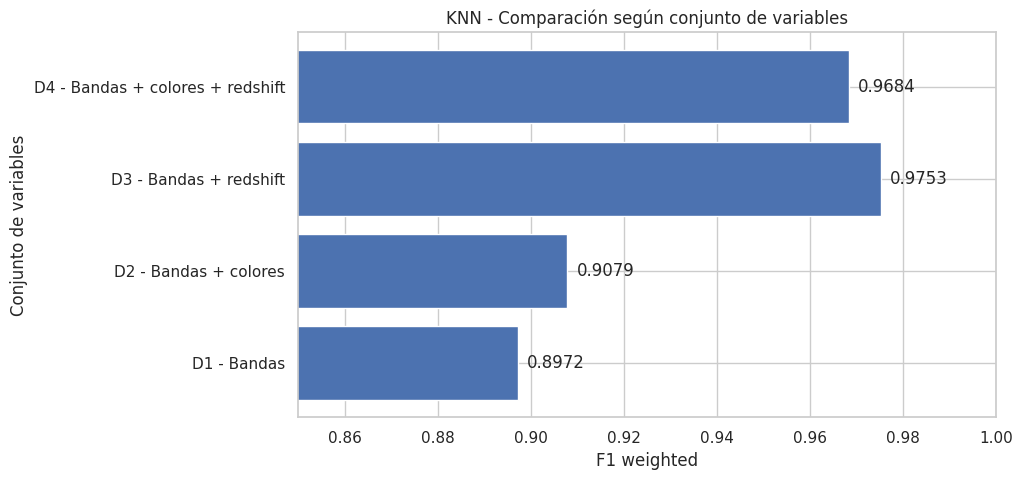

In [ ]:
comparacion_knn = pd.DataFrame({
    "Dataset": [
        "D1 - Bandas",
        "D2 - Bandas + colores",
        "D3 - Bandas + redshift",
        "D4 - Bandas + colores + redshift"
    ],
    "F1 weighted": [
        0.8972,
        0.9079,
        0.9753,
        0.9684
    ]
})

plt.figure(figsize=(9, 5))

bars = plt.barh(
    comparacion_knn["Dataset"],
    comparacion_knn["F1 weighted"]
)

plt.xlabel("F1 weighted")
plt.ylabel("Conjunto de variables")
plt.title("KNN - Comparación según conjunto de variables")
plt.xlim(0.85, 1.00)

for bar, value in zip(bars, comparacion_knn["F1 weighted"]):
    plt.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

plt.show()

#### Análisis de los resultados

La comparación muestra que el conjunto de variables utilizado tiene un efecto importante sobre el desempeño de KNN.

Al pasar de **D1 (bandas)** a **D2 (bandas + colores)**, el F1 weighted aumenta de **0.8972 a 0.9079**. Esto indica que, para KNN, la incorporación de los colores fotométricos mejora la clasificación respecto de utilizar únicamente las bandas originales.

El cambio más importante se observa al pasar de **D1 a D3**, incorporando `redshift`. El F1 weighted aumenta de **0.8972 a 0.9753**. Este incremento muestra que `redshift` aporta información muy relevante para distinguir las clases en este conjunto de datos.

Al comparar **D3 con D4**, el F1 weighted disminuye de **0.9753 a 0.9684** al incorporar los colores junto con las bandas y `redshift`. Por lo tanto, en este experimento, los colores no aportan una mejora adicional cuando `redshift` ya forma parte del conjunto de variables.

Estos resultados muestran que **agregar variables no necesariamente mejora el desempeño de KNN**. La utilidad de una variable depende de la información que aporta y de cómo interactúa con el resto de las variables dentro del algoritmo.

También se observa que los hiperparámetros seleccionados cambian entre los distintos conjuntos de variables. Mientras que D1 y D2 utilizan `n_neighbors = 9`, `p = 2` y `weights = distance`, D3 utiliza `n_neighbors = 5`, `p = 1` y `weights = distance`, y D4 utiliza `n_neighbors = 3`, `p = 2` y `weights = uniform`.

Esto muestra que la representación de los datos no solo modifica el desempeño del modelo, sino también la configuración de KNN que resulta seleccionada mediante la validación cruzada.

En síntesis, para el experimento realizado con KNN, las diferencias entre D1, D2, D3 y D4 muestran que `redshift` tiene un impacto importante en el desempeño, mientras que la incorporación de colores presenta un efecto menor y depende de si `redshift` ya está disponible.

## Comparación de KNN con el baseline



Para comparar el baseline con los distintos experimentos realizados con KNN necesitamos seleccionar una métrica principal.

En este problema tenemos tres clases (`GALAXY`, `QSO` y `STAR`) con una distribución desigual de observaciones. Por este motivo, la **accuracy** por sí sola no resulta suficiente para caracterizar el desempeño del clasificador, ya que puede estar fuertemente influenciada por la clase mayoritaria.

Elegimos como métrica principal el **F1 weighted**, que combina precision y recall y calcula el promedio ponderando cada clase según la cantidad de observaciones que contiene.

Esta elección también mantiene la coherencia con el procedimiento utilizado para seleccionar los hiperparámetros de KNN, ya que `GridSearchCV` utilizó `f1_weighted` como función de evaluación durante la validación cruzada.

Utilizaremos entonces el **F1 weighted como métrica principal de comparación**, mientras que el resto de las métricas calculadas anteriormente —accuracy, precision, recall y F1 macro— se utilizarán para complementar el análisis cuando sea necesario.

La comparación se realizará entre:

- el **baseline**, que utiliza únicamente `redshift` mediante una regla basada en dos umbrales;
- KNN utilizando **D1: bandas**;
- KNN utilizando **D2: bandas + colores**;
- KNN utilizando **D3: bandas + redshift**;
- KNN utilizando **D4: bandas + colores + redshift**.

De esta manera podemos analizar no solo la diferencia entre el baseline y KNN, sino también cómo cambia el desempeño de KNN al incorporar progresivamente distintos tipos de variables.

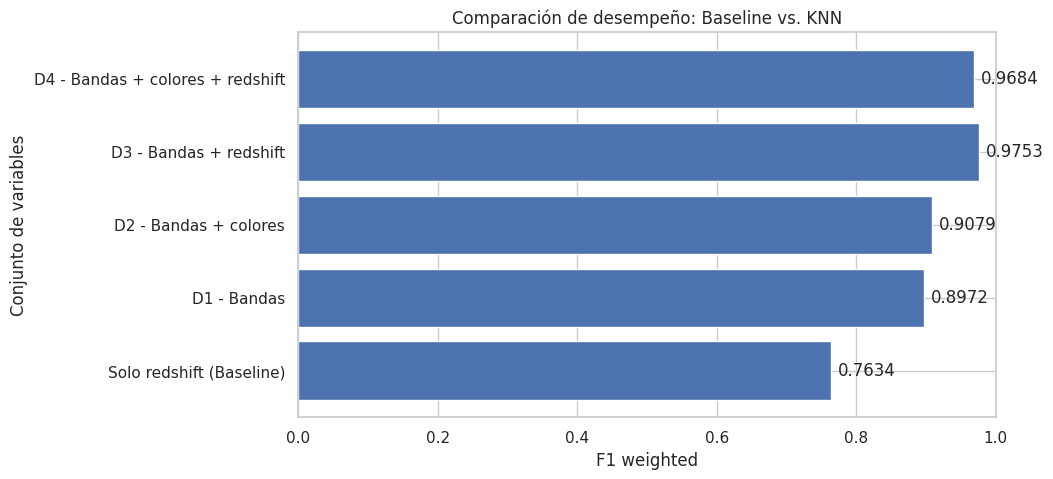

In [ ]:
# Agregamos el baseline a la comparación con KNN

f1_baseline = f1_score(
    y_test_model,
    y_pred_baseline,
    average="weighted"
)

comparacion = pd.concat([
    pd.DataFrame({
        "Dataset": ["Solo redshift (Baseline)"],
        "F1 weighted": [f1_baseline]
    }),
    comparacion_knn
], ignore_index=True)


# Gráfico de comparación

plt.figure(figsize=(9, 5))

bars = plt.barh(
    comparacion["Dataset"],
    comparacion["F1 weighted"]
)

plt.xlabel("F1 weighted")
plt.ylabel("Conjunto de variables")
plt.title("Comparación de desempeño: Baseline vs. KNN")
plt.xlim(0, 1)

for bar, value in zip(bars, comparacion["F1 weighted"]):
    plt.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

plt.show()

### Análisis de la comparación

El gráfico permite observar cómo cambia el desempeño medido mediante **F1 weighted** al modificar las variables utilizadas por el clasificador.

En primer lugar, el **baseline basado únicamente en `redshift`** alcanza un F1 weighted de **0.7634**. Este resultado muestra que `redshift` contiene información relevante para distinguir las clases, incluso utilizando una regla simple basada en dos umbrales.

Al utilizar KNN con **D1 (bandas)**, el F1 weighted aumenta a **0.8972**. Por lo tanto, en este experimento, las variables fotométricas permiten al modelo aprender relaciones entre las observaciones y las clases que no son capturadas por la regla simple utilizada en el baseline.

Al incorporar los **colores fotométricos en D2**, el F1 weighted aumenta de **0.8972 a 0.9079**. Esto representa una mejora respecto de utilizar únicamente las bandas. Los colores son variables derivadas de las bandas originales y, por lo tanto, no incorporan una nueva medición independiente, pero constituyen una representación alternativa de la información fotométrica.

El cambio más importante se observa al incorporar `redshift` en **D3**. El F1 weighted pasa de **0.8972 en D1 a 0.9753 en D3**. En este conjunto de datos y bajo este experimento, esto indica que `redshift` aporta información muy relevante para la clasificación cuando se combina con las bandas fotométricas.

Finalmente, al incorporar también los colores en **D4**, el F1 weighted pasa de **0.9753 a 0.9684**. Por lo tanto, en este experimento, agregar los colores a las bandas y al `redshift` no produjo una mejora adicional del desempeño global de KNN.

Estos resultados muestran que **incorporar una mayor cantidad de variables no garantiza necesariamente una mejora del modelo**. El efecto depende de la información aportada por cada variable y de cómo esta información es utilizada por el algoritmo.

En particular, los resultados obtenidos permiten plantear tres observaciones para continuar el análisis:

1. Las **bandas fotométricas** aportan información importante para la clasificación respecto del baseline basado únicamente en `redshift`.
2. Los **colores fotométricos** producen una mejora cuando se agregan a las bandas, aunque esta mejora es menor que la observada al incorporar `redshift`.
3. El `redshift` produce el cambio más marcado dentro de los conjuntos de variables evaluados, mientras que agregar colores cuando ya se dispone de bandas y `redshift` no mejora el F1 weighted en este experimento.

Estas conclusiones corresponden específicamente al experimento realizado con **KNN**, utilizando el mismo conjunto de entrenamiento y prueba, validación cruzada de 5 particiones y la configuración de hiperparámetros seleccionada mediante `GridSearchCV`.

# 5. Modelado: Support Vector Machines (SVM)

## 5.1. ¿Cómo funciona SVM?

KNN clasifica mirando a los vecinos. SVM, en cambio, **traza una frontera de decisión** entre las clases y elige, entre todas las fronteras posibles, la que deja el **mayor margen** posible respecto de las observaciones más cercanas. Esas observaciones que definen la frontera son los **vectores de soporte**.

Siguiendo la construcción vista en la cursada, el modelo se arma en tres pasos:

1. **Clasificador de máximo margen (*hard-margin*):** busca el hiperplano que separa las clases con el mayor margen. Solo funciona si las clases son perfectamente separables.
2. **Clasificador de vector de soporte (*soft-margin*):** permite que algunas observaciones violen el margen o queden del lado equivocado. El hiperparámetro `C` controla cuánto se penalizan esas violaciones.
3. **SVM con funciones kernel:** permite obtener fronteras **no lineales** sin construir explícitamente nuevas variables.

SVM es un clasificador binario. Para nuestras tres clases, `SVC` de scikit-learn utiliza internamente la estrategia **one-vs-one**: entrena un clasificador por cada par de clases (GALAXY–QSO, GALAXY–STAR, QSO–STAR) y asigna la clase más votada.

## 5.2. ¿Por qué debemos escalar las variables?

SVM depende de distancias y productos internos entre observaciones (en el kernel RBF, directamente de la distancia euclídea). Igual que en KNN, una variable con mayor rango numérico dominaría la frontera. Por eso utilizamos `StandardScaler` dentro de un `Pipeline`, de modo que el escalado se ajuste solo con los datos de entrenamiento de cada fold.

## 5.3. Hiperparámetros de SVM

- `kernel`: forma de la frontera. Evaluamos `linear`, `rbf` (radial) y `poly` (polinómico).
- `C`: penalización de las violaciones del margen. Un `C` chico admite más errores y produce una frontera más suave; un `C` grande intenta clasificar bien cada observación de entrenamiento y puede sobreajustar.
- `gamma` (kernel `rbf`): alcance de la influencia de cada vector de soporte. Un `gamma` grande produce fronteras más irregulares.
- `degree` (kernel `poly`): grado del polinomio.
- `class_weight`: `None` o `"balanced"`. Con `"balanced"` se penalizan más los errores sobre las clases minoritarias (en nuestro caso, `QSO`). Lo incluimos en la grilla, como en el caso práctico de la cátedra, para que la validación cruzada decida si conviene.

## 5.4. Costo computacional y estrategia de búsqueda

A diferencia de KNN, el costo de entrenar un SVM crece de forma más que lineal con la cantidad de observaciones. Medimos que **un solo ajuste** con kernel RBF sobre las 79.927 observaciones de `train` tarda alrededor de **50 segundos**. Una búsqueda en grilla completa con validación cruzada de 5 folds requiere cientos de ajustes, lo que llevaría varias horas por dataset.

Por este motivo, la **búsqueda de hiperparámetros** se realiza sobre una **submuestra estratificada de 10.000 observaciones de `train`**, y luego el modelo con los mejores hiperparámetros se **reentrena sobre el `train` completo** antes de evaluarlo en `test`.

- La submuestra se toma **una sola vez** y se utiliza para los cuatro datasets (D1 a D4), igual que la partición `train/test`.
- La submuestra sale de `train`: el conjunto de `test` sigue sin participar en ninguna decisión.
- La métrica de selección es la misma que en KNN: **F1 ponderado (`f1_weighted`)**.


In [ ]:
# ============================================================
# SVM - IMPORTACIÓN DE LIBRERÍAS
# ============================================================

from sklearn.svm import SVC
from sklearn.base import clone


In [ ]:
# ============================================================
# SVM - SUBMUESTRA ESTRATIFICADA DE TRAIN PARA LA BÚSQUEDA
# ============================================================

# Se toman 10.000 índices de train, conservando la proporción de clases.
# Los mismos índices se usan para D1, D2, D3 y D4.

idx_svm, _ = train_test_split(
    idx_train,
    train_size=10_000,
    random_state=42,
    stratify=y_train_model
)

y_svm = y_train_model.loc[idx_svm]

print("Observaciones en la submuestra:", len(idx_svm))
print("\nProporción de clases en la submuestra:")
print(y_svm.value_counts(normalize=True).round(3))


Observaciones en la submuestra: 10000

Proporción de clases en la submuestra:
class
GALAXY    0.576
STAR      0.305
QSO       0.119
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# SVM - PIPELINE
# ============================================================

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

svm_pipeline


Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC())])

In [ ]:
# ============================================================
# SVM - GRILLA DE HIPERPARÁMETROS
# ============================================================

# Una grilla por kernel, ya que cada kernel tiene sus propios hiperparámetros.

svm_param_grid = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [1, 10, 100],
        "model__gamma": [0.1, 0.5, 1, 2],
        "model__class_weight": [None, "balanced"]
    },
    {
        "model__kernel": ["poly"],
        "model__C": [1, 10],
        "model__degree": [2, 3],
        "model__class_weight": [None, "balanced"]
    }
]

svm_param_grid


[{'model__kernel': ['linear'],
  'model__C': [0.1, 1, 10],
  'model__class_weight': [None, 'balanced']},
 {'model__kernel': ['rbf'],
  'model__C': [1, 10, 100],
  'model__gamma': [0.1, 0.5, 1, 2],
  'model__class_weight': [None, 'balanced']},
 {'model__kernel': ['poly'],
  'model__C': [1, 10],
  'model__degree': [2, 3],
  'model__class_weight': [None, 'balanced']}]

### D1


In [ ]:
# ============================================================
# SVM - BÚSQUEDA DE HIPERPARÁMETROS D1: SOLO BANDAS // Aqui probamos todas las combinaciones de perillas


#/ tres tipos de horno (los kernels: linear, rbf, poly) y cada uno tiene sus perillas (C, gamma, degree, class_weight). La grilla arma todas las combinaciones:

#lineal: 3 valores de C × 2 de class_weight = 6
#rbf: 3 de C × 4 de gamma × 2 de class_weight = 24
#poly: 2 de C × 2 de degree × 2 de class_weight = 8
#En total, 38 recetas.

#¿Cómo decide cuál es mejor? Con validación cruzada (cv=5). Los 10.000 datos se cortan en 5 pedazos de 2.000. Para cada receta:

#entrena con los pedazos 1, 2, 3 y 4, y toma examen con el 5;
#entrena con 1, 2, 3 y 5, y toma examen con el 4;
#… y así hasta que cada pedazo fue examen una vez.
#Cada receta rinde 5 exámenes distintos y su nota final es el promedio. ¿Por qué no un solo examen? Porque una receta podría tener suerte y caer con un examen fácil. Con 5 exámenes, la suerte se compensa.

#38 recetas × 5 exámenes = 190 entrenamientos. Por eso usamos 10.000 datos y no 80.000.

#Las otras opciones de la celda:

#scoring="f1_weighted": la nota de cada examen es el F1 ponderado (lo explico en la celda 10).
#n_jobs=-1: usá todos los núcleos de la compu en paralelo.
#refit=True: cuando termina, entrená la receta ganadora con los 10.000 completos. /#
# ============================================================

svm_grid_d1 = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

svm_grid_d1.fit(
    X_bands_train.loc[idx_svm],
    y_svm
)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', SVC())]),
             n_jobs=-1,
             param_grid=[{'model__C': [0.1, 1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__kernel': ['linear']},
                         {'model__C': [1, 10, 100],
                          'model__class_weight': [None, 'balanced'],
                          'model__gamma': [0.1, 0.5, 1, 2],
                          'model__kernel': ['rbf']},
                         {'model__C': [1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__degree': [2, 3], 'model__kernel': ['poly']}],
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D1 // Quien gano

#C = 100: qué tan exigente es con los errores. Con C bajo el modelo dice "si me equivoco en algunos puntos, no pasa nada, prefiero una frontera tranquila". Con C alto dice "quiero acertar casi todo, aunque la frontera quede retorcida". 100 es bastante exigente.
#gamma = 0.5: qué tan "local" mira cada punto. Con gamma alto, cada punto solo influye en su entorno inmediato y la frontera se arruga alrededor de cada uno. Con gamma bajo, cada punto influye lejos y la frontera queda más lisa. 0,5 es un punto medio.
#class_weight = None: los quásares no reciben trato especial.


# ============================================================

print("Mejores hiperparámetros para D1 - Solo bandas:")
print(svm_grid_d1.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(svm_grid_d1.best_score_, 4))

# Mejor resultado obtenido por cada kernel
resultados_cv_svm_d1 = pd.DataFrame(svm_grid_d1.cv_results_)

print("\nMejor F1 ponderado en validación cruzada por kernel:")
print(
    resultados_cv_svm_d1
    .groupby("param_model__kernel")["mean_test_score"]
    .max()
    .round(4)
)


Mejores hiperparámetros para D1 - Solo bandas:
{'model__C': 100, 'model__class_weight': None, 'model__gamma': 0.5, 'model__kernel': 'rbf'}

Mejor F1 ponderado promedio en validación cruzada:
0.897

Mejor F1 ponderado en validación cruzada por kernel:
param_model__kernel
linear    0.7928
poly      0.7885
rbf       0.8970
Name: mean_test_score, dtype: float64


In [ ]:
# ============================================================
# SVM - REENTRENAMIENTO D1 SOBRE TRAIN COMPLETO Tomamos la configuracion ganadora (la receta y lo hacemos con el conjunto train completo)
# ============================================================

# clone() copia la configuración del mejor modelo (con sus hiperparámetros)
# pero sin entrenar. Luego se ajusta sobre las 79.927 observaciones de train.

svm_d1 = clone(svm_grid_d1.best_estimator_)

svm_d1.fit(
    X_bands_train,
    y_train_model
)


Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC(C=100, gamma=0.5))])

In [ ]:
# ============================================================
# SVM - EVALUACIÓN D1 SOBRE TEST
# ============================================================

y_pred_svm_d1 = svm_d1.predict(
    X_bands_test
)

accuracy_svm_d1 = accuracy_score(y_test_model, y_pred_svm_d1)
precision_svm_d1 = precision_score(y_test_model, y_pred_svm_d1, average="weighted", zero_division=0)
recall_svm_d1 = recall_score(y_test_model, y_pred_svm_d1, average="weighted", zero_division=0)
f1_weighted_svm_d1 = f1_score(y_test_model, y_pred_svm_d1, average="weighted", zero_division=0)
f1_macro_svm_d1 = f1_score(y_test_model, y_pred_svm_d1, average="macro", zero_division=0)

print("SVM - D1: Solo bandas")
print("-" * 35)
print(f"Accuracy:           {accuracy_svm_d1:.4f}")
print(f"Precision weighted: {precision_svm_d1:.4f}")
print(f"Recall weighted:    {recall_svm_d1:.4f}")
print(f"F1 weighted:        {f1_weighted_svm_d1:.4f}")
print(f"F1 macro:           {f1_macro_svm_d1:.4f}")


SVM - D1: Solo bandas
-----------------------------------
Accuracy:           0.9080
Precision weighted: 0.9060
Recall weighted:    0.9080
F1 weighted:        0.9064
F1 macro:           0.8606


el modelo clasifica los 19.982 objetos de test, que nunca vio. Es la nota que se reporta.

Las métricas, con el ejemplo de los quásares:

Precision (QSO = 0,81): de todos los objetos que el modelo dijo que eran quásares, el 81 % realmente lo eran. Responde "cuando dice quásar, ¿le puedo creer?".
Recall (QSO = 0,70): de todos los quásares que realmente había, encontró el 70 %. Responde "¿cuántos se le escapan?". Acá se le escapan 3 de cada 10.
F1: combina las dos en un solo número, pero castiga si una es mala. Si tenés precision 1,0 y recall 0,1, el promedio común da 0,55, que parece aceptable; el F1 da 0,18. No te deja esconder una pata floja.
Accuracy (0,908): porcentaje de aciertos sobre el total. Es simple, pero engaña con clases desbalanceadas: como el 58 % son galaxias, un modelo bobo que diga "galaxia" siempre ya saca 0,58.
Weighted contra macro: son dos formas de promediar el F1 de las tres clases.

Weighted (0,906): cada clase pesa según cuántos objetos tiene. Las galaxias, que son muchas y se clasifican bien, tiran para arriba.
Macro (0,861): las tres clases pesan lo mismo. El quásar, que es la clase floja, pesa tanto como la galaxia.
Que macro dé más bajo que weighted te está avisando: hay una clase minoritaria a la que le va peor. Ese es el quásar.

In [ ]:
# ============================================================
# SVM - CLASSIFICATION REPORT D1
# ============================================================

print("SVM - D1: Solo bandas")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_svm_d1,
        digits=4,
        zero_division=0
    )
)


SVM - D1: Solo bandas
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9433    0.9644    0.9537     11507
         QSO     0.8124    0.6959    0.7497      2384
        STAR     0.8722    0.8844    0.8783      6091

    accuracy                         0.9080     19982
   macro avg     0.8760    0.8482    0.8606     19982
weighted avg     0.9060    0.9080    0.9064     19982



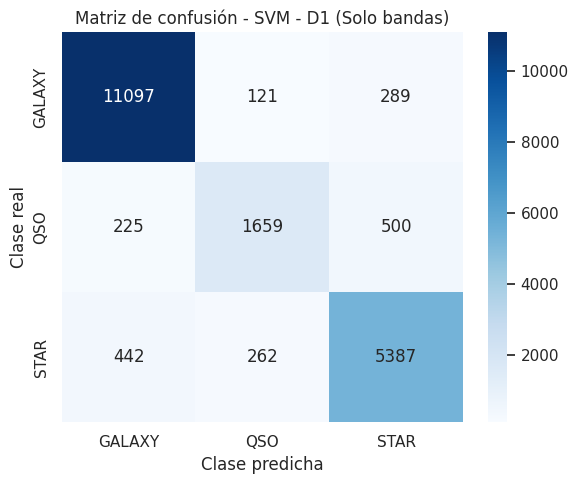

In [ ]:

# ============================================================
# SVM - MATRIZ DE CONFUSIÓN D1
# ============================================================

labels = ["GALAXY", "QSO", "STAR"]

cm_svm_d1 = confusion_matrix(
    y_test_model,
    y_pred_svm_d1,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm_d1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - SVM - D1 (Solo bandas)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


#### Interpretación de SVM - D1

La búsqueda en grilla seleccionó el kernel **RBF** con `C = 100`, `gamma = 0.5` y sin reponderación de clases (`class_weight = None`), con un F1 ponderado promedio de **0.8970** en validación cruzada.

La comparación entre kernels muestra que la frontera no lineal es necesaria: el mejor kernel lineal alcanzó **0.7928** y el mejor polinómico **0.7885**, frente a **0.8970** del RBF. Las bandas fotométricas no permiten separar las tres clases con un hiperplano.

`class_weight = "balanced"` no fue seleccionado: reponderar `QSO` mejora su recall a costa de más errores en las otras clases, y el F1 ponderado global resulta menor.

Sobre `test`, el modelo reentrenado con el `train` completo obtiene un F1 ponderado de **0.9064** y un F1 macro de **0.8607**, frente a 0.8972 y 0.8502 de KNN con el mismo dataset. Por clase:

| Clase | F1 KNN D1 | F1 SVM D1 |
|---|---:|---:|
| GALAXY | 0.9473 | 0.9537 |
| QSO | 0.7389 | 0.7499 |
| STAR | 0.8645 | 0.8784 |

SVM mejora levemente en las tres clases, pero `QSO` sigue siendo la clase más difícil: su recall es **0.6963**, por lo que cerca de 3 de cada 10 quásares no son identificados únicamente a partir de las bandas. La matriz de confusión muestra que el error principal es confundir quásares con estrellas (**499 casos**): en la imagen, ambos se ven como un punto.


### D2


In [ ]:
# ============================================================
# SVM - BÚSQUEDA DE HIPERPARÁMETROS D2: BANDAS + COLORES
# ============================================================

svm_grid_d2 = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

svm_grid_d2.fit(
    X_bands_colors_train.loc[idx_svm],
    y_svm
)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', SVC())]),
             n_jobs=-1,
             param_grid=[{'model__C': [0.1, 1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__kernel': ['linear']},
                         {'model__C': [1, 10, 100],
                          'model__class_weight': [None, 'balanced'],
                          'model__gamma': [0.1, 0.5, 1, 2],
                          'model__kernel': ['rbf']},
                         {'model__C': [1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__degree': [2, 3], 'model__kernel': ['poly']}],
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D2
# ============================================================

print("Mejores hiperparámetros para D2 - Bandas + colores:")
print(svm_grid_d2.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(svm_grid_d2.best_score_, 4))

resultados_cv_svm_d2 = pd.DataFrame(svm_grid_d2.cv_results_)

print("\nMejor F1 ponderado en validación cruzada por kernel:")
print(
    resultados_cv_svm_d2
    .groupby("param_model__kernel")["mean_test_score"]
    .max()
    .round(4)
)


Mejores hiperparámetros para D2 - Bandas + colores:
{'model__C': 1, 'model__class_weight': None, 'model__gamma': 1, 'model__kernel': 'rbf'}

Mejor F1 ponderado promedio en validación cruzada:
0.9013

Mejor F1 ponderado en validación cruzada por kernel:
param_model__kernel
linear    0.7927
poly      0.8280
rbf       0.9013
Name: mean_test_score, dtype: float64


In [ ]:
# ============================================================
# SVM - REENTRENAMIENTO D2 SOBRE TRAIN COMPLETO
# ============================================================

svm_d2 = clone(svm_grid_d2.best_estimator_)

svm_d2.fit(
    X_bands_colors_train,
    y_train_model
)


Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC(C=1, gamma=1))])

In [ ]:
# ============================================================
# SVM - EVALUACIÓN D2 SOBRE TEST
# ============================================================

y_pred_svm_d2 = svm_d2.predict(
    X_bands_colors_test
)

accuracy_svm_d2 = accuracy_score(y_test_model, y_pred_svm_d2)
precision_svm_d2 = precision_score(y_test_model, y_pred_svm_d2, average="weighted", zero_division=0)
recall_svm_d2 = recall_score(y_test_model, y_pred_svm_d2, average="weighted", zero_division=0)
f1_weighted_svm_d2 = f1_score(y_test_model, y_pred_svm_d2, average="weighted", zero_division=0)
f1_macro_svm_d2 = f1_score(y_test_model, y_pred_svm_d2, average="macro", zero_division=0)

print("SVM - D2: Bandas + colores")
print("-" * 35)
print(f"Accuracy:           {accuracy_svm_d2:.4f}")
print(f"Precision weighted: {precision_svm_d2:.4f}")
print(f"Recall weighted:    {recall_svm_d2:.4f}")
print(f"F1 weighted:        {f1_weighted_svm_d2:.4f}")
print(f"F1 macro:           {f1_macro_svm_d2:.4f}")


SVM - D2: Bandas + colores
-----------------------------------
Accuracy:           0.9158
Precision weighted: 0.9143
Recall weighted:    0.9158
F1 weighted:        0.9145
F1 macro:           0.8731


In [ ]:
# ============================================================
# SVM - CLASSIFICATION REPORT D2
# ============================================================

print("SVM - D2: Bandas + colores")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_svm_d2,
        digits=4,
        zero_division=0
    )
)


SVM - D2: Bandas + colores
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9494    0.9654    0.9573     11507
         QSO     0.8321    0.7215    0.7729      2384
        STAR     0.8803    0.8980    0.8891      6091

    accuracy                         0.9158     19982
   macro avg     0.8873    0.8616    0.8731     19982
weighted avg     0.9143    0.9158    0.9145     19982



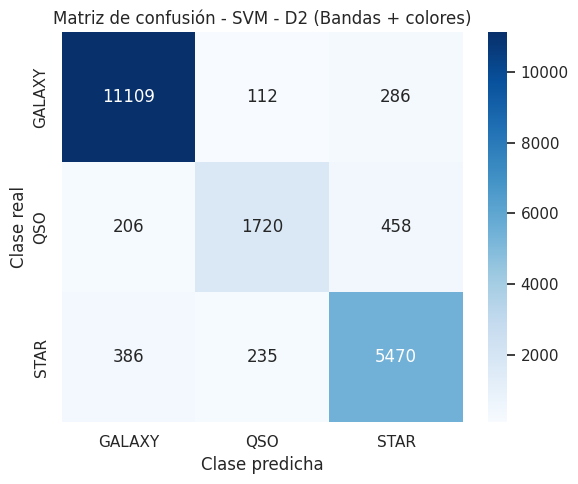

In [ ]:
# ============================================================
# SVM - MATRIZ DE CONFUSIÓN D2
# ============================================================

cm_svm_d2 = confusion_matrix(
    y_test_model,
    y_pred_svm_d2,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm_d2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - SVM - D2 (Bandas + colores)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


#### Interpretación de SVM - D2

La búsqueda seleccionó nuevamente el kernel **RBF**, pero con `C = 1` y `gamma = 1` (en D1 había sido `C = 100`). El F1 ponderado promedio en validación cruzada fue **0.9013**. Por kernel: lineal **0.7927**, polinómico **0.8280** y RBF **0.9013**.

El cambio de `C` es interesante: con las bandas solas, el modelo necesitaba ser muy exigente con los errores (`C = 100`) para separar las clases; con los colores, una frontera más suave (`C = 1`) alcanza para obtener un resultado mejor. Esto sugiere que los colores ordenan los datos de una forma en la que las clases quedan más fáciles de separar.

Sobre `test`, el F1 ponderado pasa de **0.9064** (D1) a **0.9145** (D2), y el F1 macro de **0.8607** a **0.8731**. `QSO` sigue siendo la clase más difícil, aunque mejora: su F1 pasa de 0.7499 a **0.7729** y su recall de 0.6963 a **0.7215**. La confusión de quásares con estrellas baja de 499 a **458**.

Igual que en KNN, incorporar los colores mejora el desempeño respecto de usar solo las bandas, aunque la mejora es moderada: los colores son una reescritura de la misma información fotométrica, no una medición nueva.


### D3


In [ ]:
# ============================================================
# SVM - BÚSQUEDA DE HIPERPARÁMETROS D3: BANDAS + REDSHIFT
# ============================================================

svm_grid_d3 = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

svm_grid_d3.fit(
    X_bands_redshift_train.loc[idx_svm],
    y_svm
)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', SVC())]),
             n_jobs=-1,
             param_grid=[{'model__C': [0.1, 1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__kernel': ['linear']},
                         {'model__C': [1, 10, 100],
                          'model__class_weight': [None, 'balanced'],
                          'model__gamma': [0.1, 0.5, 1, 2],
                          'model__kernel': ['rbf']},
                         {'model__C': [1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__degree': [2, 3], 'model__kernel': ['poly']}],
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D3
# ============================================================

print("Mejores hiperparámetros para D3 - Bandas + redshift:")
print(svm_grid_d3.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(svm_grid_d3.best_score_, 4))

resultados_cv_svm_d3 = pd.DataFrame(svm_grid_d3.cv_results_)

print("\nMejor F1 ponderado en validación cruzada por kernel:")
print(
    resultados_cv_svm_d3
    .groupby("param_model__kernel")["mean_test_score"]
    .max()
    .round(4)
)


Mejores hiperparámetros para D3 - Bandas + redshift:
{'model__C': 100, 'model__class_weight': None, 'model__gamma': 0.1, 'model__kernel': 'rbf'}

Mejor F1 ponderado promedio en validación cruzada:
0.9805

Mejor F1 ponderado en validación cruzada por kernel:
param_model__kernel
linear    0.9798
poly      0.9559
rbf       0.9805
Name: mean_test_score, dtype: float64


In [ ]:
# ============================================================
# SVM - REENTRENAMIENTO D3 SOBRE TRAIN COMPLETO
# ============================================================

svm_d3 = clone(svm_grid_d3.best_estimator_)

svm_d3.fit(
    X_bands_redshift_train,
    y_train_model
)


Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC(C=100, gamma=0.1))])

In [ ]:
# ============================================================
# SVM - EVALUACIÓN D3 SOBRE TEST
# ============================================================

y_pred_svm_d3 = svm_d3.predict(
    X_bands_redshift_test
)

accuracy_svm_d3 = accuracy_score(y_test_model, y_pred_svm_d3)
precision_svm_d3 = precision_score(y_test_model, y_pred_svm_d3, average="weighted", zero_division=0)
recall_svm_d3 = recall_score(y_test_model, y_pred_svm_d3, average="weighted", zero_division=0)
f1_weighted_svm_d3 = f1_score(y_test_model, y_pred_svm_d3, average="weighted", zero_division=0)
f1_macro_svm_d3 = f1_score(y_test_model, y_pred_svm_d3, average="macro", zero_division=0)

print("SVM - D3: Bandas + redshift")
print("-" * 35)
print(f"Accuracy:           {accuracy_svm_d3:.4f}")
print(f"Precision weighted: {precision_svm_d3:.4f}")
print(f"Recall weighted:    {recall_svm_d3:.4f}")
print(f"F1 weighted:        {f1_weighted_svm_d3:.4f}")
print(f"F1 macro:           {f1_macro_svm_d3:.4f}")


SVM - D3: Bandas + redshift
-----------------------------------
Accuracy:           0.9826
Precision weighted: 0.9826
Recall weighted:    0.9826
F1 weighted:        0.9825
F1 macro:           0.9745


In [ ]:
# ============================================================
# SVM - CLASSIFICATION REPORT D3
# ============================================================

print("SVM - D3: Bandas + redshift")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_svm_d3,
        digits=4,
        zero_division=0
    )
)


SVM - D3: Bandas + redshift
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9834    0.9866    0.9850     11507
         QSO     0.9738    0.9207    0.9465      2384
        STAR     0.9845    0.9993    0.9919      6091

    accuracy                         0.9826     19982
   macro avg     0.9806    0.9689    0.9745     19982
weighted avg     0.9826    0.9826    0.9825     19982



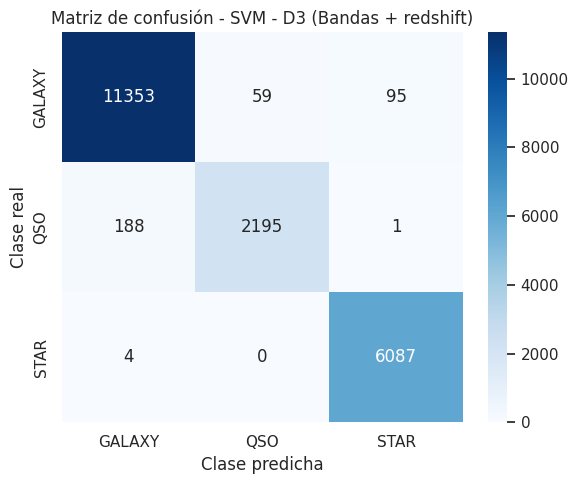

In [ ]:
# ============================================================
# SVM - MATRIZ DE CONFUSIÓN D3
# ============================================================

cm_svm_d3 = confusion_matrix(
    y_test_model,
    y_pred_svm_d3,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm_d3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - SVM - D3 (Bandas + redshift)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


#### Interpretación de SVM - D3

La búsqueda seleccionó el kernel **RBF** con `C = 100` y `gamma = 0.1`, con un F1 ponderado promedio de **0.9805** en validación cruzada.

Lo más llamativo es la comparación entre kernels: el lineal alcanzó **0.9798**, prácticamente lo mismo que el RBF. Sin el `redshift`, la frontera recta quedaba muy por debajo de la curva (0.79 contra 0.90); con el `redshift`, **una frontera recta ya alcanza**. La distancia ordena los datos de tal forma que las tres clases quedan separadas casi con cortes derechos.

Esto también se ve en la cantidad de vectores de soporte, es decir, de puntos que quedan pegados a la frontera: en D1 eran 18.915; en D3 son 3.909. Hay muchos menos objetos en zona dudosa.

Sobre `test`, el F1 ponderado salta de **0.9064** (D1) a **0.9825**, y el F1 macro de **0.8607** a **0.9745**. El F1 de `QSO` pasa de 0.7499 a **0.9465**.

La matriz de confusión muestra el cambio más importante: los quásares confundidos con estrellas pasan de **499 en D1 a 1 en D3**. Un quásar y una estrella se ven iguales en la foto, pero el `redshift` los distingue sin ambigüedad: la estrella está en nuestra galaxia (redshift ≈ 0) y el quásar, muy lejos.

El error que queda es otro: **188 quásares clasificados como galaxias**. Probablemente sean quásares relativamente cercanos, cuyo `redshift` cae en el rango de las galaxias.


### D4


In [ ]:
# ============================================================
# SVM - BÚSQUEDA DE HIPERPARÁMETROS D4: BANDAS + COLORES + REDSHIFT
# ============================================================

svm_grid_d4 = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    refit=True
)

svm_grid_d4.fit(
    X_all_train.loc[idx_svm],
    y_svm
)



GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', SVC())]),
             n_jobs=-1,
             param_grid=[{'model__C': [0.1, 1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__kernel': ['linear']},
                         {'model__C': [1, 10, 100],
                          'model__class_weight': [None, 'balanced'],
                          'model__gamma': [0.1, 0.5, 1, 2],
                          'model__kernel': ['rbf']},
                         {'model__C': [1, 10],
                          'model__class_weight': [None, 'balanced'],
                          'model__degree': [2, 3], 'model__kernel': ['poly']}],
             scoring='f1_weighted')

In [ ]:
# ============================================================
# MEJORES HIPERPARÁMETROS - D4
# ============================================================

print("Mejores hiperparámetros para D4 - Bandas + colores + redshift:")
print(svm_grid_d4.best_params_)

print("\nMejor F1 ponderado promedio en validación cruzada:")
print(round(svm_grid_d4.best_score_, 4))

resultados_cv_svm_d4 = pd.DataFrame(svm_grid_d4.cv_results_)

print("\nMejor F1 ponderado en validación cruzada por kernel:")
print(
    resultados_cv_svm_d4
    .groupby("param_model__kernel")["mean_test_score"]
    .max()
    .round(4)
)


Mejores hiperparámetros para D4 - Bandas + colores + redshift:
{'model__C': 10, 'model__class_weight': None, 'model__kernel': 'linear'}

Mejor F1 ponderado promedio en validación cruzada:
0.98

Mejor F1 ponderado en validación cruzada por kernel:
param_model__kernel
linear    0.9800
poly      0.9518
rbf       0.9769
Name: mean_test_score, dtype: float64


In [ ]:
# ============================================================
# SVM - REENTRENAMIENTO D4 SOBRE TRAIN COMPLETO
# ============================================================

svm_d4 = clone(svm_grid_d4.best_estimator_)

svm_d4.fit(
    X_all_train,
    y_train_model
)


Pipeline(steps=[('scaler', StandardScaler()),
                ('model', SVC(C=10, kernel='linear'))])

In [ ]:
# ============================================================
# SVM - EVALUACIÓN D4 SOBRE TEST
# ============================================================

y_pred_svm_d4 = svm_d4.predict(
    X_all_test
)

accuracy_svm_d4 = accuracy_score(y_test_model, y_pred_svm_d4)
precision_svm_d4 = precision_score(y_test_model, y_pred_svm_d4, average="weighted", zero_division=0)
recall_svm_d4 = recall_score(y_test_model, y_pred_svm_d4, average="weighted", zero_division=0)
f1_weighted_svm_d4 = f1_score(y_test_model, y_pred_svm_d4, average="weighted", zero_division=0)
f1_macro_svm_d4 = f1_score(y_test_model, y_pred_svm_d4, average="macro", zero_division=0)

print("SVM - D4: Bandas + colores + redshift")
print("-" * 35)
print(f"Accuracy:           {accuracy_svm_d4:.4f}")
print(f"Precision weighted: {precision_svm_d4:.4f}")
print(f"Recall weighted:    {recall_svm_d4:.4f}")
print(f"F1 weighted:        {f1_weighted_svm_d4:.4f}")
print(f"F1 macro:           {f1_macro_svm_d4:.4f}")


SVM - D4: Bandas + colores + redshift
-----------------------------------
Accuracy:           0.9794
Precision weighted: 0.9793
Recall weighted:    0.9794
F1 weighted:        0.9791
F1 macro:           0.9684


In [ ]:
# ============================================================
# SVM - CLASSIFICATION REPORT D4
# ============================================================

print("SVM - D4: Bandas + colores + redshift")
print("-" * 50)

print(
    classification_report(
        y_test_model,
        y_pred_svm_d4,
        digits=4,
        zero_division=0
    )
)


SVM - D4: Bandas + colores + redshift
--------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9787    0.9857    0.9822     11507
         QSO     0.9678    0.8960    0.9305      2384
        STAR     0.9848    1.0000    0.9923      6091

    accuracy                         0.9794     19982
   macro avg     0.9771    0.9606    0.9684     19982
weighted avg     0.9793    0.9794    0.9791     19982



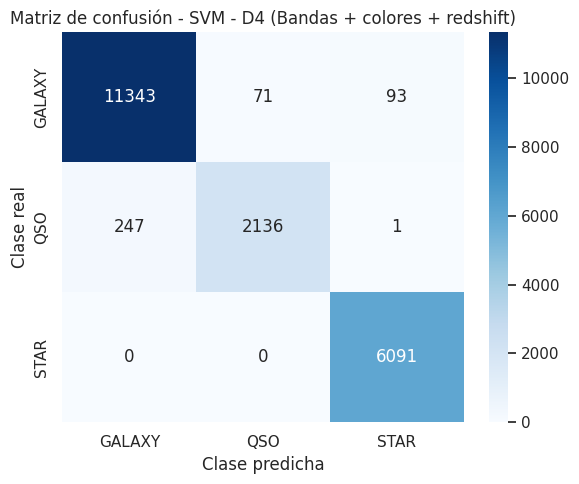

In [ ]:
# ============================================================
# SVM - MATRIZ DE CONFUSIÓN D4
# ============================================================

cm_svm_d4 = confusion_matrix(
    y_test_model,
    y_pred_svm_d4,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm_d4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de confusión - SVM - D4 (Bandas + colores + redshift)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


#### Interpretación de SVM - D4

En D4 la búsqueda seleccionó el kernel **lineal** con `C = 10`, con un F1 ponderado promedio de **0.9800** en validación cruzada (RBF: **0.9769**; polinómico: **0.9518**). Es la confirmación de lo observado en D3: cuando el `redshift` está disponible, una frontera recta es suficiente.

Sobre `test`, el F1 ponderado es **0.9791** y el F1 macro **0.9684**, levemente por debajo de D3 (**0.9825** y **0.9745**). Todas las estrellas del conjunto de test se clasifican correctamente (recall de `STAR` = 1.0000), pero aumentan los quásares confundidos con galaxias: de 188 en D3 a **247** en D4.

El mismo patrón apareció en KNN (D3: 0.9753; D4: 0.9684): **agregar los colores cuando ya se dispone del `redshift` no mejora el resultado**. Los colores son combinaciones de las mismas bandas que ya están en el dataset y no aportan información nueva; lo que agregan son cuatro dimensiones más, en las que el modelo tiene que repartir su atención.


In [ ]:
# ============================================================
# SVM - COMPARACIÓN DE LOS CUATRO DATASETS
# ============================================================

resultados_svm = pd.DataFrame({
    "D1 - Bandas": {
        "F1 CV": svm_grid_d1.best_score_,
        "Accuracy": accuracy_svm_d1,
        "Precision weighted": precision_svm_d1,
        "Recall weighted": recall_svm_d1,
        "F1 weighted": f1_weighted_svm_d1,
        "F1 macro": f1_macro_svm_d1
    },
    "D2 - Bandas + colores": {
        "F1 CV": svm_grid_d2.best_score_,
        "Accuracy": accuracy_svm_d2,
        "Precision weighted": precision_svm_d2,
        "Recall weighted": recall_svm_d2,
        "F1 weighted": f1_weighted_svm_d2,
        "F1 macro": f1_macro_svm_d2
    },
    "D3 - Bandas + redshift": {
        "F1 CV": svm_grid_d3.best_score_,
        "Accuracy": accuracy_svm_d3,
        "Precision weighted": precision_svm_d3,
        "Recall weighted": recall_svm_d3,
        "F1 weighted": f1_weighted_svm_d3,
        "F1 macro": f1_macro_svm_d3
    },
    "D4 - Bandas + colores + redshift": {
        "F1 CV": svm_grid_d4.best_score_,
        "Accuracy": accuracy_svm_d4,
        "Precision weighted": precision_svm_d4,
        "Recall weighted": recall_svm_d4,
        "F1 weighted": f1_weighted_svm_d4,
        "F1 macro": f1_macro_svm_d4
    }
}).T

resultados_svm.round(4)


,F1 CV,Accuracy,Precision weighted,Recall weighted,F1 weighted,F1 macro
D1 - Bandas,0.8970,0.9080,0.9060,0.9080,0.9064,0.8606
D2 - Bandas + colores,0.9013,0.9158,0.9143,0.9158,0.9145,0.8731
D3 - Bandas + redshift,0.9805,0.9826,0.9826,0.9826,0.9825,0.9745
D4 - Bandas + colores + redshift,0.9800,0.9794,0.9793,0.9794,0.9791,0.9684


In [ ]:
# ============================================================
# SVM - HIPERPARÁMETROS SELECCIONADOS
# ============================================================

hiperparametros_svm = pd.DataFrame({
    "D1 - Bandas": svm_grid_d1.best_params_,
    "D2 - Bandas + colores": svm_grid_d2.best_params_,
    "D3 - Bandas + redshift": svm_grid_d3.best_params_,
    "D4 - Bandas + colores + redshift": svm_grid_d4.best_params_
}).T

hiperparametros_svm


,model__C,model__class_weight,model__gamma,model__kernel
D1 - Bandas,100,None,0.5,rbf
D2 - Bandas + colores,1,None,1,rbf
D3 - Bandas + redshift,100,None,0.1,rbf
D4 - Bandas + colores + redshift,10,None,NaN,linear


                                     KNN     SVM
D1 - Bandas                       0.8972  0.9064
D2 - Bandas + colores             0.9079  0.9145
D3 - Bandas + redshift            0.9753  0.9825
D4 - Bandas + colores + redshift  0.9684  0.9791


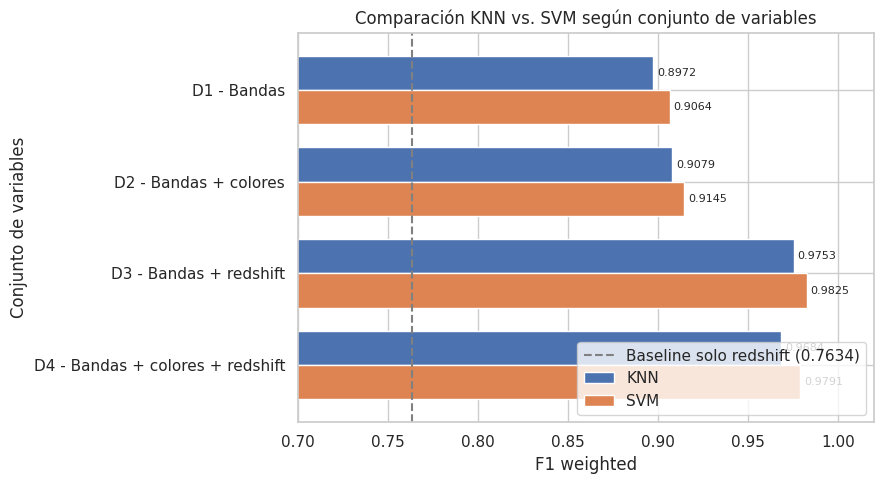

In [ ]:
# ============================================================
# COMPARACIÓN KNN vs. SVM (F1 WEIGHTED SOBRE TEST)
# ============================================================

comparacion_knn_svm = pd.DataFrame({
    "KNN": [f1_weighted_d1, f1_weighted_d2, f1_weighted_d3, f1_weighted_d4],
    "SVM": [f1_weighted_svm_d1, f1_weighted_svm_d2, f1_weighted_svm_d3, f1_weighted_svm_d4]
}, index=[
    "D1 - Bandas",
    "D2 - Bandas + colores",
    "D3 - Bandas + redshift",
    "D4 - Bandas + colores + redshift"
])

print(comparacion_knn_svm.round(4))

ax = comparacion_knn_svm.plot(
    kind="barh",
    figsize=(9, 5),
    width=0.75
)

ax.axvline(
    f1_baseline,
    color="gray",
    linestyle="--",
    label=f"Baseline solo redshift ({f1_baseline:.4f})"
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.4f", padding=3, fontsize=8)

ax.set_xlim(0.70, 1.02)
ax.set_xlabel("F1 weighted")
ax.set_ylabel("Conjunto de variables")
ax.set_title("Comparación KNN vs. SVM según conjunto de variables")
ax.invert_yaxis()
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


#### Conclusiones de SVM y comparación con KNN

| Dataset | F1 weighted KNN | F1 weighted SVM | Kernel SVM seleccionado |
|---|---:|---:|---|
| D1 - Bandas | 0.8972 | 0.9064 | RBF |
| D2 - Bandas + colores | 0.9079 | 0.9145 | RBF |
| D3 - Bandas + redshift | 0.9753 | 0.9825 | RBF (lineal casi igual) |
| D4 - Bandas + colores + redshift | 0.9684 | 0.9791 | Lineal |

**1. SVM supera a KNN en los cuatro datasets, pero por poco.** La diferencia está entre 0.7 y 1.1 puntos de F1 ponderado. Con la misma información, cambiar de algoritmo mueve el resultado alrededor de un punto.

**2. La información disponible pesa mucho más que el algoritmo.** Pasar de D1 a D3 (agregar el `redshift`) mejora el F1 ponderado en más de 7 puntos, tanto en KNN como en SVM. Los dos algoritmos cuentan la misma historia: el `redshift` es la variable que más separa las clases.

**3. El `redshift` cambia la forma del problema.** Sin él, las clases están entreveradas y hace falta una frontera curva (el kernel lineal queda en 0.79). Con él, una frontera recta alcanza (0.98). Esto también se refleja en los vectores de soporte, que bajan de 18.915 en D1 a 3.909 en D3.

**4. Los colores ayudan solo cuando falta el `redshift`.** Mejoran de D1 a D2 en ambos algoritmos, pero de D3 a D4 el resultado empeora levemente en ambos. Son una reescritura de las bandas: útiles para mostrar al modelo la información fotométrica de otra forma, pero sin aportar nada nuevo cuando ya está la variable más informativa.

**5. El quásar es la clase difícil sin `redshift`.** Con las bandas solas, cerca de 500 quásares se confunden con estrellas, porque en la imagen ambos se ven como un punto. Con el `redshift`, esa confusión prácticamente desaparece (1 caso en D3).

**6. Costo computacional.** SVM requirió buscar hiperparámetros sobre una submuestra de 10.000 observaciones, porque una búsqueda completa sobre `train` habría llevado horas. KNN no tuvo esa limitación. La mejora de alrededor de un punto que ofrece SVM tiene, por lo tanto, un costo de cómputo mayor, algo a tener en cuenta en la comparación final de algoritmos (requisito 4).


# 6. Modelado: Árboles de decisión

## 6.1. ¿Cómo funciona un árbol de decisión?

Un árbol de decisión clasifica una observación mediante una **secuencia de preguntas** del tipo *"¿la variable X es menor o igual que un umbral?"*. Cada pregunta divide los datos en dos grupos; el proceso se repite sobre cada grupo hasta llegar a una **hoja**, que predice la clase mayoritaria de las observaciones de `train` que cayeron en ella.

En cada nodo, el algoritmo evalúa todas las variables y todos los umbrales posibles y elige la división que más **reduce la impureza** de los grupos resultantes. Las dos medidas de impureza más usadas son:

$$
\text{Gini} = 1 - \sum_{k} p_k^2
\qquad\qquad
\text{Entropía} = -\sum_{k} p_k \log_2 p_k
$$

donde $p_k$ es la proporción de observaciones de la clase $k$ dentro del nodo. Un nodo puro (una sola clase) tiene impureza 0.

Hay una conexión directa con el baseline: la regla de dos umbrales sobre `redshift` es, en realidad, **un árbol de profundidad 2 con una sola variable y umbrales fijados a mano** (puntos medios entre medianas). Un árbol de decisión hace lo mismo, pero **aprende los umbrales a partir de los datos** y puede combinar todas las variables disponibles.

## 6.2. ¿Hace falta escalar las variables?

**No.** Cada división compara una única variable contra un umbral, y ese orden no cambia si la variable se estandariza o se transforma de forma monótona. A diferencia de KNN y SVM, el árbol no depende de distancias ni de productos internos, de modo que **no se utiliza `StandardScaler`** y el modelo se entrena directamente con las variables originales (criterio definido en la sección de escalado).

## 6.3. Sobreajuste e hiperparámetros

Si no se lo limita, un árbol sigue dividiendo hasta que cada hoja es pura: **memoriza `train`** y generaliza mal. Los hiperparámetros controlan cuánto puede crecer:

- `criterion`: medida de impureza (`gini` o `entropy`).
- `max_depth`: profundidad máxima del árbol.
- `min_samples_leaf`: cantidad mínima de observaciones que debe tener cada hoja. Evita hojas con muy pocos casos.
- `class_weight`: `None` o `"balanced"`. Con `"balanced"` se da más peso a las clases minoritarias (`QSO`), igual que en SVM.

## 6.4. Estrategia de evaluación

Se mantiene el mismo esquema que en KNN y SVM:

- los cuatro datasets (D1 a D4) con la **misma partición** `train/test`;
- `GridSearchCV` con **5 folds** y **F1 ponderado** como métrica de selección;
- el `test` solo se usa para la evaluación final.

Un árbol se entrena en una fracción del tiempo que requiere un SVM, por lo que la búsqueda se hace sobre el **`train` completo**, sin submuestra.

Además de las métricas sobre `test`, se calcula el F1 ponderado sobre `train`. La diferencia entre ambos es un indicador directo de **sobreajuste**.

In [ ]:
# ============================================================
# ÁRBOLES - IMPORTACIÓN DE LIBRERÍAS Y DATASETS
# ============================================================

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Los cuatro datasets (train, test) en un diccionario, para recorrerlos
# de a uno con exactamente el mismo procedimiento.
datasets = {
    "D1 - Bandas":                      (X_bands_train,          X_bands_test),
    "D2 - Bandas + colores":            (X_bands_colors_train,   X_bands_colors_test),
    "D3 - Bandas + redshift":           (X_bands_redshift_train, X_bands_redshift_test),
    "D4 - Bandas + colores + redshift": (X_all_train,            X_all_test),
}

clases_orden = ["GALAXY", "QSO", "STAR"]

for nombre, (X_tr, X_te) in datasets.items():
    print(f"{nombre:35s} train: {X_tr.shape}  test: {X_te.shape}")

D1 - Bandas                         train: (79927, 5)  test: (19982, 5)
D2 - Bandas + colores               train: (79927, 9)  test: (19982, 9)
D3 - Bandas + redshift              train: (79927, 6)  test: (19982, 6)
D4 - Bandas + colores + redshift    train: (79927, 10)  test: (19982, 10)


In [ ]:
# ============================================================
# ÁRBOLES - GRILLA DE HIPERPARÁMETROS
# ============================================================

# No hay Pipeline ni StandardScaler: el árbol no necesita escalado.

arbol_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 8, 12, 16, None],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "class_weight": [None, "balanced"]
}

n_comb = (
    len(arbol_param_grid["criterion"])
    * len(arbol_param_grid["max_depth"])
    * len(arbol_param_grid["min_samples_leaf"])
    * len(arbol_param_grid["class_weight"])
)
print("Combinaciones por dataset:", n_comb)
print("Ajustes por dataset (x5 folds):", n_comb * 5)

arbol_param_grid

Combinaciones por dataset: 120
Ajustes por dataset (x5 folds): 600


{'criterion': ['gini', 'entropy'],
 'max_depth': [3, 5, 8, 12, 16, None],
 'min_samples_leaf': [1, 5, 10, 20, 50],
 'class_weight': [None, 'balanced']}

In [ ]:
# ============================================================
# ÁRBOLES - BÚSQUEDA DE HIPERPARÁMETROS (D1 A D4)
# ============================================================

arbol_grids = {}

for nombre, (X_tr, X_te) in datasets.items():

    grid = GridSearchCV(
        estimator=DecisionTreeClassifier(random_state=SEMILLA),
        param_grid=arbol_param_grid,
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
        refit=True
    )

    grid.fit(X_tr, y_train_model)
    arbol_grids[nombre] = grid

    print(nombre)
    print("  Mejores hiperparámetros:", grid.best_params_)
    print("  Mejor F1 ponderado en validación cruzada:", round(grid.best_score_, 4))
    print()

D1 - Bandas
  Mejores hiperparámetros: {'class_weight': None, 'criterion': 'gini', 'max_depth': 16, 'min_samples_leaf': 5}
  Mejor F1 ponderado en validación cruzada: 0.8666

D2 - Bandas + colores
  Mejores hiperparámetros: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 16, 'min_samples_leaf': 20}
  Mejor F1 ponderado en validación cruzada: 0.8969

D3 - Bandas + redshift
  Mejores hiperparámetros: {'class_weight': None, 'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 10}
  Mejor F1 ponderado en validación cruzada: 0.9846

D4 - Bandas + colores + redshift
  Mejores hiperparámetros: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 50}
  Mejor F1 ponderado en validación cruzada: 0.9859



#### Comentarios sobre la búsqueda de hiperparámetros del árbol

La validación cruzada eligió `class_weight = None` en los cuatro datasets, es decir, no hizo falta dar más peso a `QSO`. Sin `redshift` (D1 y D2) el árbol seleccionado es más profundo (16 niveles); con `redshift` (D3 y D4) basta con 12 niveles. El F1 ponderado en validación cruzada sube de 0.8666 en D1 a 0.9846 en D3, el mismo salto que se vio en KNN y SVM.

In [ ]:
# ============================================================
# ÁRBOLES - EVALUACIÓN SOBRE TEST (D1 A D4)
# ============================================================

arbol_pred = {}
arbol_metricas = {}

for nombre, (X_tr, X_te) in datasets.items():

    mejor = arbol_grids[nombre].best_estimator_
    y_pred = mejor.predict(X_te)
    arbol_pred[nombre] = y_pred

    arbol_metricas[nombre] = {
        "F1 CV": arbol_grids[nombre].best_score_,
        "Accuracy": accuracy_score(y_test_model, y_pred),
        "Precision weighted": precision_score(y_test_model, y_pred, average="weighted", zero_division=0),
        "Recall weighted": recall_score(y_test_model, y_pred, average="weighted", zero_division=0),
        "F1 weighted": f1_score(y_test_model, y_pred, average="weighted", zero_division=0),
        "F1 macro": f1_score(y_test_model, y_pred, average="macro", zero_division=0),
        # Diagnóstico de sobreajuste: F1 sobre el propio train
        "F1 weighted (train)": f1_score(y_train_model, mejor.predict(X_tr), average="weighted", zero_division=0),
    }

resultados_arbol = pd.DataFrame(arbol_metricas).T
resultados_arbol["Brecha train - test"] = (
    resultados_arbol["F1 weighted (train)"] - resultados_arbol["F1 weighted"]
)

resultados_arbol.round(4)

,F1 CV,Accuracy,Precision weighted,Recall weighted,F1 weighted,F1 macro,F1 weighted (train),Brecha train - test
D1 - Bandas,0.8666,0.8716,0.8699,0.8716,0.8704,0.8210,0.9222,0.0518
D2 - Bandas + colores,0.8969,0.9033,0.9018,0.9033,0.9023,0.8574,0.9175,0.0152
D3 - Bandas + redshift,0.9846,0.9847,0.9846,0.9847,0.9846,0.9744,0.9878,0.0032
D4 - Bandas + colores + redshift,0.9859,0.9868,0.9867,0.9868,0.9867,0.9780,0.9870,0.0003


#### Comentarios sobre las métricas del árbol en test

El F1 ponderado en test es 0.8704 (D1), 0.9023 (D2), 0.9846 (D3) y 0.9867 (D4), muy cercano al valor de validación cruzada en cada caso. Esto indica que la selección de hiperparámetros no quedó ajustada a los datos de entrenamiento.

La brecha entre train y test es de 0.0518 en D1 y baja a 0.0003 en D4. El árbol sobreajusta más cuando solo tiene las bandas, y casi nada cuando cuenta con el `redshift`. Con los colores, el árbol mejora respecto de D1 y también reduce esa brecha.

In [ ]:
# ============================================================
# ÁRBOLES - HIPERPARÁMETROS SELECCIONADOS Y TAMAÑO DEL ÁRBOL
# ============================================================

hiperparametros_arbol = pd.DataFrame(
    {nombre: grid.best_params_ for nombre, grid in arbol_grids.items()}
).T

hiperparametros_arbol["profundidad real"] = [
    arbol_grids[n].best_estimator_.get_depth() for n in hiperparametros_arbol.index
]
hiperparametros_arbol["cantidad de hojas"] = [
    arbol_grids[n].best_estimator_.get_n_leaves() for n in hiperparametros_arbol.index
]

hiperparametros_arbol

,class_weight,criterion,max_depth,min_samples_leaf,profundidad real,cantidad de hojas
D1 - Bandas,None,gini,16,5,16,2891
D2 - Bandas + colores,None,entropy,16,20,16,1278
D3 - Bandas + redshift,None,gini,12,10,12,331
D4 - Bandas + colores + redshift,None,entropy,12,50,12,206


#### Comentarios sobre el tamaño de los árboles

El árbol de D1 tiene 2891 hojas y el de D4 solo 206. Sin `redshift` hacen falta muchas divisiones pequeñas para separar clases que se superponen. Con `redshift`, pocas reglas son suficientes. Esto es coherente con el resultado de SVM, donde con `redshift` una frontera recta ya alcanzaba.

In [ ]:
# ============================================================
# ÁRBOLES - CLASSIFICATION REPORT (D1 A D4)
# ============================================================

for nombre in datasets:
    print(f"Árbol de decisión - {nombre}")
    print("-" * 60)
    print(
        classification_report(
            y_test_model,
            arbol_pred[nombre],
            digits=4,
            zero_division=0
        )
    )

Árbol de decisión - D1 - Bandas
------------------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9200    0.9341    0.9270     11507
         QSO     0.7532    0.6707    0.7096      2384
        STAR     0.8209    0.8322    0.8265      6091

    accuracy                         0.8716     19982
   macro avg     0.8313    0.8124    0.8210     19982
weighted avg     0.8699    0.8716    0.8704     19982

Árbol de decisión - D2 - Bandas + colores
------------------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9425    0.9576    0.9500     11507
         QSO     0.7873    0.7173    0.7507      2384
        STAR     0.8696    0.8736    0.8716      6091

    accuracy                         0.9033     19982
   macro avg     0.8665    0.8495    0.8574     19982
weighted avg     0.9018    0.9033    0.9023     19982

Árbol de decisión - D3 - Bandas + redshift

#### Comentarios sobre el reporte por clase del árbol

`STAR` y `GALAXY` se clasifican bien en todos los casos. La clase difícil es `QSO`: su recall es 0.6707 en D1 y 0.7173 en D2, y sube a 0.9207 en D3 y 0.9295 en D4. Con `redshift`, las estrellas quedan casi sin error (F1 de 0.9990 en D3 y 0.9989 en D4).

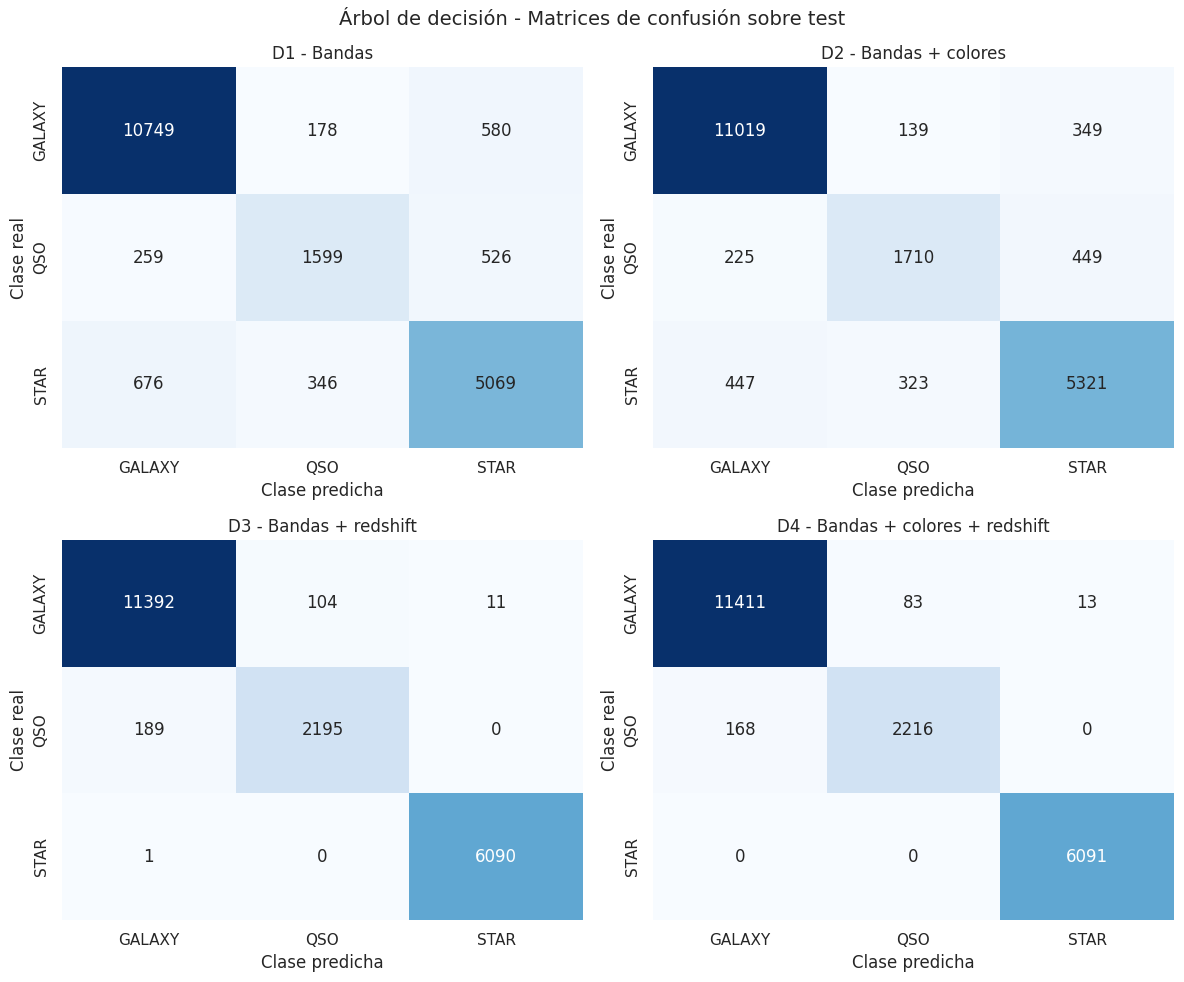

In [ ]:
# ============================================================
# ÁRBOLES - MATRICES DE CONFUSIÓN (D1 A D4)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (nombre, y_pred) in zip(axes.ravel(), arbol_pred.items()):

    cm = confusion_matrix(y_test_model, y_pred, labels=clases_orden)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=clases_orden,
        yticklabels=clases_orden,
        cbar=False,
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.suptitle("Árbol de decisión - Matrices de confusión sobre test", fontsize=14)
plt.tight_layout()
plt.show()

#### Comentarios sobre las matrices de confusión del árbol

Sin `redshift`, los quásares se confunden sobre todo con estrellas (526 casos en D1 y 449 en D2), porque ambos aparecen como un punto en la imagen. Con `redshift`, esa confusión desaparece (0 casos en D3 y D4). El error que queda es de quásares clasificados como galaxias: 189 en D3 y 168 en D4. En D4 el árbol clasifica bien las 6091 estrellas de test.

### Visualización del árbol

- El siguiente arbol visualizado muestra lo obvio, es decir, que redshift aparece en la raíz y ese es un resultado esperado, porque el árbol elige en cada nodo la variable que mejor separa las clases.

- Luego en la celda subsiguiente si se muestra el arbol entrenado sin redshift (D2) el cual muestra qué variables fotométricas separan las clases cuando falta el redshift.

- En este caso (con redshift) se grafican solamente los primeros niveles del árbol seleccionado para D3 (bandas + `redshift`), junto con las reglas en formato texto. El color de cada nodo indica la clase mayoritaria y su intensidad, la pureza del nodo.

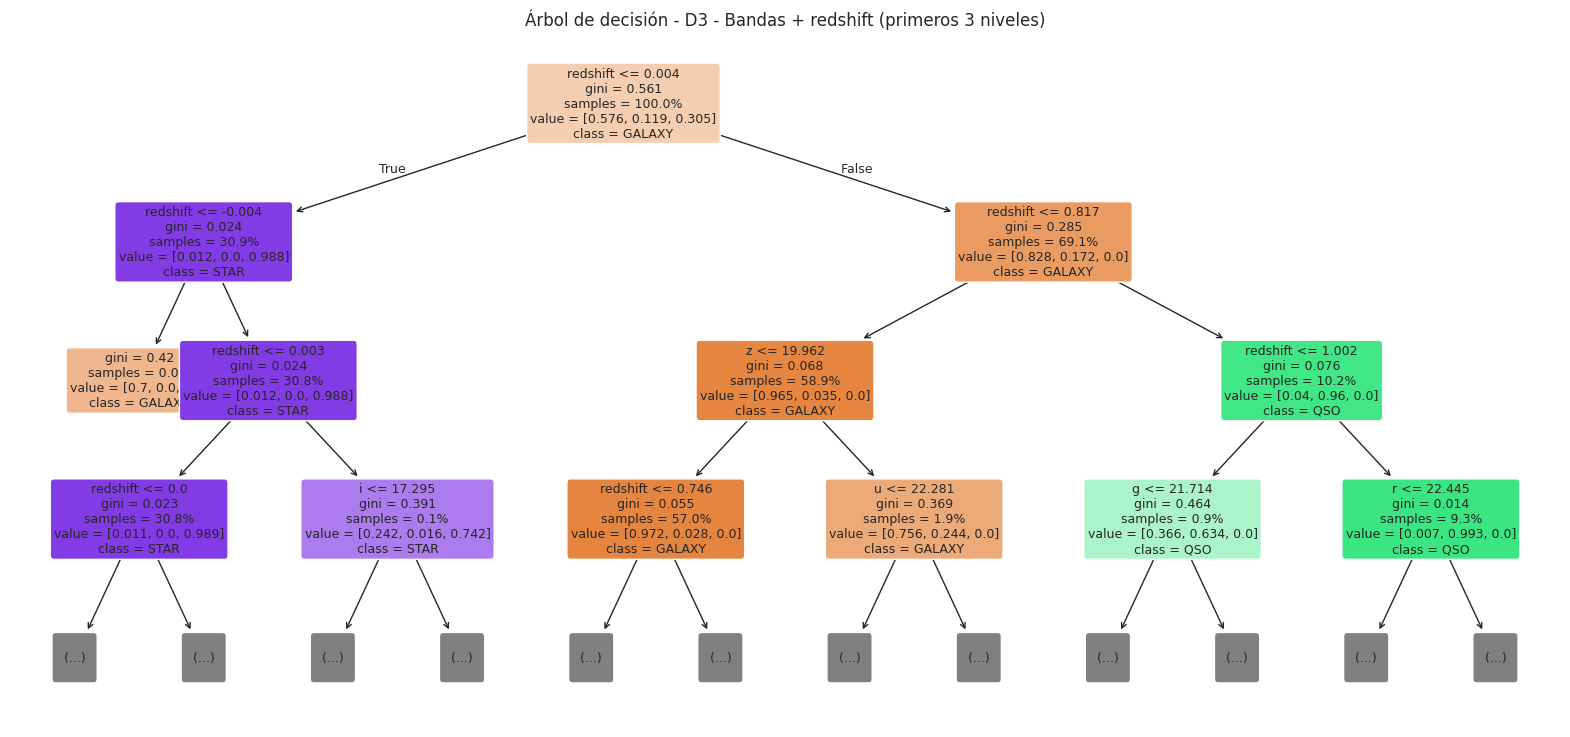

Reglas del árbol (primeros 3 niveles):

|--- redshift <= 0.00
|   |--- redshift <= -0.00
|   |   |--- class: GALAXY
|   |--- redshift >  -0.00
|   |   |--- redshift <= 0.00
|   |   |   |--- redshift <= 0.00
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- redshift >  0.00
|   |   |   |   |--- truncated branch of depth 9
|   |   |--- redshift >  0.00
|   |   |   |--- i <= 17.30
|   |   |   |   |--- class: GALAXY
|   |   |   |--- i >  17.30
|   |   |   |   |--- truncated branch of depth 3
|--- redshift >  0.00
|   |--- redshift <= 0.82
|   |   |--- z <= 19.96
|   |   |   |--- redshift <= 0.75
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- redshift >  0.75
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- z >  19.96
|   |   |   |--- u <= 22.28
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- u >  22.28
|   |   |   |   |--- truncated branch of depth 9
|   |--- redshift >  0.82
|   |   |--- redshift <= 1.00
|   |   |   |--- g 

In [ ]:
# ============================================================
# ÁRBOLES - VISUALIZACIÓN DEL ÁRBOL SELECCIONADO PARA D3
# ============================================================

nombre_vis = "D3 - Bandas + redshift"
arbol_vis = arbol_grids[nombre_vis].best_estimator_
columnas_vis = list(datasets[nombre_vis][0].columns)

plt.figure(figsize=(20, 9))

plot_tree(
    arbol_vis,
    feature_names=columnas_vis,
    class_names=list(arbol_vis.classes_),
    max_depth=3,          # solo se dibujan los primeros niveles
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9
)

plt.title(f"Árbol de decisión - {nombre_vis} (primeros 3 niveles)")
plt.show()

print("Reglas del árbol (primeros 3 niveles):\n")
print(export_text(arbol_vis, feature_names=columnas_vis, max_depth=3))

#### Comentarios sobre el árbol dibujado

La primera pregunta del árbol de D3 es sobre el `redshift`, con un umbral cercano a cero. Esa división separa las estrellas, que no se alejan, del resto. En el segundo nivel el árbol vuelve a usar el `redshift`, con umbrales cercanos a 0.82 y 1.00, para separar galaxias de quásares. Las bandas (`i`, `z`, `u`, `g`, `r`) aparecen recién en los niveles siguientes, para resolver los casos dudosos. Los umbrales cercanos a cero se muestran como 0.00 por el redondeo del gráfico.

### Cómo leer los resultados de los árboles

Al revisar las tablas y gráficos anteriores conviene responder estas preguntas con los números obtenidos en la ejecución:

- **¿Se repite el patrón de KNN y SVM?** Comparar el F1 ponderado de D1 → D2 (efecto de los colores), D1 → D3 (efecto del `redshift`) y D3 → D4 (colores cuando ya está el `redshift`).
- **¿Hay sobreajuste?** Mirar la columna *Brecha train - test*. Una brecha grande indica que el árbol memoriza `train`; la validación cruzada eligió `max_depth` y `min_samples_leaf` justamente para limitarla.
- **¿Qué clase es la más difícil?** Revisar el recall de `QSO` y la matriz de confusión: sin `redshift`, el error esperable es confundir quásares con estrellas.
- **¿Qué variable usa el árbol en la raíz de D3?** El gráfico muestra con qué pregunta empieza el árbol. Es la variable que, por sí sola, mejor separa las clases.

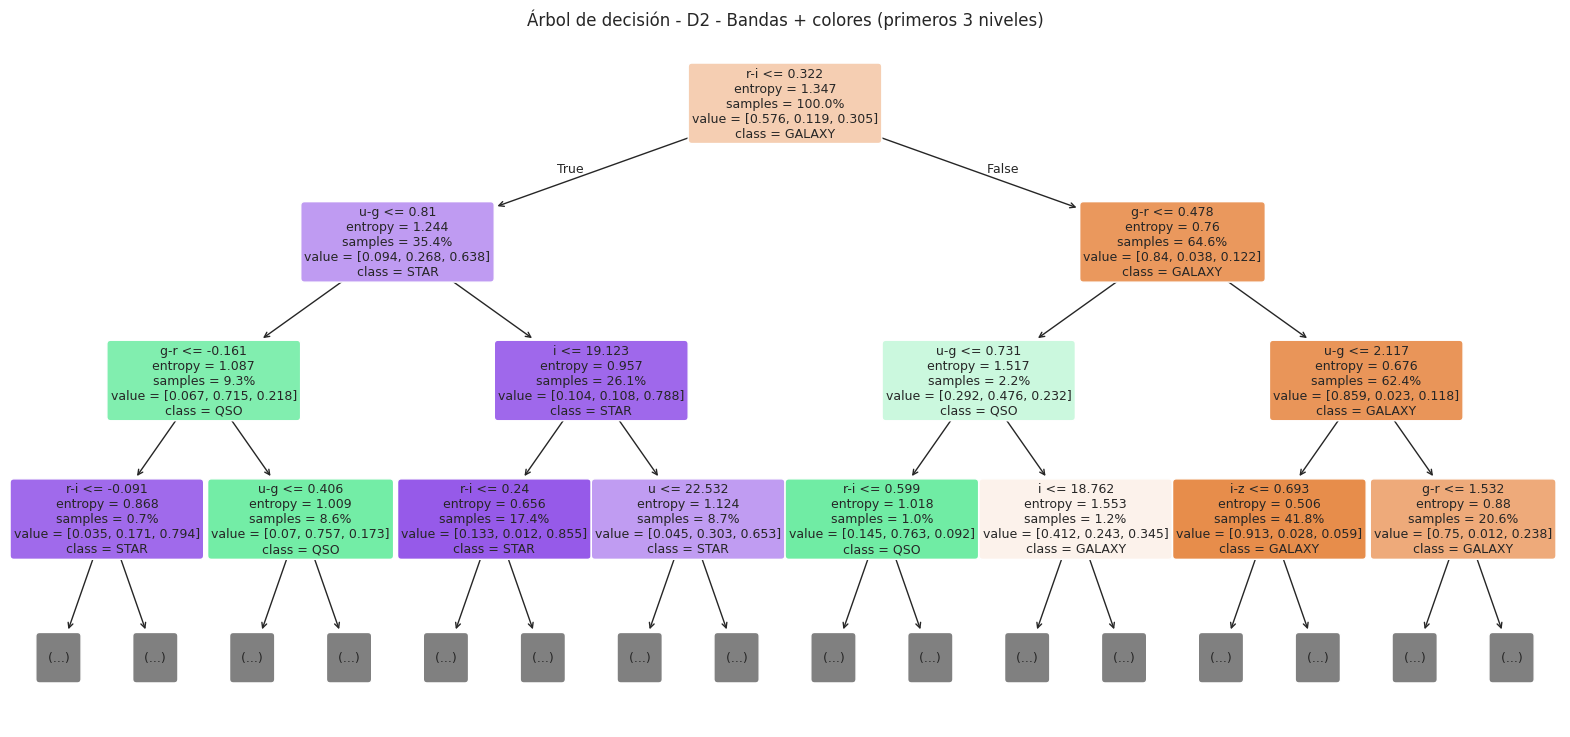

Reglas del árbol (primeros 3 niveles):

|--- r-i <= 0.32
|   |--- u-g <= 0.81
|   |   |--- g-r <= -0.16
|   |   |   |--- r-i <= -0.09
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- r-i >  -0.09
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- g-r >  -0.16
|   |   |   |--- u-g <= 0.41
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- u-g >  0.41
|   |   |   |   |--- truncated branch of depth 13
|   |--- u-g >  0.81
|   |   |--- i <= 19.12
|   |   |   |--- r-i <= 0.24
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- r-i >  0.24
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- i >  19.12
|   |   |   |--- u <= 22.53
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- u >  22.53
|   |   |   |   |--- truncated branch of depth 13
|--- r-i >  0.32
|   |--- g-r <= 0.48
|   |   |--- u-g <= 0.73
|   |   |   |--- r-i <= 0.60
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- r-i >  0.60


In [ ]:
# ============================================================
# ÁRBOLES - VISUALIZACIÓN DEL ÁRBOL SELECCIONADO PARA D2 (SIN REDSHIFT)
# ============================================================

nombre_vis = "D2 - Bandas + colores"
arbol_vis = arbol_grids[nombre_vis].best_estimator_
columnas_vis = list(datasets[nombre_vis][0].columns)

plt.figure(figsize=(20, 9))

plot_tree(
    arbol_vis,
    feature_names=columnas_vis,
    class_names=list(arbol_vis.classes_),
    max_depth=3,
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9
)

plt.title(f"Árbol de decisión - {nombre_vis} (primeros 3 niveles)")
plt.show()

print("Reglas del árbol (primeros 3 niveles):\n")
print(export_text(arbol_vis, feature_names=columnas_vis, max_depth=3))

#### Comentarios sobre el árbol de D2 (sin redshift)

- La primera pregunta del árbol es si el color `r-i` es menor o igual a 0.322. Después usa los colores `u-g` y `g-r`. Esto coincide con el gráfico de importancia, donde `r-i` era la variable más usada.

- Los objetos con `r-i` bajo son sobre todo estrellas y quásares. Entre ellos, los que además tienen `u-g` bajo son quásares en un 71.5 %. Los objetos con `r-i` alto son sobre todo galaxias.

- Después de tres preguntas todavía quedan grupos mezclados. Por ejemplo, hay uno con 41 % de galaxias, 24 % de quásares y 35 % de estrellas. Sin `redshift`, los colores solos no alcanzan para separar bien las tres clases.

# 7. Modelado: Ensambles de árboles

## 7.1. ¿Qué es un ensamble?

Un árbol individual es inestable: un cambio pequeño en `train` puede producir un árbol muy distinto. Un **ensamble** combina muchos árboles para obtener un modelo más estable y preciso que cualquiera de ellos por separado. Hay dos estrategias principales, y se evalúa una de cada tipo:

**Bagging: Random Forest (`RandomForestClassifier`).**
Se entrenan muchos árboles **en paralelo e independientes**. Cada uno se ajusta sobre una muestra con reemplazo (*bootstrap*) de `train` y, en cada división, solo considera un subconjunto aleatorio de las variables. La predicción final es el **voto** de todos los árboles. Al promediar árboles distintos entre sí, se **reduce la varianza** (el sobreajuste) sin aumentar el sesgo.

**Boosting: Gradient Boosting (`HistGradientBoostingClassifier`).**
Se entrenan árboles **pequeños en secuencia**: cada árbol nuevo se concentra en corregir los errores que cometió el ensamble hasta ese momento. Se suma su aporte multiplicado por una tasa de aprendizaje (`learning_rate`). Al ir corrigiendo errores, se **reduce el sesgo**. Se usa la implementación basada en histogramas porque es mucho más rápida con decenas de miles de observaciones y es conceptualmente equivalente al `GradientBoostingClassifier`.

## 7.2. Escalado

Igual que con un árbol individual, ambos ensambles están formados por árboles y **no requieren escalado**. Se entrenan sobre las variables originales, sin `Pipeline`.

## 7.3. Hiperparámetros

| Modelo | Hiperparámetro | Qué controla |
|---|---|---|
| Random Forest | `n_estimators` | cantidad de árboles |
| | `max_depth` | profundidad máxima de cada árbol |
| | `min_samples_leaf` | tamaño mínimo de cada hoja |
| | `max_features` | variables que se consideran en cada división |
| | `class_weight` | peso de las clases (`None` o `"balanced"`) |
| Gradient Boosting | `learning_rate` | cuánto aporta cada árbol nuevo |
| | `max_iter` | cantidad de árboles (iteraciones de boosting) |
| | `max_leaf_nodes` | complejidad de cada árbol individual |
| | `class_weight` | peso de las clases (`None` o `"balanced"`) |

## 7.4. Costo computacional y estrategia de búsqueda

Entrenar un ensamble cuesta más que entrenar un árbol (son cientos de árboles). Por eso se sigue la misma estrategia que en SVM:

1. la **búsqueda de hiperparámetros** se hace sobre la **submuestra estratificada de 10.000 observaciones** de `train` (`idx_svm`), con validación cruzada de 5 folds y F1 ponderado;
2. el modelo con los mejores hiperparámetros se **reentrena sobre el `train` completo**;
3. el modelo reentrenado se evalúa sobre `test`.

Se reutiliza la misma submuestra que en SVM, de modo que la búsqueda de hiperparámetros se hace bajo las mismas condiciones para todos los algoritmos costosos. El `test` no participa en ninguna decisión.

In [ ]:
# ============================================================
# ENSAMBLES - IMPORTACIÓN, MODELOS Y GRILLAS
# ============================================================

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

ensambles = {
    "Random Forest": {
        "estimador": RandomForestClassifier(random_state=SEMILLA, n_jobs=-1),
        "param_grid": {
            "n_estimators": [200],
            "max_depth": [10, None],
            "min_samples_leaf": [1, 5],
            "max_features": ["sqrt", 0.6],
            "class_weight": [None, "balanced"]
        }
    },
    "Gradient Boosting": {
        # early_stopping=False: el número de iteraciones lo decide la grilla,
        # no una partición interna aleatoria
        "estimador": HistGradientBoostingClassifier(random_state=SEMILLA, early_stopping=False),
        "param_grid": {
            "learning_rate": [0.05, 0.1, 0.2],
            "max_iter": [100, 300],
            "max_leaf_nodes": [15, 31],
            "class_weight": [None, "balanced"]
        }
    }
}

for modelo, cfg in ensambles.items():
    n = 1
    for valores in cfg["param_grid"].values():
        n *= len(valores)
    print(f"{modelo:18s} combinaciones: {n:3d}   ajustes por dataset (x5 folds): {n * 5}")

print("\nObservaciones en la submuestra de búsqueda:", len(idx_svm))

Random Forest      combinaciones:  16   ajustes por dataset (x5 folds): 80
Gradient Boosting  combinaciones:  24   ajustes por dataset (x5 folds): 120

Observaciones en la submuestra de búsqueda: 10000


In [ ]:
# ============================================================
# ENSAMBLES - BÚSQUEDA DE HIPERPARÁMETROS (SUBMUESTRA)
# ============================================================
# Para cada modelo y cada dataset: GridSearchCV sobre la submuestra de 10.000
# observaciones. Los mismos índices (idx_svm) que se usaron para SVM.
#
# Nota de ejecución: en el Random Forest, n_jobs=-1 está en el estimador y
# GridSearchCV corre en serie, para no saturar la CPU con paralelismo anidado.

ens_grids = {}

for modelo, cfg in ensambles.items():
    for nombre, (X_tr, X_te) in datasets.items():

        grid = GridSearchCV(
            estimator=cfg["estimador"],
            param_grid=cfg["param_grid"],
            cv=5,
            scoring="f1_weighted",
            n_jobs=1 if modelo == "Random Forest" else -1,
            refit=True
        )

        grid.fit(X_tr.loc[idx_svm], y_svm)
        ens_grids[(modelo, nombre)] = grid

        print(f"{modelo} - {nombre}")
        print("  Mejores hiperparámetros:", grid.best_params_)
        print("  Mejor F1 ponderado en validación cruzada:", round(grid.best_score_, 4))
        print()

Random Forest - D1 - Bandas
  Mejores hiperparámetros: {'class_weight': None, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
  Mejor F1 ponderado en validación cruzada: 0.8732

Random Forest - D2 - Bandas + colores
  Mejores hiperparámetros: {'class_weight': None, 'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 1, 'n_estimators': 200}
  Mejor F1 ponderado en validación cruzada: 0.9012

Random Forest - D3 - Bandas + redshift
  Mejores hiperparámetros: {'class_weight': None, 'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 1, 'n_estimators': 200}
  Mejor F1 ponderado en validación cruzada: 0.9868

Random Forest - D4 - Bandas + colores + redshift
  Mejores hiperparámetros: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 0.6, 'min_samples_leaf': 1, 'n_estimators': 200}
  Mejor F1 ponderado en validación cruzada: 0.987

Gradient Boosting - D1 - Bandas
  Mejores hiperparámetros: {'class_weight': None, 'learning_rate

#### Comentarios sobre la búsqueda de hiperparámetros de los ensambles

- Para no tardar horas, la búsqueda de la mejor configuración de cada modelo se hizo con 10.000 filas elegidas al azar.
- El F1 ponderado en validación cruzada obtenido por los modelos varia desde 0.87 a 0.99, es decir, con solo las bandas (D1) saca cerca de 0.87, y con todas las variables, incluido el redshift (D4), cerca de 0.99
- El Random Forest probó varias configuraciones y se quedó con la que daba mejor nota. En 3 datasets le convino dejar que cada árbol crezca todo lo que quiera. En cambio en D4 (con redshift), le convino limitar los árboles a 10 niveles y darles más peso a las clases que tienen menos casos es decir los quásares.
- Dado que Gradient Boosting construye árboles reducidos, uno después de otro, y cada uno corrige errores del anterior, en este caso podía usar 100 o 300 árboles. En 3 datasets le fue mejor con 300.



In [ ]:
# ============================================================
# ENSAMBLES - REENTRENAMIENTO SOBRE TRAIN COMPLETO
# ============================================================
# clone() copia la configuración ganadora sin entrenar; luego se ajusta
# sobre las 79.927 observaciones de train.

ens_finales = {}

for (modelo, nombre), grid in ens_grids.items():

    X_tr, X_te = datasets[nombre]

    final = clone(grid.best_estimator_)
    final.fit(X_tr, y_train_model)
    ens_finales[(modelo, nombre)] = final

    print("Reentrenado:", modelo, "-", nombre)

Reentrenado: Random Forest - D1 - Bandas
Reentrenado: Random Forest - D2 - Bandas + colores
Reentrenado: Random Forest - D3 - Bandas + redshift
Reentrenado: Random Forest - D4 - Bandas + colores + redshift
Reentrenado: Gradient Boosting - D1 - Bandas
Reentrenado: Gradient Boosting - D2 - Bandas + colores
Reentrenado: Gradient Boosting - D3 - Bandas + redshift
Reentrenado: Gradient Boosting - D4 - Bandas + colores + redshift


In [ ]:
# ============================================================
# ENSAMBLES - EVALUACIÓN SOBRE TEST
# ============================================================

ens_pred = {}
filas_ens = []

for (modelo, nombre), final in ens_finales.items():

    X_tr, X_te = datasets[nombre]
    y_pred = final.predict(X_te)
    ens_pred[(modelo, nombre)] = y_pred

    filas_ens.append({
        "Modelo": modelo,
        "Dataset": nombre,
        "F1 CV": ens_grids[(modelo, nombre)].best_score_,
        "Accuracy": accuracy_score(y_test_model, y_pred),
        "Precision weighted": precision_score(y_test_model, y_pred, average="weighted", zero_division=0),
        "Recall weighted": recall_score(y_test_model, y_pred, average="weighted", zero_division=0),
        "F1 weighted": f1_score(y_test_model, y_pred, average="weighted", zero_division=0),
        "F1 macro": f1_score(y_test_model, y_pred, average="macro", zero_division=0),
    })

resultados_ens = pd.DataFrame(filas_ens).set_index(["Modelo", "Dataset"])
resultados_ens.round(4)

F1 CV  Accuracy  Precision weighted  Recall weighted  \
Modelo            Dataset                                                                                   
Random Forest     D1 - Bandas                       0.8732    0.9021              0.9007           0.9021   
                  D2 - Bandas + colores             0.9012    0.9150              0.9135           0.9150   
                  D3 - Bandas + redshift            0.9868    0.9876              0.9876           0.9876   
                  D4 - Bandas + colores + redshift  0.9870    0.9876              0.9876           0.9876   
Gradient Boosting D1 - Bandas                       0.8681    0.9008              0.8994           0.9008   
                  D2 - Bandas + colores             0.9008    0.9148              0.9133           0.9148   
                  D3 - Bandas + redshift            0.9843    0.9756              0.9756           0.9756   
                  D4 - Bandas + colores + redshift  0.9859    0.9862              0.9862           0.9862   

                                                    F1 weighted  F1 macro  
Modelo            Dataset                                                  
Random Forest     D1 - Bandas                            0.9011    0.8572  
                  D2 - Bandas + colores                  0.9139    0.8718  
                  D3 - Bandas + redshift                 0.9875    0.9794  
                  D4 - Bandas + colores + redshift       0.9876    0.9795  
Gradient Boosting D1 - Bandas                            0.8997    0.8553  
                  D2 - Bandas + colores                  0.9137    0.8715  
                  D3 - Bandas + redshift                 0.9756    0.9640  
                  D4 - Bandas + colores + redshift       0.9862    0.9788

#### Comentarios sobre las métricas de los ensambles en test

El F1 ponderado de Random Forest en test es 0.9011, 0.9139, 0.9875 y 0.9876 para D1 a D4. El de Gradient Boosting es 0.8997, 0.9137, 0.9756 y 0.9862. Los valores son cercanos a los de validación cruzada, por lo que el reentrenamiento sobre el train completo no cambió el comportamiento observado en la submuestra.

Ambos ensambles superan al árbol individual en D1 y D2 (por ejemplo, 0.9011 frente a 0.8704 en D1). En D3 y D4 la ventaja de Random Forest sobre el árbol es de pocas milésimas. Gradient Boosting en D3 (0.9756) queda por debajo del árbol (0.9846) y de Random Forest (0.9875).

In [ ]:
# ============================================================
# ENSAMBLES - HIPERPARÁMETROS SELECCIONADOS
# ============================================================

for modelo in ensambles:
    print(modelo)
    display(
        pd.DataFrame(
            {nombre: ens_grids[(modelo, nombre)].best_params_ for nombre in datasets}
        ).T
    )

Random Forest


,class_weight,max_depth,max_features,min_samples_leaf,n_estimators
D1 - Bandas,None,None,sqrt,1,200
D2 - Bandas + colores,NaN,NaN,0.6,1.0,200.0
D3 - Bandas + redshift,NaN,NaN,0.6,1.0,200.0
D4 - Bandas + colores + redshift,balanced,10,0.6,1,200


Gradient Boosting


,class_weight,learning_rate,max_iter,max_leaf_nodes
D1 - Bandas,NaN,0.20,300.0,31.0
D2 - Bandas + colores,NaN,0.10,100.0,31.0
D3 - Bandas + redshift,NaN,0.20,300.0,15.0
D4 - Bandas + colores + redshift,NaN,0.05,300.0,31.0


#### Comentarios sobre los hiperparámetros de los ensambles

En las tablas, los valores `NaN` corresponden a `None` (sin límite de profundidad o sin ponderación de clases). Pandas los muestra así cuando la columna mezcla números y `None`. Los hiperparámetros cambian de un dataset a otro, igual que en KNN y SVM: la mejor configuración depende de las variables disponibles.

In [ ]:
# ============================================================
# ENSAMBLES - CLASSIFICATION REPORT
# ============================================================

for (modelo, nombre), y_pred in ens_pred.items():
    print(f"{modelo} - {nombre}")
    print("-" * 60)
    print(
        classification_report(
            y_test_model,
            y_pred,
            digits=4,
            zero_division=0
        )
    )

Random Forest - D1 - Bandas
------------------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9421    0.9548    0.9484     11507
         QSO     0.7941    0.7169    0.7535      2384
        STAR     0.8641    0.8751    0.8696      6091

    accuracy                         0.9021     19982
   macro avg     0.8668    0.8489    0.8572     19982
weighted avg     0.9007    0.9021    0.9011     19982

Random Forest - D2 - Bandas + colores
------------------------------------------------------------
              precision    recall  f1-score   support

      GALAXY     0.9494    0.9656    0.9574     11507
         QSO     0.8110    0.7324    0.7697      2384
        STAR     0.8857    0.8908    0.8883      6091

    accuracy                         0.9150     19982
   macro avg     0.8820    0.8629    0.8718     19982
weighted avg     0.9135    0.9150    0.9139     19982

Random Forest - D3 - Bandas + redshift
-----------

#### Comentarios sobre el reporte por clase de los ensambles

El F1 de `QSO` en Random Forest es 0.7535 (D1), 0.7697 (D2), 0.9501 (D3) y 0.9504 (D4). En Gradient Boosting es 0.7500, 0.7686, 0.9231 y 0.9526. Sin `redshift`, `QSO` sigue siendo la clase más difícil en los dos ensambles. Con `redshift`, el F1 de `QSO` supera 0.92. En D4, Gradient Boosting alcanza el mejor F1 de `QSO` entre los dos, y en D3 el mejor es Random Forest.

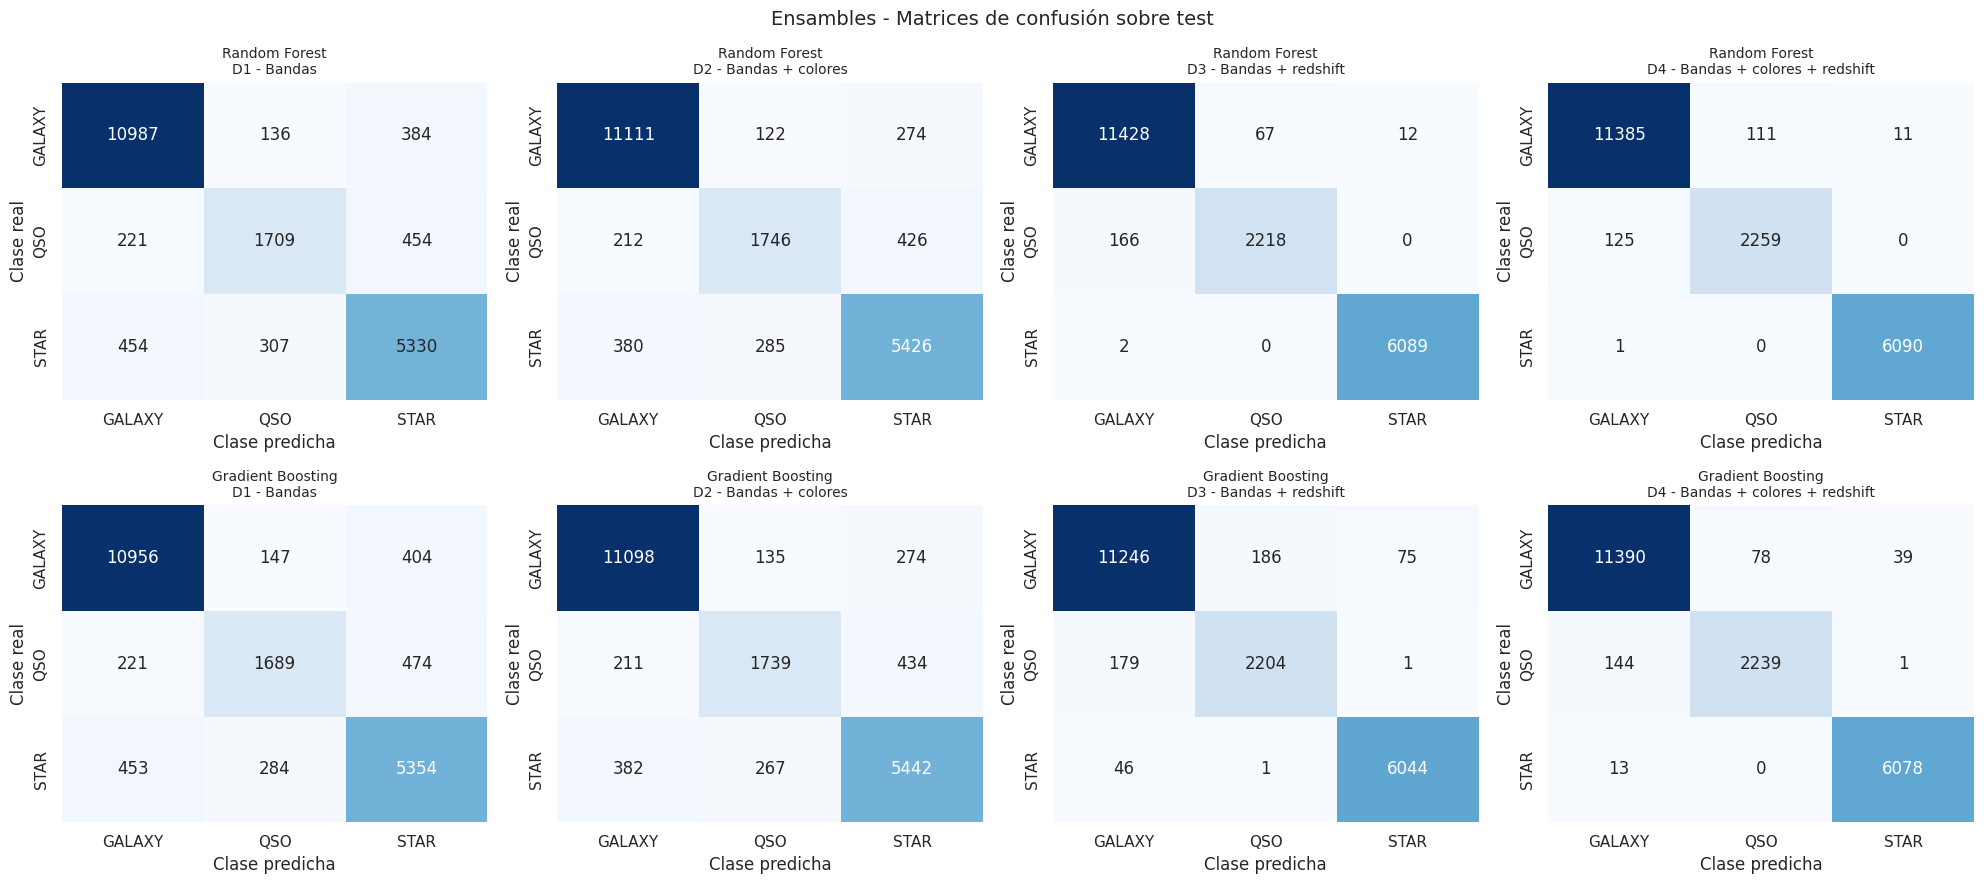

In [ ]:
# ============================================================
# ENSAMBLES - MATRICES DE CONFUSIÓN
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for fila, modelo in enumerate(ensambles):
    for col, nombre in enumerate(datasets):

        ax = axes[fila, col]
        cm = confusion_matrix(
            y_test_model,
            ens_pred[(modelo, nombre)],
            labels=clases_orden
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=clases_orden,
            yticklabels=clases_orden,
            cbar=False,
            ax=ax
        )

        ax.set_title(f"{modelo}\n{nombre}", fontsize=10)
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")

plt.suptitle("Ensambles - Matrices de confusión sobre test", fontsize=14)
plt.tight_layout()
plt.show()

#### Comentarios sobre las matrices de confusión de los ensambles

Se repite el patrón del árbol. Sin `redshift`, unos 430 a 475 quásares se clasifican como estrellas en cada modelo. Con `redshift`, ese error baja a 0 o 1 caso, excepto en Gradient Boosting D3, que además clasifica 46 estrellas como galaxias. El error restante en D3 y D4 es de quásares clasificados como galaxias: 166 y 125 en Random Forest, y 179 y 144 en Gradient Boosting.

## 7.5. Comparación de todos los algoritmos

Con los árboles y los ensambles ya evaluados, se comparan los cinco algoritmos (KNN, SVM, Árbol de decisión, Random Forest y Gradient Boosting) sobre los cuatro datasets. La métrica es el **F1 ponderado sobre `test`**, la misma que se usó en KNN y SVM, y se mantiene el baseline de `redshift` como referencia.

Esta tabla alimenta el requisito 4 (comparación y justificación del algoritmo elegido). Al compararla, además del F1, hay que tener presente el costo computacional de cada modelo: KNN y el árbol se entrenan en segundos, el SVM y los ensambles requirieron una búsqueda sobre una submuestra.

                                     KNN     SVM  Árbol de decisión  Random Forest  Gradient Boosting
D1 - Bandas                       0.8972  0.9064             0.8704         0.9011             0.8997
D2 - Bandas + colores             0.9079  0.9145             0.9023         0.9139             0.9137
D3 - Bandas + redshift            0.9753  0.9825             0.9846         0.9875             0.9756
D4 - Bandas + colores + redshift  0.9684  0.9791             0.9867         0.9876             0.9862

Baseline (solo redshift): 0.7634


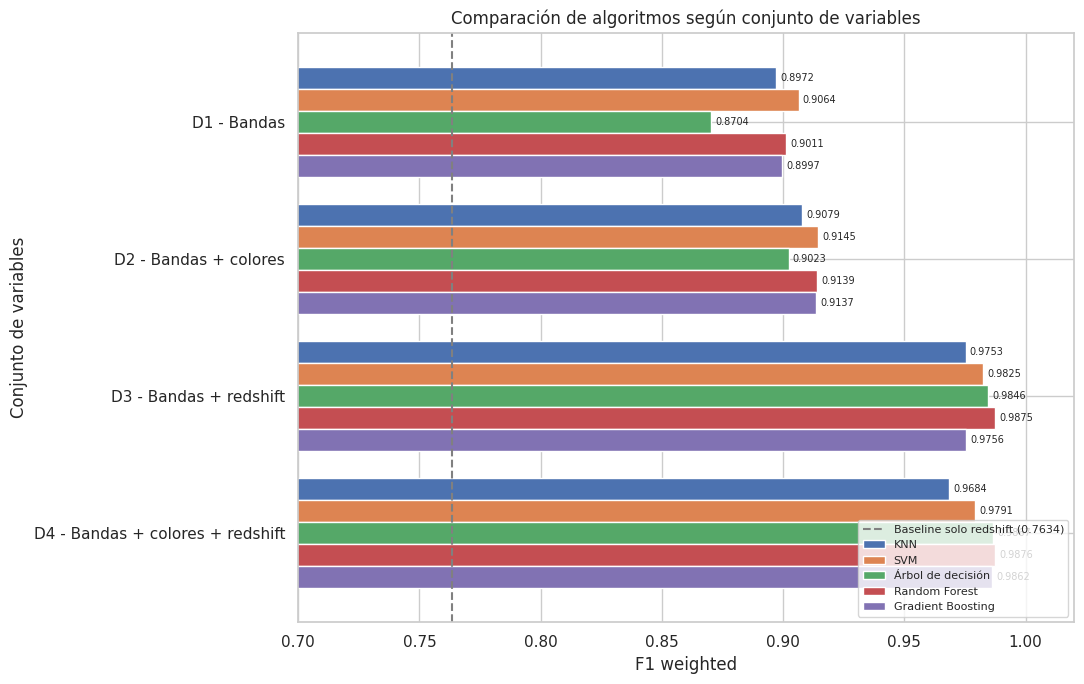

In [ ]:
# ============================================================
# COMPARACIÓN FINAL DE LOS CINCO ALGORITMOS (F1 WEIGHTED SOBRE TEST)
# ============================================================

nombres_ds = list(datasets.keys())

comparacion_algoritmos = pd.DataFrame({
    "KNN": [f1_weighted_d1, f1_weighted_d2, f1_weighted_d3, f1_weighted_d4],
    "SVM": [f1_weighted_svm_d1, f1_weighted_svm_d2, f1_weighted_svm_d3, f1_weighted_svm_d4],
    "Árbol de decisión": [resultados_arbol.loc[n, "F1 weighted"] for n in nombres_ds],
    "Random Forest": [resultados_ens.loc[("Random Forest", n), "F1 weighted"] for n in nombres_ds],
    "Gradient Boosting": [resultados_ens.loc[("Gradient Boosting", n), "F1 weighted"] for n in nombres_ds],
}, index=nombres_ds)

print(comparacion_algoritmos.round(4))
print(f"\nBaseline (solo redshift): {f1_baseline:.4f}")

ax = comparacion_algoritmos.plot(
    kind="barh",
    figsize=(11, 7),
    width=0.8
)

ax.axvline(
    f1_baseline,
    color="gray",
    linestyle="--",
    label=f"Baseline solo redshift ({f1_baseline:.4f})"
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.4f", padding=3, fontsize=7)

ax.set_xlim(0.70, 1.02)
ax.set_xlabel("F1 weighted")
ax.set_ylabel("Conjunto de variables")
ax.set_title("Comparación de algoritmos según conjunto de variables")
ax.invert_yaxis()
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

#### Comentarios sobre la comparación de los cinco algoritmos

Sin `redshift`, SVM obtiene el mejor F1 ponderado (0.9064 en D1 y 0.9145 en D2), con Random Forest y Gradient Boosting muy cerca. Con `redshift`, Random Forest es el mejor (0.9875 en D3 y 0.9876 en D4).

Un resultado nuevo respecto de KNN y SVM: en esos dos algoritmos el F1 bajaba al pasar de D3 a D4 (por ejemplo, KNN de 0.9753 a 0.9684). En el árbol (0.9846 a 0.9867), Random Forest (0.9875 a 0.9876) y Gradient Boosting (0.9756 a 0.9862) no baja, y en Gradient Boosting mejora. Los modelos de árboles toleran bien las variables redundantes, ya que pueden ignorarlas al dividir. Todos los modelos superan con holgura al baseline de solo `redshift` (0.7634).

In [ ]:
# ============================================================
# COMPARACIÓN - MEJOR ALGORITMO POR DATASET Y F1 MACRO
# ============================================================

mejor_por_dataset = pd.DataFrame({
    "Mejor algoritmo": comparacion_algoritmos.idxmax(axis=1),
    "F1 weighted": comparacion_algoritmos.max(axis=1),
    "Rango entre algoritmos": comparacion_algoritmos.max(axis=1) - comparacion_algoritmos.min(axis=1),
})

print("Mejor algoritmo por dataset (F1 weighted):")
display(mejor_por_dataset.round(4))

# F1 macro: da el mismo peso a las tres clases, por lo que castiga más el error en QSO
comparacion_f1_macro = pd.DataFrame({
    "KNN": [f1_macro_d1, f1_macro_d2, f1_macro_d3, f1_macro_d4],
    "SVM": [f1_macro_svm_d1, f1_macro_svm_d2, f1_macro_svm_d3, f1_macro_svm_d4],
    "Árbol de decisión": [resultados_arbol.loc[n, "F1 macro"] for n in nombres_ds],
    "Random Forest": [resultados_ens.loc[("Random Forest", n), "F1 macro"] for n in nombres_ds],
    "Gradient Boosting": [resultados_ens.loc[("Gradient Boosting", n), "F1 macro"] for n in nombres_ds],
}, index=nombres_ds)

print("F1 macro sobre test:")
display(comparacion_f1_macro.round(4))

Mejor algoritmo por dataset (F1 weighted):


,Mejor algoritmo,F1 weighted,Rango entre algoritmos
D1 - Bandas,SVM,0.9064,0.0360
D2 - Bandas + colores,SVM,0.9145,0.0122
D3 - Bandas + redshift,Random Forest,0.9875,0.0122
D4 - Bandas + colores + redshift,Random Forest,0.9876,0.0192


F1 macro sobre test:


,KNN,SVM,Árbol de decisión,Random Forest,Gradient Boosting
D1 - Bandas,0.8502,0.8606,0.8210,0.8572,0.8553
D2 - Bandas + colores,0.8629,0.8731,0.8574,0.8718,0.8715
D3 - Bandas + redshift,0.9683,0.9745,0.9744,0.9794,0.9640
D4 - Bandas + colores + redshift,0.9621,0.9684,0.9780,0.9795,0.9788


#### Comentarios sobre el mejor algoritmo por dataset

La diferencia entre el mejor y el peor algoritmo es de 0.0360 en D1, 0.0122 en D2 y D3, y 0.0192 en D4. El salto al agregar `redshift` (de D1 a D3) es de unos 8 puntos de F1 en los mejores modelos, bastante mayor que la diferencia entre algoritmos. La elección de las variables pesa más que la elección del modelo.

En F1 macro, que da igual peso a las tres clases, SVM lidera en D1 y D2 (0.8606 y 0.8731) y Random Forest en D3 y D4 (0.9794 y 0.9795). El árbol individual es el que peor resulta sin `redshift` (0.8210 en D1).

### Cómo leer la comparación

- **Diferencia entre algoritmos vs. diferencia entre datasets.** La columna *Rango entre algoritmos* indica cuánto cambia el F1 al cambiar de algoritmo manteniendo los datos. Compararla con el salto que se produce al pasar de D1 a D3 (agregar `redshift`): en KNN y SVM ese salto fue de más de 7 puntos, mientras que el cambio de algoritmo movía alrededor de un punto.
- **¿Ayudan los ensambles?** Si Random Forest y Gradient Boosting superan al árbol individual, la ganancia proviene de reducir su varianza (bagging) o su sesgo (boosting).
- **F1 macro.** Es la métrica que más expone el desempeño sobre `QSO`. Si un algoritmo gana en F1 ponderado pero pierde en F1 macro, probablemente esté sacrificando la clase minoritaria.

# 8. Importancia de atributos

Hasta aquí se respondió *cuánto* mejora cada conjunto de variables comparando D1, D2, D3 y D4. Los modelos basados en árboles permiten responder además *cuál* variable es la que más pesa dentro de un mismo modelo. Se utilizan tres enfoques complementarios, porque cada uno tiene limitaciones distintas.

## 8.1. Importancia basada en impureza (*Mean Decrease in Impurity*)

Es la importancia que calcula directamente `feature_importances_` en los árboles y en Random Forest. Para cada variable suma cuánto redujo la impureza en todas las divisiones donde se usó, ponderando por la cantidad de observaciones involucradas, y normaliza para que el total sea 1.

**Limitaciones:**
- se calcula sobre `train`, de modo que refleja lo que el modelo *usó* para ajustarse, no necesariamente lo que *sirve para generalizar*;
- favorece a las variables continuas con muchos valores distintos;
- cuando hay variables **correlacionadas**, reparte la importancia entre ellas. Es el caso de las bandas (correlaciones superiores a 0,9 en el EDA) y de los colores, que son combinaciones de las bandas.

## 8.2. Importancia por permutación

Se mide cuánto **empeora el F1 ponderado sobre `test`** cuando se desordenan al azar los valores de una variable, rompiendo su relación con la clase. Si el desempeño cae mucho, el modelo dependía de esa variable. Es independiente del algoritmo (funciona también con Gradient Boosting, que no tiene `feature_importances_`) y se mide sobre datos que el modelo no vio. Se repite 5 veces y se informa el promedio y el desvío.

**Limitación:** con variables correlacionadas, al permutar una de ellas el modelo puede apoyarse en la otra, por lo que la caída subestima su importancia real.

## 8.3. Importancia por grupos de variables

Para evitar el problema de las variables correlacionadas, se permutan **grupos completos** de variables a la vez (con la misma permutación de filas dentro del grupo, para conservar la relación interna): *bandas*, *colores*, *fotometría (bandas + colores)* y *redshift*. Esto responde directamente a la pregunta que guía el trabajo: **cuánto aporta la fotometría y cuánto el `redshift`**.

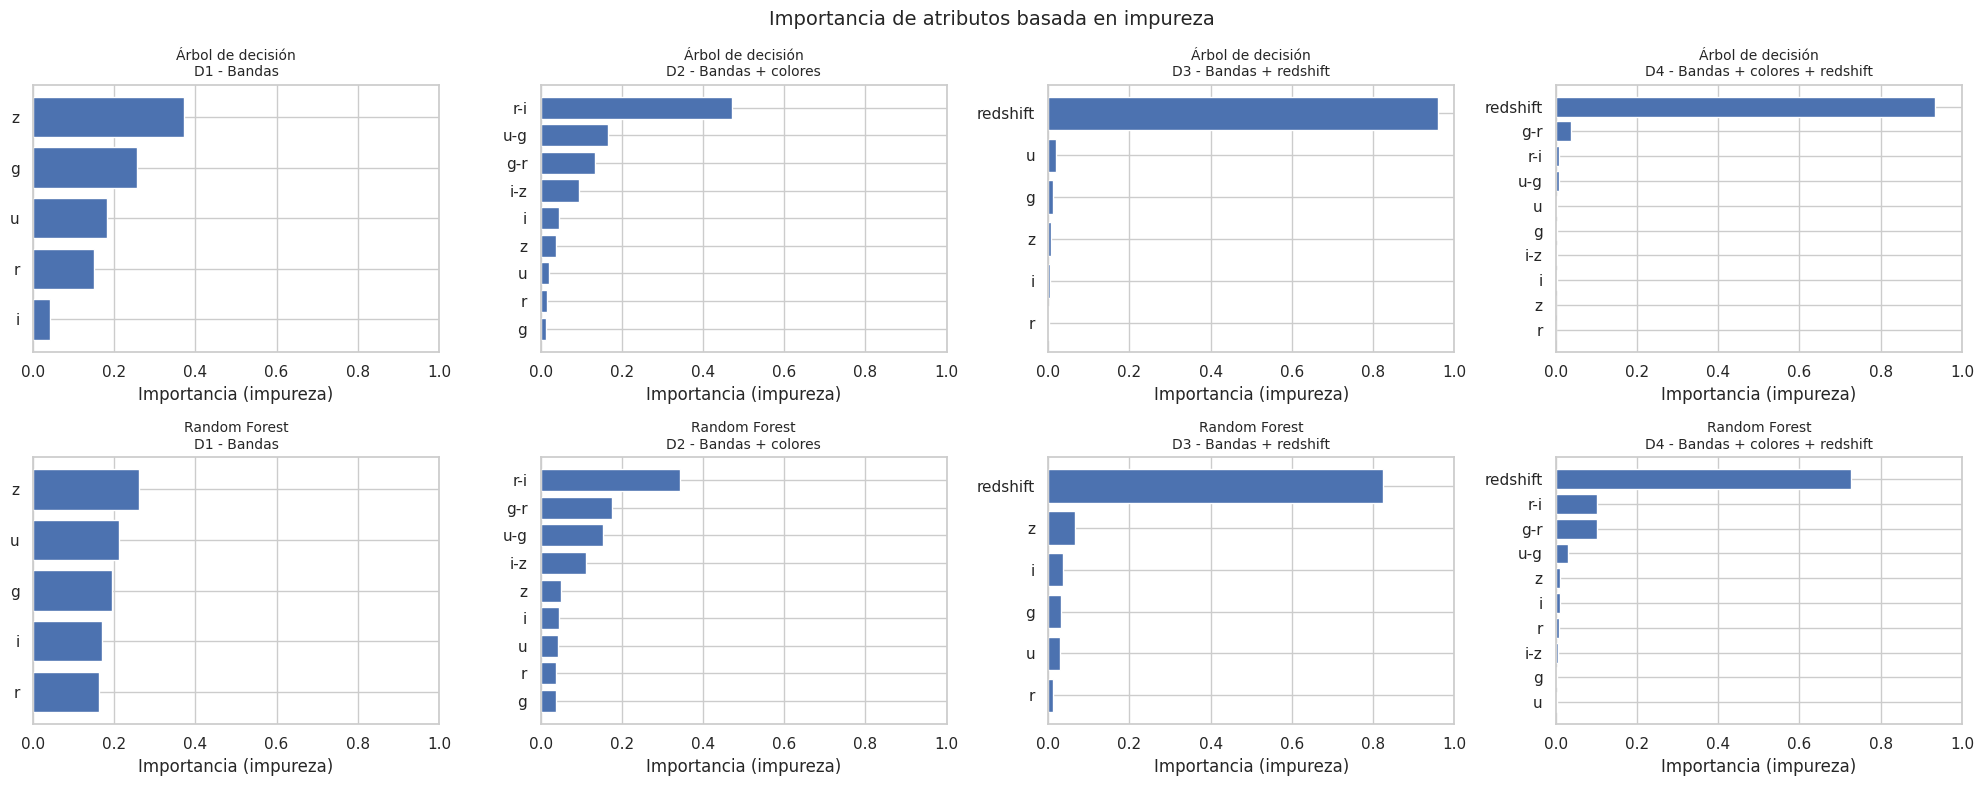

In [ ]:
# ============================================================
# IMPORTANCIA - POR IMPUREZA (ÁRBOL Y RANDOM FOREST)
# ============================================================

modelos_mdi = {
    "Árbol de decisión": {n: arbol_grids[n].best_estimator_ for n in datasets},
    "Random Forest":     {n: ens_finales[("Random Forest", n)] for n in datasets},
}

importancia_mdi = {}

for modelo, por_dataset in modelos_mdi.items():
    for nombre, est in por_dataset.items():
        columnas = list(datasets[nombre][0].columns)
        importancia_mdi[(modelo, nombre)] = pd.Series(
            est.feature_importances_, index=columnas
        ).sort_values(ascending=False)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for fila, modelo in enumerate(modelos_mdi):
    for col, nombre in enumerate(datasets):

        ax = axes[fila, col]
        serie = importancia_mdi[(modelo, nombre)].sort_values()

        ax.barh(serie.index, serie.values)
        ax.set_title(f"{modelo}\n{nombre}", fontsize=10)
        ax.set_xlabel("Importancia (impureza)")
        ax.set_xlim(0, 1)

plt.suptitle("Importancia de atributos basada en impureza", fontsize=14)
plt.tight_layout()
plt.show()

#### Comentarios sobre la importancia por impureza

Con `redshift` disponible, esta variable concentra la mayor parte de la importancia, es decir, cerca de 0.96 en el árbol de D3, 0.93 en el árbol de D4, 0.83 en el Random Forest de D3 y 0.73 en el de D4. En D2, los colores desplazan a las bandas, y `r-i` es la variable más importante en ambos modelos. En D1, la importancia se reparte entre las cinco bandas.

In [ ]:
# ============================================================
# IMPORTANCIA - POR IMPUREZA: TABLA DE RANDOM FOREST
# ============================================================

tabla_mdi_rf = pd.DataFrame(
    {nombre: importancia_mdi[("Random Forest", nombre)] for nombre in datasets}
)

print("Random Forest - importancia por impureza (cada columna suma 1):")
tabla_mdi_rf.round(4)

Random Forest - importancia por impureza (cada columna suma 1):


,D1 - Bandas,D2 - Bandas + colores,D3 - Bandas + redshift,D4 - Bandas + colores + redshift
g,0.1947,0.0370,0.0308,0.0035
g-r,NaN,0.1771,NaN,0.1002
i,0.1698,0.0454,0.0368,0.0092
i-z,NaN,0.1111,NaN,0.0063
r,0.1638,0.0387,0.0123,0.0080
r-i,NaN,0.3424,NaN,0.1009
redshift,NaN,NaN,0.8256,0.7273
u,0.2112,0.0431,0.0286,0.0034
u-g,NaN,0.1546,NaN,0.0308
z,0.2606,0.0507,0.0660,0.0105


#### Comentarios sobre la tabla de importancia del Random Forest

En D1 cada banda recibe entre 0.16 y 0.26, sin una dominante. Esto es esperable porque las bandas están muy correlacionadas, y la importancia se reparte entre ellas. En D4, `redshift` suma 0.7273, los colores suman cerca de 0.24 (`r-i` y `g-r` con 0.10 cada uno) y las bandas casi nada (0.0034 a 0.0105 cada una). El modelo prefiere los colores a las bandas cuando ambos están presentes.

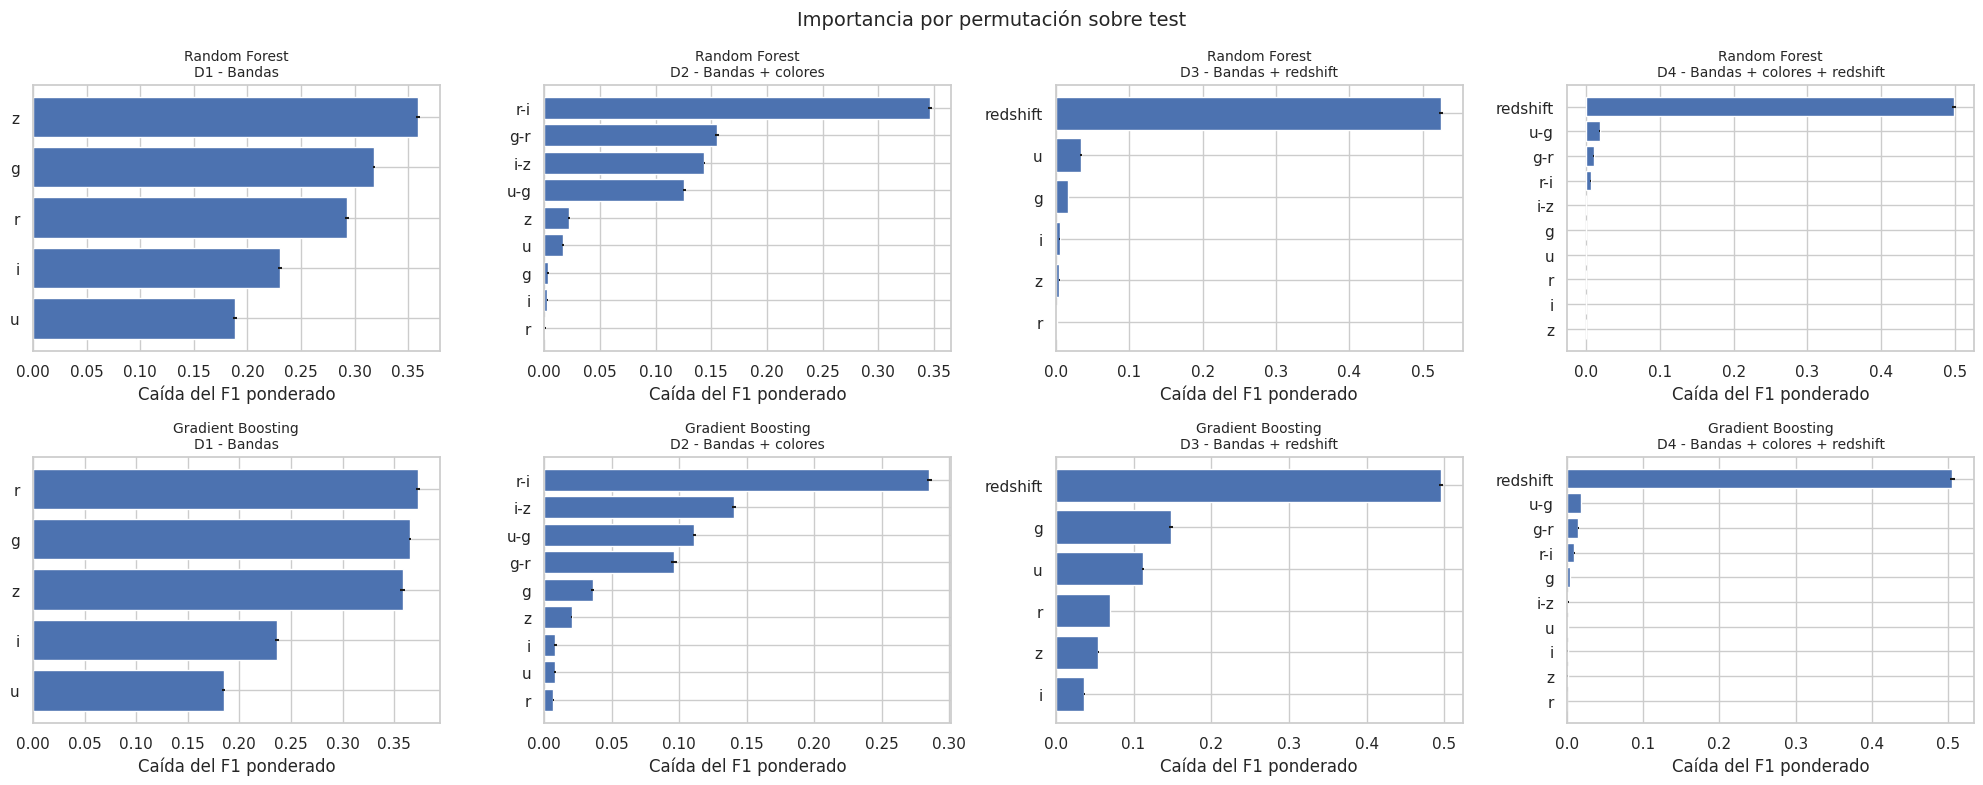

In [ ]:
# ============================================================
# IMPORTANCIA - POR PERMUTACIÓN SOBRE TEST
# ============================================================

from sklearn.inspection import permutation_importance

N_REPETICIONES = 5

modelos_perm = ["Random Forest", "Gradient Boosting"]
importancia_perm = {}

for modelo in modelos_perm:
    for nombre, (X_tr, X_te) in datasets.items():

        resultado = permutation_importance(
            ens_finales[(modelo, nombre)],
            X_te,
            y_test_model,
            scoring="f1_weighted",
            n_repeats=N_REPETICIONES,
            random_state=SEMILLA,
            n_jobs=-1
        )

        importancia_perm[(modelo, nombre)] = pd.DataFrame(
            {"media": resultado.importances_mean, "desvio": resultado.importances_std},
            index=X_te.columns
        ).sort_values("media", ascending=False)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for fila, modelo in enumerate(modelos_perm):
    for col, nombre in enumerate(datasets):

        ax = axes[fila, col]
        df_imp = importancia_perm[(modelo, nombre)].sort_values("media")

        ax.barh(df_imp.index, df_imp["media"], xerr=df_imp["desvio"])
        ax.set_title(f"{modelo}\n{nombre}", fontsize=10)
        ax.set_xlabel("Caída del F1 ponderado")

plt.suptitle("Importancia por permutación sobre test", fontsize=14)
plt.tight_layout()
plt.show()

#### Comentarios sobre la importancia por permutación

Los gráficos muestran el mismo orden general que la importancia por impureza: el `redshift` en primer lugar cuando está disponible, y los colores por encima de las bandas cuando ambos están. Los valores exactos están en las tablas siguientes.

In [ ]:
# ============================================================
# IMPORTANCIA - POR PERMUTACIÓN: TABLAS
# ============================================================

for modelo in modelos_perm:
    tabla = pd.DataFrame(
        {nombre: importancia_perm[(modelo, nombre)]["media"] for nombre in datasets}
    )
    print(f"{modelo} - caída media del F1 ponderado al permutar cada variable:")
    display(tabla.round(4))

Random Forest - caída media del F1 ponderado al permutar cada variable:


,D1 - Bandas,D2 - Bandas + colores,D3 - Bandas + redshift,D4 - Bandas + colores + redshift
g,0.3181,0.0035,0.0165,-0.0001
g-r,NaN,0.1551,NaN,0.0103
i,0.2303,0.0025,0.0055,-0.0003
i-z,NaN,0.1437,NaN,-0.0000
r,0.2928,0.0007,0.0011,-0.0002
r-i,NaN,0.3461,NaN,0.0062
redshift,NaN,NaN,0.5250,0.4982
u,0.1887,0.0170,0.0342,-0.0001
u-g,NaN,0.1256,NaN,0.0186
z,0.3592,0.0221,0.0049,-0.0003


Gradient Boosting - caída media del F1 ponderado al permutar cada variable:


,D1 - Bandas,D2 - Bandas + colores,D3 - Bandas + redshift,D4 - Bandas + colores + redshift
g,0.3650,0.0359,0.1481,0.0037
g-r,NaN,0.0963,NaN,0.0143
i,0.2364,0.0082,0.0365,0.0005
i-z,NaN,0.1408,NaN,0.0016
r,0.3733,0.0067,0.0701,0.0002
r-i,NaN,0.2854,NaN,0.0090
redshift,NaN,NaN,0.4960,0.5055
u,0.1849,0.0079,0.1116,0.0006
u-g,NaN,0.1112,NaN,0.0181
z,0.3582,0.0201,0.0547,0.0004


#### Comentarios sobre las tablas de permutación

Al permutar el `redshift`, el F1 cae unos 0.50 en los dos modelos, tanto en D3 como en D4. Ninguna otra variable individual se acerca a ese valor. En D2, las caídas mayores corresponden a colores (`r-i` con 0.3461 en Random Forest) y las bandas casi no importan (menos de 0.03). En D4, los colores aportan una caída pequeña (como máximo 0.019) y las bandas prácticamente cero, porque el modelo ya recibe esa información en los colores.

En D3, Gradient Boosting depende más de las bandas que Random Forest (por ejemplo, `g` con 0.1481 frente a 0.0165). Los dos modelos coinciden en lo principal, pero reparten el trabajo de forma distinta. En D1 las caídas individuales son altas (0.19 a 0.37), lo que indica que sin otra fuente de información el modelo depende de todas las bandas.

In [ ]:
# ============================================================
# IMPORTANCIA - POR GRUPOS DE VARIABLES
# ============================================================
# Se permuta cada grupo completo con la MISMA permutación de filas,
# para conservar la relación entre las variables del grupo.

grupos_por_dataset = {
    "D1 - Bandas": {
        "Bandas": features_bands
    },
    "D2 - Bandas + colores": {
        "Bandas": features_bands,
        "Colores": features_colors,
        "Fotometría (bandas + colores)": features_bands + features_colors
    },
    "D3 - Bandas + redshift": {
        "Bandas": features_bands,
        "Redshift": features_redshift
    },
    "D4 - Bandas + colores + redshift": {
        "Bandas": features_bands,
        "Colores": features_colors,
        "Fotometría (bandas + colores)": features_bands + features_colors,
        "Redshift": features_redshift
    },
}


def importancia_por_grupo(modelo, X_te, y_te, grupos, n_repeticiones=5, semilla=SEMILLA):
    # Caída del F1 ponderado al permutar cada grupo de columnas.
    rng = np.random.default_rng(semilla)
    base = f1_score(y_te, modelo.predict(X_te), average="weighted")

    filas = []
    for grupo, columnas in grupos.items():
        caidas = []
        for _ in range(n_repeticiones):
            X_perm = X_te.copy()
            orden = rng.permutation(len(X_perm))
            X_perm[columnas] = X_te[columnas].to_numpy()[orden]
            caidas.append(base - f1_score(y_te, modelo.predict(X_perm), average="weighted"))
        filas.append({"Grupo": grupo, "Caída media F1": np.mean(caidas), "Desvío": np.std(caidas)})

    return pd.DataFrame(filas).set_index("Grupo")


filas_grupos = []

for modelo in modelos_perm:
    for nombre, (X_tr, X_te) in datasets.items():

        tabla = importancia_por_grupo(
            ens_finales[(modelo, nombre)],
            X_te,
            y_test_model,
            grupos_por_dataset[nombre]
        )
        tabla["Modelo"] = modelo
        tabla["Dataset"] = nombre
        filas_grupos.append(tabla.reset_index())

importancia_grupos = pd.concat(filas_grupos, ignore_index=True)

importancia_grupos = importancia_grupos.set_index(["Modelo", "Dataset", "Grupo"])
importancia_grupos.round(4)

Caída media F1  Desvío
Modelo            Dataset                          Grupo                                                
Random Forest     D1 - Bandas                      Bandas                                 0.4615  0.0025
                  D2 - Bandas + colores            Bandas                                 0.1749  0.0029
                                                   Colores                                0.4849  0.0032
                                                   Fotometría (bandas + colores)          0.4710  0.0008
                  D3 - Bandas + redshift           Bandas                                 0.1009  0.0015
                                                   Redshift                               0.5278  0.0030
                  D4 - Bandas + colores + redshift Bandas                                 0.0007  0.0003
                                                   Colores                                0.0974  0.0010
                                                   Fotometría (bandas + colores)          0.0888  0.0011
                                                   Redshift                               0.4994  0.0029
Gradient Boosting D1 - Bandas                      Bandas                                 0.4597  0.0024
                  D2 - Bandas + colores            Bandas                                 0.1296  0.0020
                                                   Colores                                0.4716  0.0027
                                                   Fotometría (bandas + colores)          0.4717  0.0010
                  D3 - Bandas + redshift           Bandas                                 0.1079  0.0016
                                                   Redshift                               0.4976  0.0036
                  D4 - Bandas + colores + redshift Bandas                                 0.0069  0.0005
                                                   Colores                                0.0742  0.0008
                                                   Fotometría (bandas + colores)          0.0712  0.0011
                                                   Redshift                               0.5068  0.0032

#### Comentarios sobre la importancia por grupos

Esta tabla responde de forma directa a la pregunta del trabajo. En D4, permutar el `redshift` baja el F1 en unos 0.50 (0.4994 en Random Forest y 0.5068 en Gradient Boosting). Permutar toda la fotometría lo baja entre 0.07 y 0.09 (0.0888 y 0.0712). Cuando el `redshift` está presente, la fotometría aporta poco en comparación.

Sin `redshift`, toda la información está en la fotometría. En D1 y D2, permutar el grupo completo baja el F1 entre 0.46 y 0.47. En D2 el grupo de colores pesa más que el de bandas (0.4849 frente a 0.1749 en Random Forest), lo que concuerda con la mejora de D1 a D2. En D4, permutar solo las bandas casi no tiene efecto (0.0007 y 0.0069), porque los colores contienen la misma información.

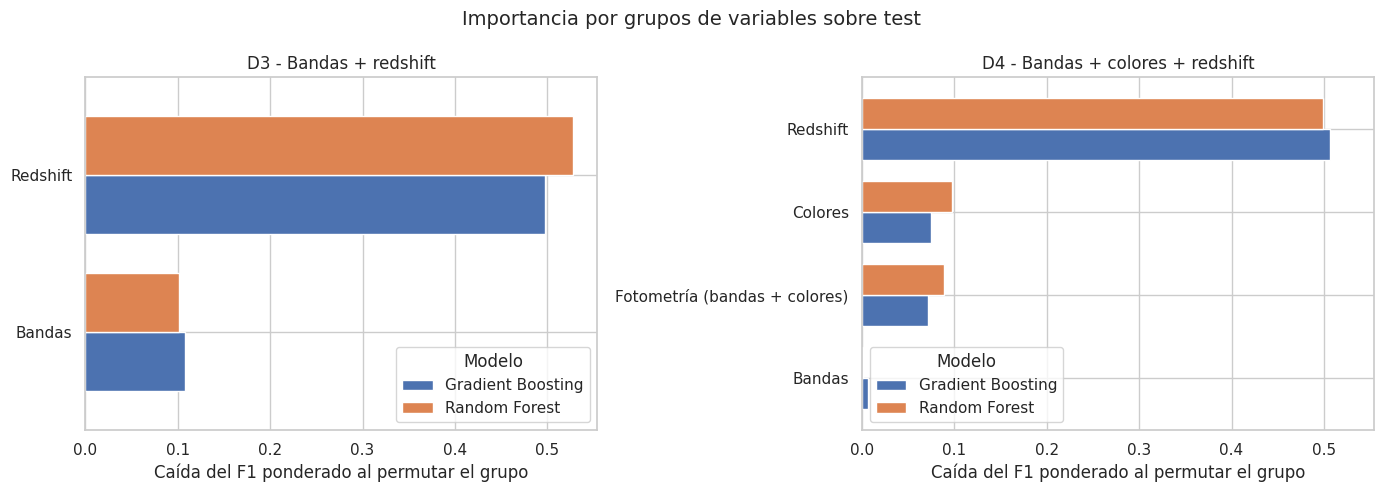

In [ ]:
# ============================================================
# IMPORTANCIA - POR GRUPOS: GRÁFICO PARA D3 Y D4
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, nombre in zip(axes, ["D3 - Bandas + redshift", "D4 - Bandas + colores + redshift"]):

    tabla = importancia_grupos.xs(nombre, level="Dataset")["Caída media F1"].unstack("Modelo")
    tabla = tabla.sort_values(tabla.columns[0])

    tabla.plot(kind="barh", ax=ax, width=0.75)

    ax.set_title(nombre)
    ax.set_xlabel("Caída del F1 ponderado al permutar el grupo")
    ax.set_ylabel("")

plt.suptitle("Importancia por grupos de variables sobre test", fontsize=14)
plt.tight_layout()
plt.show()

#### Comentarios sobre el gráfico por grupos

En D3 y D4 la barra del `redshift` es la más larga en ambos modelos, con una caída de alrededor de 0.5. Las barras de bandas y colores son varias veces más cortas. El gráfico resume la conclusión de la sección: el `redshift` es la variable que más separa las clases, y la fotometría cumple un papel secundario cuando se dispone de él.

### Cómo leer la importancia de atributos

Una vez ejecutadas las celdas anteriores, estas son las preguntas que ordenan el análisis:

1. **¿Qué variable domina cuando está disponible?** Comparar D3 y D4: si el `redshift` concentra casi toda la importancia (en impureza y en permutación), el modelo está resolviendo el problema principalmente con una sola variable espectroscópica.
2. **¿Qué ocurre sin `redshift`?** En D1 y D2 la importancia se reparte entre las bandas o los colores. Identificar cuáles pesan más y cotejarlo con lo observado en el EDA (`u-g` separaba los `QSO`; `g-r` y `r-i` separaban las galaxias).
3. **¿Coinciden los dos métodos?** Si el orden de variables por impureza y por permutación difiere, suele deberse a la correlación entre variables: la impureza reparte el mérito entre variables redundantes y la permutación subestima a cada una porque el modelo se apoya en las otras.
4. **¿Qué dice la importancia por grupos?** Es la medida más directa para la pregunta de investigación: la caída del F1 al permutar el `redshift` frente a la caída al permutar la fotometría completa. En D4, la caída del grupo *Bandas* por separado puede ser pequeña porque los *Colores* conservan esa información; el grupo *Fotometría (bandas + colores)* muestra el aporte real de la información fotométrica.
5. **Conexión con D3 vs. D4.** Si los colores aparecen con importancia no nula en D4 pero el F1 no mejora respecto de D3, confirma que son una reescritura de las bandas: el modelo los usa, pero no le agregan información nueva.

Estas lecturas deben completarse con los valores concretos obtenidos en la ejecución antes de incorporarlas a las conclusiones finales.

## Estado del proyecto y próximos pasos



Hasta este punto se completaron las etapas necesarias para preparar los datos y evaluar KNN como primer algoritmo de clasificación.

| Bloque | Estado | Comentario |
|---|:---:|---|
| Fuente de los datos y propuesta de investigación | ✅ | SDSS DR17 y pregunta de investigación definida |
| Carga y análisis inicial del conjunto de datos | ✅ | Dataset y variables documentados |
| Análisis exploratorio (EDA) | ✅ | Distribuciones, clases, colores y relaciones entre variables |
| Limpieza de datos | ✅ | Valores inválidos y duplicados tratados |
| Definición de variables para modelado | ✅ | D1, D2, D3 y D4 definidos |
| Partición entrenamiento / test | ✅ | Split estratificado y común para los cuatro datasets |
| Baseline | ✅ | Regla basada únicamente en `redshift`, construida utilizando solo `train` |
| KNN | ✅ | GridSearchCV + validación cruzada de 5 folds |
| Comparación D1–D4 para KNN | ✅ | Evaluación mediante métricas y análisis de resultados |
| Comparación Baseline vs. KNN | ✅ | Comparación utilizando F1 weighted |
| **SVM** | ✅ | Modelo implementado |
| **Árboles de decisión** | ✅ | Modelo implementado |
| **Ensambles e importancia de atributos** | ✅ | Terminado |
| Comparación final de algoritmos | ⬜ | Se realizará una vez completados los modelos |
| Reflexión y propuestas de mejora | ⬜ | Se completará al finalizar el modelado |

### Continuidad del modelado

Para los próximos algoritmos se reutilizarán las mismas particiones de entrenamiento y prueba y los cuatro conjuntos de variables:

- D1: bandas
- D2: bandas + colores
- D3: bandas + redshift
- D4: bandas + colores + redshift

De esta manera, SVM y los demás modelos podrán compararse con KNN bajo las mismas condiciones y utilizando las mismas métricas.

El baseline basado únicamente en `redshift` también se mantendrá como referencia común.